# Human players: how intermediate players wait

Follow-up to `strategy_characterisation.ipynb` (same folder), which labels players from the fraction of their trials below one boundary (at most 20% peripheral = central, at least 80% = peripheral, otherwise intermediate). That label says how often a player waits at the wall. It says nothing about how far from the boundary they wait, so it cannot tell a player who mixes the centre and the wall from one who waits near the boundary.

**Plan**
1. Context, player means and the fixed cut (copied from section 3a of `strategy_characterisation`).
2. Mean and spread of each player's trials (exploratory).
3. Each player's own wall and centre positions, and the gap between them.
4. A soft centre weight per player, from mode shapes shared by all players.
5. Labels for mixed players from how their position changes over the session (switcher, drifter, hoverer, mixer).
5. Labels for intermediate players from how their position changes over the session (switcher, drifter, hoverer, mixer).

**Choices**
- Trials, the boundary (fitted on social) and the fixed-cut labels are built as in `strategy_characterisation`, except that the spawn trial is dropped (the first trial of each social and second-solo session, where players start at the arena centre). `strategy_characterisation` keeps it, so the boundary and labels here can differ slightly from it.
- Everything that computes a number comes from `analysis/human_characterisation.py` (sections 1 to 3) and `analysis/centrality_mixture.py` (section 4) and `analysis/mixed_labels.py` (section 5).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import data_extraction.data_saving as data_saving
import analysis.human_characterisation as hc
import analysis.centrality_mixture as cm
import analysis.mixed_labels as ml

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

RECOMPUTE = False           # rebuild the cached tables and redraws
N_PERM_DRIFT = 1000         # block redraws per player for the intervals

LABELS = hc.SESSION_LABELS
STRAT_ORDER = ['central', 'intermediate', 'peripheral']


def fixed_labels(frac_peripheral):
    """ Return fixed-cut labels, with 'intermediate' for players between the cuts. Takes the fractions of peripheral
        trials.

        hc.fixed_cut_labels calls this group 'mixed'. It is renamed here so it is not confused with the mixer
        label of section 5. """

    return hc.fixed_cut_labels(frac_peripheral).replace({'mixed': 'intermediate'})

## Load data

The onset table holds one row per trial per player at slice onset. The spawn trial (the first trial of each social and second-solo session) is dropped, as players start it at the arena centre rather than choosing where to wait. The first solo already starts after a 5-trial cut, so it has no spawn trial. No other trials are dropped. Trials are labelled peripheral below the one boundary fitted on social trials, and players get their fixed-cut label from the fraction of peripheral trials (as in `strategy_characterisation` sections 2 and 3a).

In [2]:
# get the onset table, and drop the spawn trial (first trial of each social and second-solo session)
onset = hc.load_tables(recompute=RECOMPUTE)['onset']
spawn = onset['session_type'].isin(['social', 'solo2']) & (onset['trial_pos'] == 0)
print('spawn trials dropped:', onset[spawn].groupby('session_type').size().to_dict())
onset = onset[~spawn]

# flag peripheral trials with the social boundary, and label players with the fixed cut
onset, split = hc.fit_trial_split(onset)
players = hc.player_table(onset)
players['fixed'] = fixed_labels(players['frac_peripheral'])
print(f"boundary {split['boundary']:.3f}, fitted on {LABELS[split['reference']]} trials")
players.groupby(['session_type', 'fixed']).size().unstack().loc[list(hc.SESSION_TYPES)]

human_onset_tables: loaded from cache
spawn trials dropped: {'social': 200, 'solo2': 200}


boundary 0.484, fitted on social trials


fixed,central,intermediate,peripheral
session_type,,,
solo1,100,67,33
social,95,69,36
solo2,87,54,59


## 1. Player means and the fixed cut

Copied from section 3a of `strategy_characterisation` for context.

The fixed cut counts each player's trial labels from section 2 of `strategy_characterisation`. A player is central if at most 20% of their trials are peripheral, peripheral if at least 80% are, and intermediate otherwise. It needs no fitting, so it is the working label there.

The left panel shows where each label sits on player mean centrality. The right panel shows that the two summaries track each other closely, so little is lost by counting trials instead of averaging them.

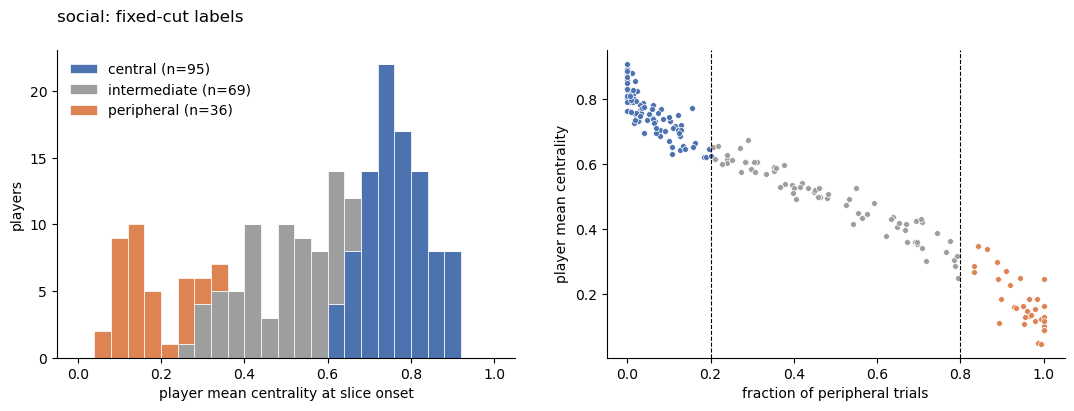

In [3]:
def plot_fixed_cut(st):
    """ Plot the fixed-cut labels two ways, as a histogram of player mean centrality and as mean
        centrality against the fraction of peripheral trials. Takes a session type.

        One point or one player in each panel. Dashed lines in the right panel mark the cuts. """

    sub = players[players['session_type'] == st]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # plot a stacked histogram of player means by label
    bins = np.linspace(0, 1, 26)
    axes[0].hist([sub.loc[sub['fixed'] == lab, 'mean_centrality'] for lab in STRAT_ORDER], bins=bins, stacked=True,
                 color=[hc.STRAT_PALETTE[lab] for lab in STRAT_ORDER], edgecolor='white', linewidth=0.5,
                 label=[f"{lab} (n={(sub['fixed'] == lab).sum()})" for lab in STRAT_ORDER])
    axes[0].set_xlabel('player mean centrality at slice onset')
    axes[0].set_ylabel('players')
    axes[0].legend(frameon=False)

    # plot mean centrality against fraction of peripheral trials, with the cuts
    for lab in STRAT_ORDER:
        s = sub[sub['fixed'] == lab]
        axes[1].scatter(s['frac_peripheral'], s['mean_centrality'], s=18, color=hc.STRAT_PALETTE[lab],
                        edgecolor='white', linewidth=0.5, label=lab)
    for cut in hc.FIXED_CUTS:
        axes[1].axvline(cut, color='k', ls='--', lw=0.8)
    axes[1].set_xlabel('fraction of peripheral trials')
    axes[1].set_ylabel('player mean centrality')
    for ax in axes:
        ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle(f'{LABELS[st]}: fixed-cut labels', x=0.125, ha='left')
    plt.show()


plot_fixed_cut('social')

**Interpretation**

- Player mean and fraction of peripheral trials track each other closely, so the fixed cut orders players almost exactly as their means do.
- Central players (95) form a tight group with means of 0.6 to 0.9. Peripheral players (36) sit at 0.05 to 0.35.
- Intermediate players (69) fill the range between. Their mean alone cannot tell a player who mixes centre and wall from one who waits at intermediate positions (section 4c of `strategy_characterisation` looks at how they mix, and this notebook at where they wait).

## 2. Mean and spread (exploratory)

**This plot is exploratory only, and quite misleading. A player's height against the grey curve mixes how often they switch with how extreme their own positions are. It says little about intermediate players, and misreads players at either end of the centrality range.**

Each point is one player, with the SD of their onset centrality (population SD) against their mean.

- The dashed curve is the largest SD possible at each mean. A player split between the alcove back (0) and the arena centre (1) reaches it.
- The grey curve is a player who only ever waits at two spots, 0.11 (the wall peak) and 0.84 (the centre peak) of the social trial histogram. The only thing they choose is how often they use each, so each point on the curve is a different share of wall trials (50/50 at the top). The use of peak positions is an assumption. A player alternating between two less extreme positions sits below the curve without any trials in the middle.

`spread_ratio` in the player table is SD divided by the dashed curve (1 = split between 0 and 1, 0 = always one spot).

**How to read the figure**
- One point is one player. One panel per session type. Colour is the fixed-cut label.
- x is the player's mean onset centrality (1 = arena centre, 0 = alcove back). y is the SD of their onset centrality.
- A point near the grey curve spreads as much as a player who only waits at the two peaks. A point near the bottom always waits in about the same spot.

**Why it is plotted.** Two intermediate players can share a mean. One mixes the centre and the wall, the other waits near the boundary. The question is whether their spread tells them apart. The table gives each intermediate player's SD as a share of the grey curve (`sd_vs_two_peaks`, 1 = on the curve).

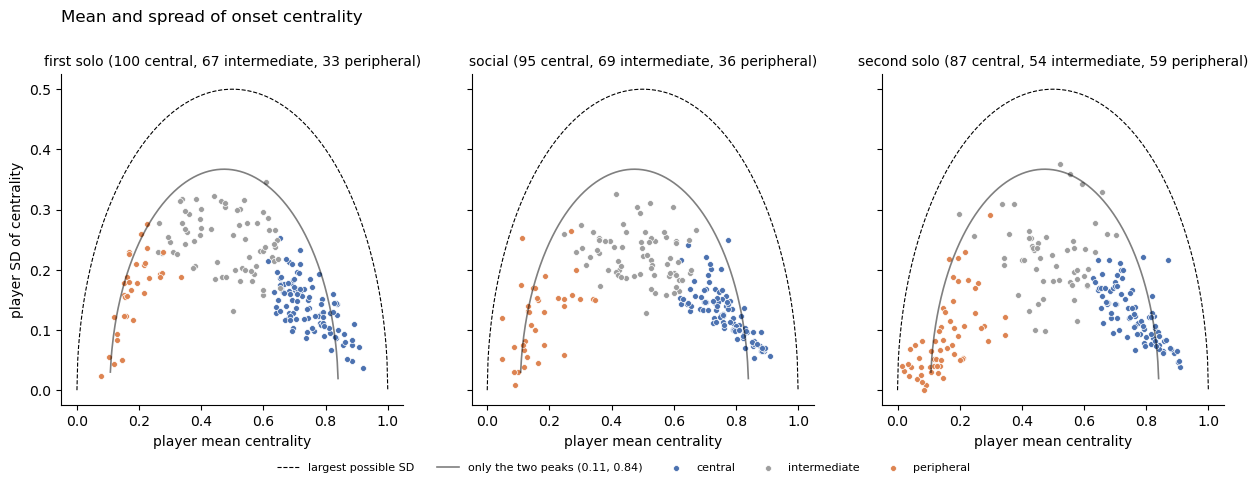

,players,below_curve,median,min,max
session_type,,,,,
solo1,67,66,0.73,0.36,1.01
social,69,69,0.63,0.35,0.90
solo2,54,50,0.63,0.27,1.20


In [4]:
# find the two onset peaks on social trials, where players most often wait
peak_low, peak_high = hc.mode_peaks(onset, split['boundary'])
players['two_position_sd'] = hc.two_position_sd(players['mean_centrality'], peak_low, peak_high)


def plot_spread():
    """ Plot each player's SD of onset centrality against their mean, one panel per session type.
        Takes no arguments.

        The dashed curve is the largest SD possible at each mean. The grey curve is the SD of a player
        who only waits at the two peaks. """

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharex=True, sharey=True)
    grid = np.linspace(0, 1, 401)
    for ax, st in zip(axes, hc.SESSION_TYPES):
        sub = players[players['session_type'] == st]
        # plot the two reference curves
        ax.plot(grid, np.sqrt(grid * (1 - grid)), color='k', ls='--', lw=0.8, label='largest possible SD')
        ax.plot(grid, hc.two_position_sd(grid, peak_low, peak_high), color='k', lw=1.2, alpha=0.5,
                label=f'only the two peaks ({peak_low:.2f}, {peak_high:.2f})')
        # plot one point per player, coloured by fixed-cut label
        for lab in STRAT_ORDER:
            s = sub[sub['fixed'] == lab]
            ax.scatter(s['mean_centrality'], s['sd_pop_centrality'], s=18, color=hc.STRAT_PALETTE[lab],
                       edgecolor='white', linewidth=0.5, label=lab)
        counts = ', '.join(f"{(sub['fixed'] == lab).sum()} {lab}" for lab in STRAT_ORDER)
        ax.set_title(f'{LABELS[st]} ({counts})', fontsize=10)
        ax.set_xlabel('player mean centrality')
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylabel('player SD of centrality')
    handles, names = axes[0].get_legend_handles_labels()
    fig.legend(handles, names, frameon=False, fontsize=8, ncol=5, loc='upper center', bbox_to_anchor=(0.5, 0))
    fig.suptitle('Mean and spread of onset centrality', x=0.125, y=1.03, ha='left')
    plt.show()


plot_spread()

# compare each intermediate player's SD with a player who only waits at the two peaks
intermediate = players[players['fixed'] == 'intermediate'].assign(
    sd_vs_two_peaks=lambda d: d['sd_pop_centrality'] / d['two_position_sd'])
(intermediate.groupby('session_type')['sd_vs_two_peaks']
 .agg(players='size', below_curve=lambda r: int((r < 1).sum()), median='median', min='min', max='max')
 .loc[list(hc.SESSION_TYPES)].round(2))

**Interpretation**

- Every social intermediate player sits below the grey curve (69 of 69, and 66 of 67 first solo, 50 of 54 second solo). This only shows they do not switch between exactly 0.11 and 0.84. They may still switch between two less extreme positions.
- Peripheral players lie near the curve because their own wall position is close to the wall peak (social median 0.13, against 0.11, table in section 3). They cross to the centre side on few trials (median 5, against 131 on the wall side), but those crossings give most of their variance (median switch share 0.58).
- Central players mostly sit below the curve because their own centre position (social median 0.78) is less central than the 0.84 peak. Most of their variance is within the centre side (median switch share 0.29), and they cross to the wall side on a median of 4 trials.
- Section 3 measures each player's own two positions instead.

## 3. Each player's own wall and centre positions

Each player's trials are split at the boundary from section 2 of `strategy_characterisation`. The mean of each side is that player's own wall and centre position, and the gap is the distance between them. A side needs at least 5 trials (`SIDE_MIN_TRIALS`) to get a position, so most central and peripheral players, who rarely cross the boundary, have no gap.

`switch_share` is the share of a player's variance that comes from moving between the two sides, rather than moving within one. It uses every trial, so every player has one.

The figure shows both positions for each social player with a gap, as mean ± SD (left) and as median with IQR (right). Comparing the two panels shows how much outliers move the positions. The table covers every player.

**How to read the figure**
- One row is one social player with at least 5 trials on each side, sorted by fraction of peripheral trials (most peripheral at the top). Labels on the left name the fixed-cut groups, and the black horizontal lines separate them (the 20% and 80% cuts).
- The orange dot is the player's own wall position (mean or median of their trials below the boundary). The blue dot is their own centre position (trials at or above it).
- The pale bar around each dot is the spread of that side (SD either side of the mean on the left, IQR on the right). The grey bar joining the two dots is the gap.
- The dashed vertical line is the trial boundary (0.484 here, fitted on social as in `strategy_characterisation` section 2).

**Why it is plotted.** The fixed cut says how often a player crosses the boundary, not how far each side sits from it. A player with dots far from the dashed line uses two distinct positions. A player with dots close to it waits near the boundary on both sides.

**How to read the table** (medians across players): `wall_mean` and `centre_mean` are the side positions, `n_wall` and `n_centre` the trials on each side, and `switch_share` the share of variance from moving between sides (1 = all of it, 0 = none).

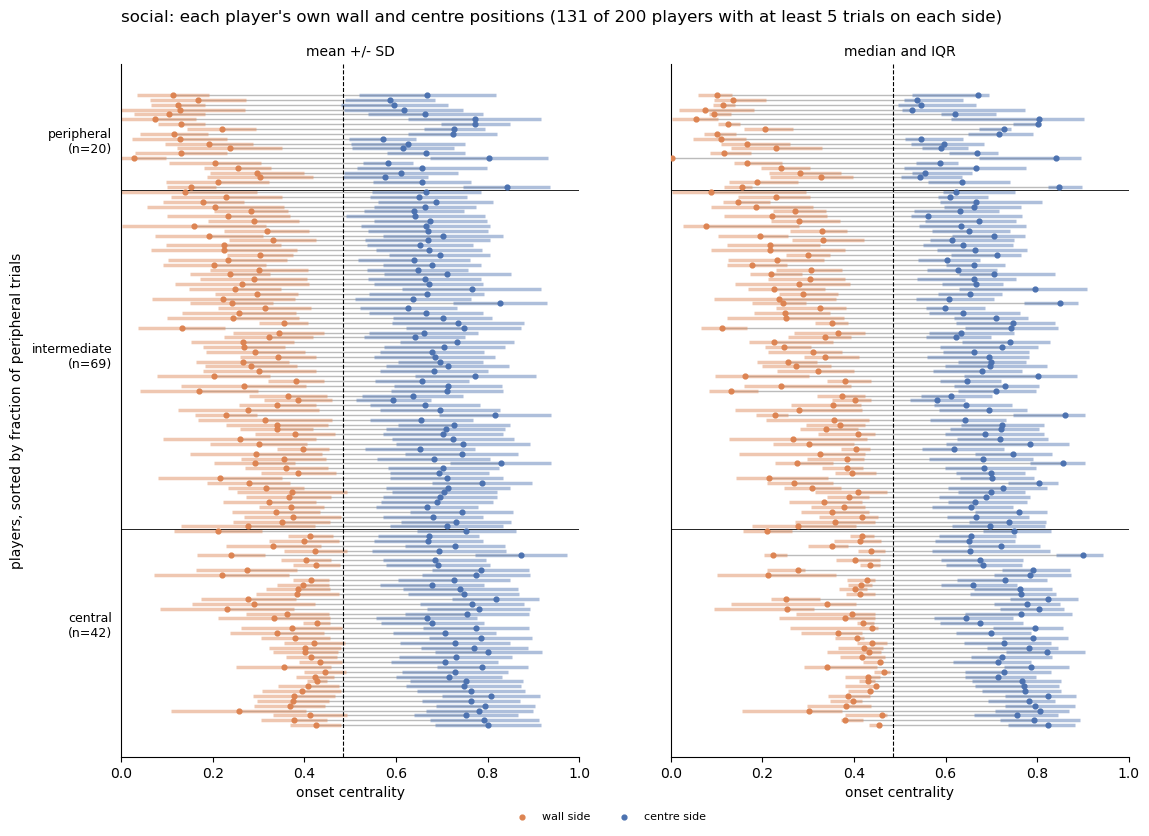

players  wall_mean  centre_mean  n_wall  n_centre  switch_share
solo1  central           100       0.35         0.76     3.0      49.5          0.42
       intermediate       67       0.24         0.71    24.0      25.0          0.73
       peripheral         33       0.13         0.70    51.0       3.0          0.77
social central            95       0.39         0.78     4.0     124.0          0.29
       intermediate       69       0.29         0.69    61.0      69.0          0.70
       peripheral         36       0.13         0.66   131.0       5.0          0.58
solo2  central            87       0.36         0.78     1.0      55.0          0.26
       intermediate       54       0.29         0.69    25.0      29.5          0.71
       peripheral         59       0.13         0.76    57.0       0.0          0.00

In [5]:
# get each player's own wall and centre positions (trials either side of the boundary) and the gap between them
sides = hc.side_positions(onset, split['boundary']).merge(
    players[['experiment', 'player', 'session_type', 'fixed', 'frac_peripheral']], on=list(hc.KEYS))
sides['gap_vs_sd'] = sides['gap'] / sides['sd_within']
sides['gap_vs_iqr'] = sides['gap_median'] / sides['iqr_within']


def plot_side_positions(st):
    """ Plot each player's wall and centre positions, as mean +/- SD and as median with IQR.
        Takes a session type.

        One row per player with enough trials on both sides, sorted by fraction of peripheral trials.
        The grey bar joining the two positions is the gap. """

    sub = sides[(sides['session_type'] == st) & sides['gap'].notna()].sort_values('frac_peripheral')
    y = np.arange(len(sub))
    fig, axes = plt.subplots(1, 2, figsize=(13, 9), sharey=True)
    views = [('mean +/- SD', 'mean', None), ('median and IQR', 'median', ('q25', 'q75'))]
    for ax, (title, centre_stat, quartiles) in zip(axes, views):
        wall, centre = sub[f'wall_{centre_stat}'].to_numpy(), sub[f'centre_{centre_stat}'].to_numpy()
        # draw the gap between the two positions
        ax.hlines(y, wall, centre, color='#BBBBBB', lw=1, zorder=1)
        for side, pos, colour in (('wall', wall, hc.STRAT_PALETTE['peripheral']),
                                  ('centre', centre, hc.STRAT_PALETTE['central'])):
            # draw the spread around each position (SD either side of the mean, or the IQR)
            if quartiles is None:
                lo, hi = pos - sub[f'{side}_sd'], pos + sub[f'{side}_sd']
            else:
                lo, hi = sub[f'{side}_{quartiles[0]}'], sub[f'{side}_{quartiles[1]}']
            ax.hlines(y, lo, hi, color=colour, lw=2.5, alpha=0.45, zorder=2)
            ax.scatter(pos, y, s=12, color=colour, zorder=3, label=f'{side} side')
        ax.axvline(split['boundary'], color='k', ls='--', lw=0.8)
        # mark where the fixed-cut labels change
        for cut in hc.FIXED_CUTS:
            ax.axhline(np.searchsorted(sub['frac_peripheral'].to_numpy(), cut) - 0.5, color='k', lw=0.6)
        ax.set_title(title, fontsize=10)
        ax.set_xlabel('onset centrality')
        ax.set_xlim(0, 1)
        ax.spines[['top', 'right']].set_visible(False)
    # name the label groups on the left
    counts = sub['fixed'].value_counts()
    for lab in STRAT_ORDER:
        rows = y[(sub['fixed'] == lab).to_numpy()]
        if len(rows):
            axes[0].text(-0.02, rows.mean(), f'{lab}\n(n={counts[lab]})', transform=axes[0].get_yaxis_transform(),
                         ha='right', va='center', fontsize=9)
    axes[0].set_yticks([])
    axes[0].set_ylabel('players, sorted by fraction of peripheral trials', labelpad=70)
    handles, names = axes[0].get_legend_handles_labels()
    fig.legend(handles, names, frameon=False, fontsize=8, ncol=2, loc='upper center', bbox_to_anchor=(0.5, 0.06))
    n_all = (sides['session_type'] == st).sum()
    fig.suptitle(f"{LABELS[st]}: each player's own wall and centre positions ({len(sub)} of {n_all} players "
                 f"with at least {hc.SIDE_MIN_TRIALS} trials on each side)", x=0.125, y=0.94, ha='left')
    plt.show()


plot_side_positions('social')

# summarise every player's own positions, trial counts per side and share of variance from moving between sides
(sides.groupby(['session_type', 'fixed'])
 .agg(players=('switch_share', 'size'), wall_mean=('wall_mean', 'median'), centre_mean=('centre_mean', 'median'),
      n_wall=('n_wall', 'median'), n_centre=('n_centre', 'median'), switch_share=('switch_share', 'median'))
 .reindex(pd.MultiIndex.from_product([hc.SESSION_TYPES, STRAT_ORDER])).round(2))

### 3a. Is the gap larger than one spread cut in two?

Cutting any single spread of trials in two gives two sides some distance apart, even for a player who always waits in one area. The gap therefore has to be compared with the spread around each side. Three references give the scale, each as gap / within-side SD (means) and gap / within-side IQR (medians).

- **One normal spread**, cut at its centre (2.65 × SD, 1.62 × IQR, from the normal distribution).
- **One flat spread**, cut at its centre (3.46 × SD, 2.00 × IQR).
- **Two positions**, built from real trials. The wall-side trials of every social peripheral player are paired with the centre-side trials of every social central player, as a player who waits only where those players wait.

Assumptions:
- The two one-spread references hold when the boundary falls near the middle of a player's spread. This fits intermediate players, whose trials straddle the boundary, better than players far from it.
- The two-position reference pools many players, which widens each side. A single player using two positions would score higher, so this reference is a low estimate.

**How to read the figure**
- One point is one player with a gap. Columns are session types, colour is the fixed-cut label.
- Top row: x is the within-side SD (root mean square of the two sides' SDs), y is the gap between side means. Bottom row: the same with IQR and medians.
- Each line is the gap a reference gives at each spread (gap = ratio × spread). Dashed is one normal spread, dotted is one flat spread, solid is two positions.
- A point between the dashed and dotted lines has the gap a single spread cut in two would give. A point on or above the solid line is as separated as two positions.

**Why it is plotted.** A gap alone says little, as a wider spread always gives a wider gap. Comparing the gap with the spread asks whether a player's two sides are truly separate positions.

**How to read the tables.** The first table gives the three references. The second gives medians per group: `gap_vs_sd` and `gap_vs_iqr` are the ratios, and `above_flat_*` and `above_two_*` count players above each reference. The third lists players at or above the two-position reference on their real trials. `less_used_*` is the trial count on the side they use less.

,reference,gap_vs_sd,gap_vs_iqr,wall,centre,gap,gap_median,sd_within,iqr_within,n_wall,n_centre
0,one normal spread,2.647,1.622,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,one flat spread,3.464,2.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,two positions,5.875,4.873,0.141,0.788,0.647,0.692,0.11,0.142,4566.0,11740.0


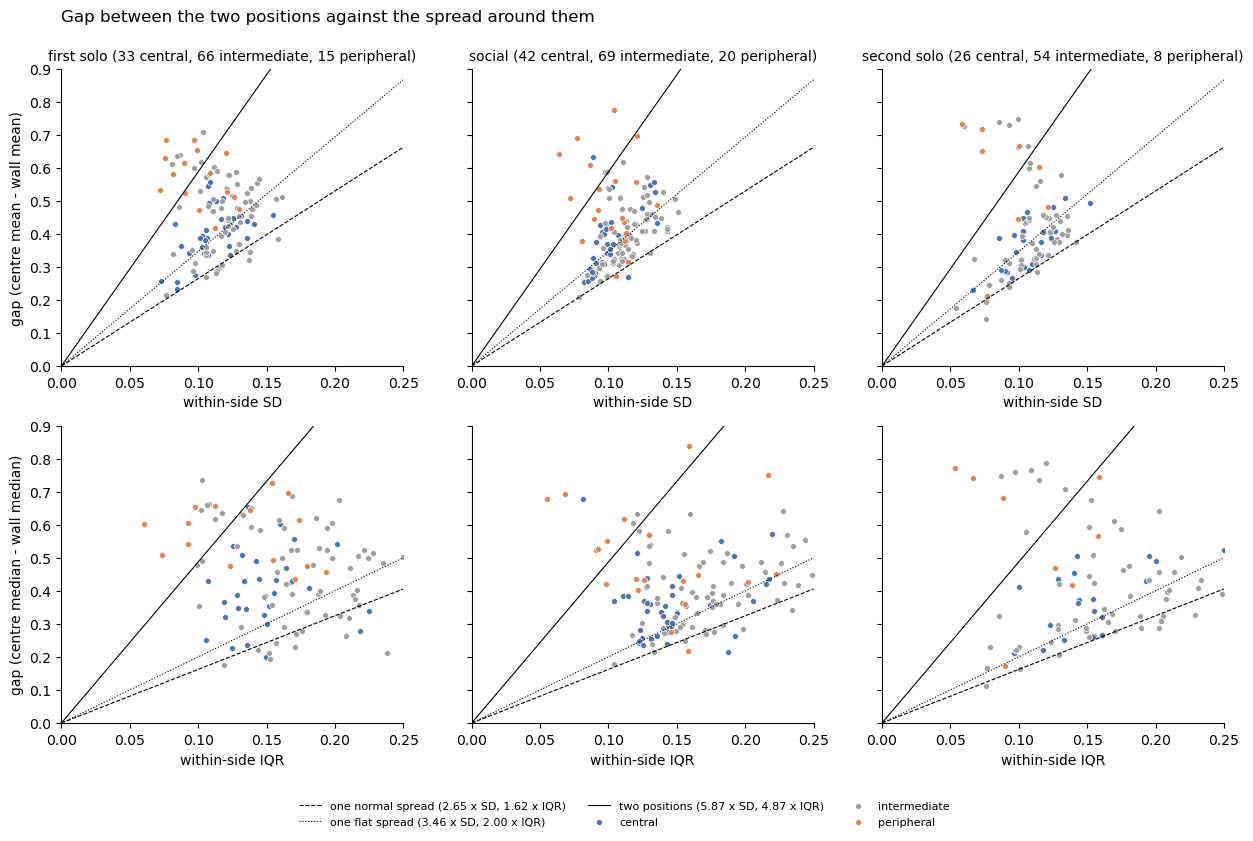

players   gap  gap_vs_sd  above_flat_sd  above_two_sd  gap_median  gap_vs_iqr  above_flat_iqr  above_two_iqr
solo1  central            33  0.40       3.52             19             0        0.39        2.57              25              0
       intermediate       66  0.48       3.67             39             6        0.48        2.35              45              6
       peripheral         15  0.58       5.76             15             7        0.60        4.67              15              6
social central            42  0.37       3.53             22             1        0.36        2.37              32              1
       intermediate       69  0.41       3.35             30             2        0.39        2.17              45              2
       peripheral         20  0.48       4.82             17             5        0.45        3.54              18              7
solo2  central            26  0.39       3.39             11             0        0.37        2.22              18              0
       intermediate       54  0.39       3.36             22             6        0.39        2.21              32              7
       peripheral          8  0.63       5.94              7             4        0.62        4.19               7              3

In [6]:
# get the gap / spread expected from one spread cut in two, and from two separate positions built from real trials
refs = hc.split_references(onset, players, split['boundary'])
display(refs.round(3))
REF_STYLE = {'one normal spread': '--', 'one flat spread': ':', 'two positions': '-'}


def plot_gap_vs_spread():
    """ Plot each player's gap between their two positions against the spread around them, as means / SD
        (top) and medians / IQR (bottom), one column per session type. Takes no arguments.

        Lines mark the gap each reference gives at that spread. """

    views = [('gap', 'sd_within', 'gap_vs_sd', 'gap (centre mean - wall mean)', 'within-side SD'),
             ('gap_median', 'iqr_within', 'gap_vs_iqr', 'gap (centre median - wall median)', 'within-side IQR')]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharey=True)
    for row, (gap_col, spread_col, ratio_col, ylabel, xlabel) in enumerate(views):
        spread = np.array([0, 0.25])
        for ax, st in zip(axes[row], hc.SESSION_TYPES):
            sub = sides[(sides['session_type'] == st) & sides['gap'].notna()]
            # draw the gap each reference gives at each spread
            for _, ref in refs.iterrows():
                ax.plot(spread, ref[ratio_col] * spread, color='k', lw=0.8, ls=REF_STYLE[ref['reference']],
                        label=f"{ref['reference']} ({ref['gap_vs_sd']:.2f} x SD, {ref['gap_vs_iqr']:.2f} x IQR)")
            for lab in STRAT_ORDER:
                s = sub[sub['fixed'] == lab]
                ax.scatter(s[spread_col], s[gap_col], s=18, color=hc.STRAT_PALETTE[lab],
                           edgecolor='white', linewidth=0.5, label=lab)
            if row == 0:
                counts = ', '.join(f"{(sub['fixed'] == lab).sum()} {lab}" for lab in STRAT_ORDER)
                ax.set_title(f'{LABELS[st]} ({counts})', fontsize=10)
            ax.set_xlabel(xlabel)
            ax.set_xlim(0, 0.25)
            ax.set_ylim(0, 0.9)
            ax.spines[['top', 'right']].set_visible(False)
        axes[row, 0].set_ylabel(ylabel)
    handles, names = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, names, frameon=False, fontsize=8, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 0.03))
    fig.suptitle('Gap between the two positions against the spread around them', x=0.125, y=0.95, ha='left')
    plt.show()


plot_gap_vs_spread()

# compare each group's gaps with the references, in both views
flat, two = refs.set_index('reference').loc[['one flat spread', 'two positions']].to_dict('index').values()
(sides[sides['gap'].notna()]
 .groupby(['session_type', 'fixed'])
 .agg(players=('gap', 'size'), gap=('gap', 'median'), gap_vs_sd=('gap_vs_sd', 'median'),
      above_flat_sd=('gap_vs_sd', lambda r: int((r > flat['gap_vs_sd']).sum())),
      above_two_sd=('gap_vs_sd', lambda r: int((r >= two['gap_vs_sd']).sum())),
      gap_median=('gap_median', 'median'), gap_vs_iqr=('gap_vs_iqr', 'median'),
      above_flat_iqr=('gap_vs_iqr', lambda r: int((r > flat['gap_vs_iqr']).sum())),
      above_two_iqr=('gap_vs_iqr', lambda r: int((r >= two['gap_vs_iqr']).sum())))
 .reindex(pd.MultiIndex.from_product([hc.SESSION_TYPES, STRAT_ORDER])).round(2))

In [7]:
# find the players whose real trials reach the two-position reference, and how many trials their less-used side holds
at_two = sides[sides['gap'].notna()].assign(
    sd_at_two=lambda d: d['gap_vs_sd'] >= two['gap_vs_sd'],
    iqr_at_two=lambda d: d['gap_vs_iqr'] >= two['gap_vs_iqr'],
    both_views=lambda d: d['sd_at_two'] & d['iqr_at_two'],
    less_used_side=lambda d: np.minimum(d['n_wall'], d['n_centre']))
at_two = at_two[at_two['sd_at_two'] | at_two['iqr_at_two']]
(at_two.groupby(['session_type', 'fixed'])
 .agg(players=('gap', 'size'), both_views=('both_views', 'sum'), less_used_median=('less_used_side', 'median'),
      less_used_min=('less_used_side', 'min'), less_used_max=('less_used_side', 'max'),
      wall_mean=('wall_mean', 'median'), centre_mean=('centre_mean', 'median'))
 .reindex(pd.MultiIndex.from_product([hc.SESSION_TYPES, STRAT_ORDER])).dropna(how='all')
 .astype({'players': int, 'both_views': int, 'less_used_min': int, 'less_used_max': int}).round(2))

players  both_views  less_used_median  less_used_min  less_used_max  wall_mean  centre_mean
solo1  intermediate        9           3              25.0             14             34       0.14         0.76
       peripheral          8           5               8.0              5             11       0.10         0.72
social central             1           1              20.0             20             20       0.24         0.87
       intermediate        2           2              53.0             48             58       0.23         0.82
       peripheral          7           5               9.0              6             22       0.13         0.73
solo2  intermediate        7           6              16.0              8             28       0.11         0.80
       peripheral          4           3               7.0              5             12       0.13         0.81

**Interpretation**

All values are from the tables above. Counts are players with a gap.

- **References.** One spread cut in two gives 2.65 to 3.46 × SD (1.62 to 2.00 × IQR). Two positions give 5.88 × SD (4.87 × IQR), with a gap of 0.65 between a wall position of 0.14 and a centre position of 0.79.
- **Most intermediate players sit close to one spread cut in two.** In social, their median gap is 0.41, against 0.65 for two positions. It is 3.35 × SD, between the normal and flat references, and 2.17 × IQR, just above the flat reference (2.00). The first solo (3.67 × SD, 2.35 × IQR) and second solo (3.36 × SD, 2.21 × IQR) match.
- **A minority of intermediate players reach the two-position reference.** In social, 2 of 69 do. More do in the solos, with 9 of 66 (first solo) and 7 of 54 (second solo) in at least one view, and 3 and 6 in both.
- **Their gaps rest on many trials.** Intermediate players at the line have 8 to 58 trials on their less-used side. Their positions sit near the population peaks (group medians 0.11 to 0.23 at the wall and 0.76 to 0.82 at the centre).
- **Peripheral players at the line have few centre-side trials** (group medians 7 to 9, minimum 5). Their gap shows a few full trips to the centre, not a second regular position. In social, 17 of 20 peripheral players are above the flat reference with means, and 18 of 20 with medians.
- **Central players' wall-side trials are not trips to the wall.** They sit at a social median of 0.39 (first table), just past the boundary (0.484), against 0.14 for the two-position wall side. Their median gap is 0.37 (3.53 × SD, 2.37 × IQR).
- **These values do not show that intermediate players use one broad spread.** Two broad, overlapping positions would give the same values.
- **Outliers have little effect on the gap.** In every group, the median gap from medians is within 0.03 of the median gap from means. SD and IQR measure spread differently, so each view is compared with its own references.

### 3b. How sure is each player's ratio?

A gap-to-spread ratio near a reference line may sit on the other side over a different set of the same player's trials. Each player's session is redrawn 1000 times from overlapping blocks of 10 trials in play order, as in 6f of `strategy_characterisation`. Both sides and both ratios are recomputed on every redraw. The 95% interval is the middle 95% of the redrawn ratios. Blocks keep a player's runs (section 4 of `strategy_characterisation`), so the interval is not narrowed by treating consecutive trials as independent.

An interval is **above** a reference if its lower end is at or above it, **below** if its upper end is under it, and **overlaps** otherwise.

Assumptions and limits:
- Redraws that leave a side with fewer than 5 trials are dropped (`valid_share` is the share kept). For players who rarely cross the boundary, the kept redraws are a selected subset, so their intervals are less reliable.
- Fewer trials give wider intervals. The solos have fewer trials than social, so more solo intervals overlap a reference.
- The references are treated as fixed values.

**How to read the figure**
- One row is one player with a gap, sorted by their ratio. Top row uses means and SD, bottom row medians and IQR. Columns are session types, colour is the fixed-cut label.
- The dot is the player's ratio on their real trials. The horizontal bar is its 95% block interval.
- Vertical lines are the references (dashed one normal spread, dotted one flat spread, solid two positions).
- A bar entirely right of a line is clearly above that reference. A bar crossing it overlaps.

**Why it is plotted.** It shows which players are clearly separated, which clearly are not, and which cannot be told apart over a different set of their own trials.

**How to read the tables.** `width_sd` and `width_iqr` are median interval widths, and `valid_share` the share of redraws kept. The counts give intervals below, overlapping or above each reference. The last table lists the intermediate players clearly above the two-position reference.

human_gap_ratio_intervals: loaded from cache


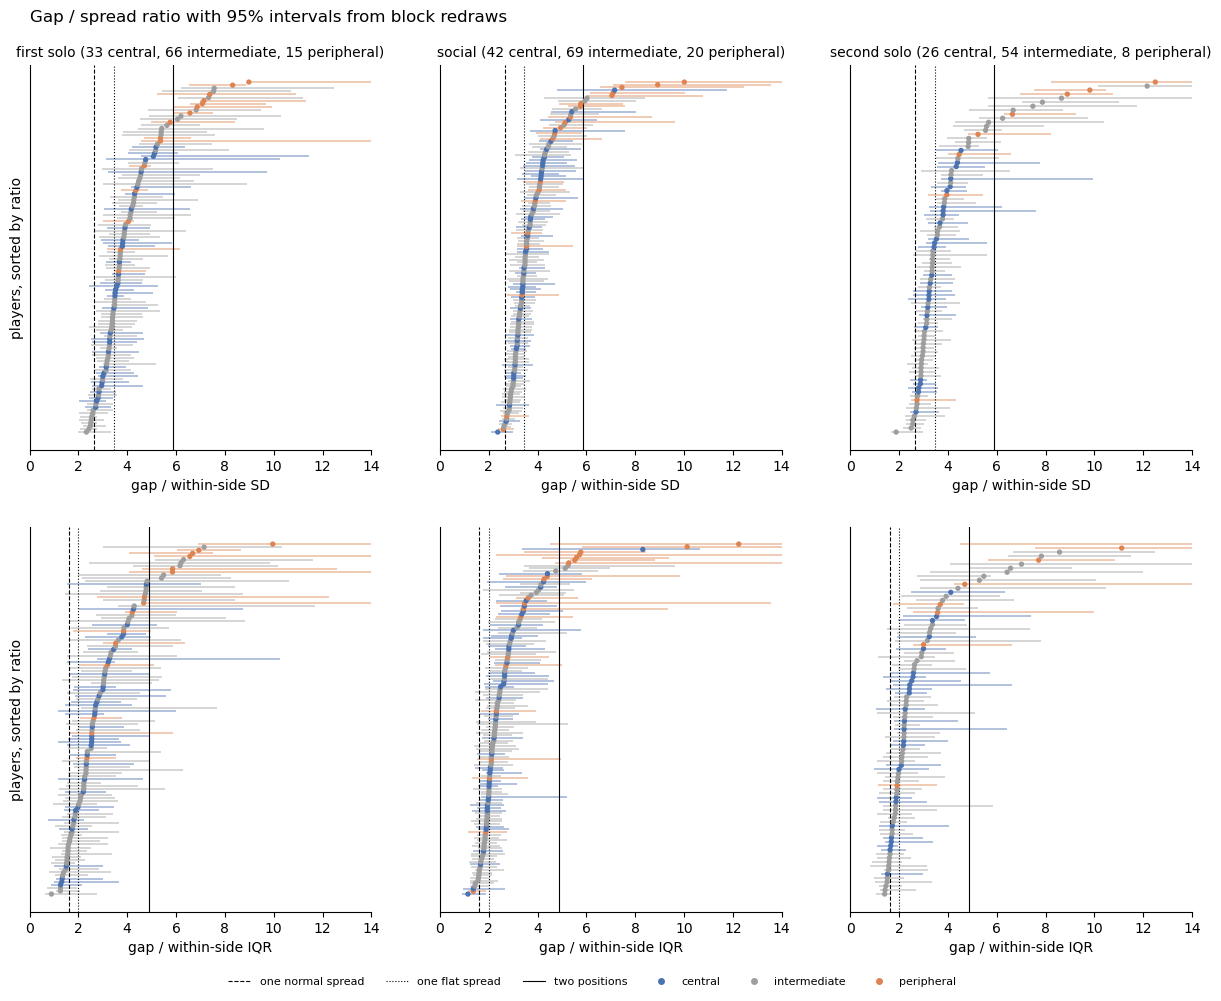

players  n_trials  valid_share  width_sd  width_iqr
solo1  central            33      54.0         0.70      1.79       2.06
       intermediate       66      53.5         0.99      1.78       2.52
       peripheral         15      59.0         0.49      3.00       3.43
social central            42     132.0         0.95      1.24       1.63
       intermediate       69     133.0         1.00      0.94       1.22
       peripheral         20     137.0         0.84      2.32       3.57
solo2  central            26      60.5         0.79      1.48       2.13
       intermediate       54      61.0         1.00      1.25       1.98
       peripheral          8      60.0         0.71      2.96       6.30

sd vs two                iqr vs two                sd vs flat                iqr vs flat               
                        below overlaps above      below overlaps above      below overlaps above       below overlaps above
solo1  central             25        8     0         24        9     0          3       25     5           0       26     7
       intermediate        43       21     2         37       28     1         10       36    20           2       46    18
       peripheral           4        6     5          2       10     3          0        2    13           0        3    12
social central             37        5     0         36        6     0          4       27    11           1       29    12
       intermediate        62        7     0         60        9     0         14       42    13           0       58    11
       peripheral           9        6     5          5       13     2          1        6    13           1        4    15
solo2  central             21        5     0         20        6     0          1       20     5           1       23     2
       intermediate        42       10     2         39       12     3          9       28    17           1       39    14
       peripheral           2        2     4          2        4     2          0        2     6           0        2     6

In [8]:
# redraw each player's session from blocks of trials to get a 95% interval on both ratios
gap_iv = data_saving.cached(
    'human_gap_ratio_intervals', lambda: hc.gap_ratio_intervals(onset, split['boundary'], n_boot=N_PERM_DRIFT),
    recompute=RECOMPUTE, stamp=dict(n_boot=N_PERM_DRIFT, block=hc.DRIFT_BLOCK, boundary=split['boundary'], rows=len(onset)))
gap_iv = gap_iv.merge(players[['experiment', 'player', 'session_type', 'fixed']], on=list(hc.KEYS))
ref_values = refs.set_index('reference')
# place each interval against the flat and two-position references, in both views
for view in ('sd', 'iqr'):
    r = f'gap_vs_{view}'
    gap_iv[f'width_{view}'] = gap_iv[f'{r}_hi'] - gap_iv[f'{r}_lo']
    for ref, short in (('one flat spread', 'flat'), ('two positions', 'two')):
        gap_iv[f'{view}_vs_{short}'] = hc.interval_position(gap_iv[f'{r}_lo'], gap_iv[f'{r}_hi'], ref_values.loc[ref, r])


def plot_gap_intervals():
    """ Plot each player's gap / spread ratio with its 95% interval, as means / SD (top) and medians / IQR
        (bottom), one column per session type. Takes no arguments.

        Players are sorted by their ratio. Vertical lines mark the three references. """

    views = [('gap_vs_sd', 'gap / within-side SD'), ('gap_vs_iqr', 'gap / within-side IQR')]
    fig, axes = plt.subplots(2, 3, figsize=(15, 11), sharex=True)
    for row, (r, xlabel) in enumerate(views):
        for ax, st in zip(axes[row], hc.SESSION_TYPES):
            sub = gap_iv[gap_iv['session_type'] == st].sort_values(r).reset_index(drop=True)
            colours = sub['fixed'].map(hc.STRAT_PALETTE)
            # draw each player's interval, then their ratio on their real trials
            ax.hlines(sub.index, sub[f'{r}_lo'], sub[f'{r}_hi'], color=colours, lw=1.2, alpha=0.5)
            ax.scatter(sub[r], sub.index, s=8, color=colours, zorder=3)
            for ref, value in ref_values[r].items():
                ax.axvline(value, color='k', lw=0.8, ls=REF_STYLE[ref], label=f'{ref} ({value:.2f})')
            if row == 0:
                counts = ', '.join(f"{(sub['fixed'] == lab).sum()} {lab}" for lab in STRAT_ORDER)
                ax.set_title(f'{LABELS[st]} ({counts})', fontsize=10)
            ax.set_xlabel(xlabel)
            ax.set_xlim(0, 14)
            ax.set_yticks([])
            ax.tick_params(labelbottom=True)
            ax.spines[['top', 'right']].set_visible(False)
        axes[row, 0].set_ylabel('players, sorted by ratio')
    # build one legend for the references and the labels
    handles = [plt.Line2D([], [], color='k', lw=0.8, ls=REF_STYLE[ref]) for ref in ref_values.index]
    handles += [plt.Line2D([], [], color=hc.STRAT_PALETTE[lab], marker='o', ls='', ms=4) for lab in STRAT_ORDER]
    fig.legend(handles, list(ref_values.index) + STRAT_ORDER, frameon=False, fontsize=8, ncol=6,
               loc='upper center', bbox_to_anchor=(0.5, 0.06))
    fig.suptitle('Gap / spread ratio with 95% intervals from block redraws', x=0.125, y=0.93, ha='left')
    plt.show()


plot_gap_intervals()

# summarise interval widths, and count intervals below, overlapping or above each reference
rows = pd.MultiIndex.from_product([hc.SESSION_TYPES, STRAT_ORDER])
display(gap_iv.groupby(['session_type', 'fixed'])
        .agg(players=('n_trials', 'size'), n_trials=('n_trials', 'median'), valid_share=('valid_share', 'median'),
             width_sd=('width_sd', 'median'), width_iqr=('width_iqr', 'median'))
        .reindex(rows).round(2))
pd.concat({f'{view} vs {short}': pd.crosstab([gap_iv['session_type'], gap_iv['fixed']], gap_iv[f'{view}_vs_{short}'])
           .reindex(index=rows, columns=['below', 'overlaps', 'above'], fill_value=0).rename_axis(columns=None)
           for short in ('two', 'flat') for view in ('sd', 'iqr')}, axis=1)

In [9]:
# list the intermediate players whose interval sits above the two-position reference in at least one view
clear = gap_iv[(gap_iv['fixed'] == 'intermediate') & ((gap_iv['sd_vs_two'] == 'above') | (gap_iv['iqr_vs_two'] == 'above'))]
(clear.merge(sides[list(hc.KEYS) + ['n_wall', 'n_centre', 'wall_mean', 'centre_mean']], on=list(hc.KEYS))
 [['experiment', 'player', 'session_type', 'n_wall', 'n_centre', 'wall_mean', 'centre_mean',
   'gap_vs_sd', 'gap_vs_sd_lo', 'gap_vs_iqr', 'gap_vs_iqr_lo', 'sd_vs_two', 'iqr_vs_two']]
 .sort_values(['session_type', 'experiment']).round(2))

,experiment,player,session_type,n_wall,n_centre,wall_mean,centre_mean,gap_vs_sd,gap_vs_sd_lo,gap_vs_iqr,gap_vs_iqr_lo,sd_vs_two,iqr_vs_two
1,19,1,solo1,39,23,0.10,0.74,7.33,6.09,4.78,3.16,above,overlaps
2,30,0,solo1,34,36,0.22,0.83,7.56,6.18,6.31,5.13,above,above
0,19,0,solo2,16,31,0.07,0.80,7.87,7.04,7.02,4.09,above,overlaps
3,46,1,solo2,19,51,0.13,0.85,12.16,10.17,8.57,6.67,above,above
4,79,1,solo2,14,41,0.04,0.78,7.48,5.62,6.57,4.88,overlaps,above
5,94,1,solo2,28,36,0.11,0.85,8.65,5.66,7.83,6.47,overlaps,above


**Interpretation**

All values are from the three tables above.

- **No social intermediate player is clearly above the two-position reference.** 62 of 69 are clearly below it with means and 60 of 69 with medians, and the rest overlap it. This is not from wide intervals, as social has the narrowest (median width 0.94 × SD and 1.22 × IQR for intermediate players, from a median of 133 trials).
- **A few solo intermediate players are clearly above it.** 6 player sessions are above in at least one view (2 first solo, 4 second solo), and 2 in both (experiment 30 player 0 first solo, experiment 46 player 1 second solo). They wait at 0.04 to 0.22 and 0.74 to 0.85, with 14 to 34 trials on their less-used side.
- **Most intermediate players cannot be told apart from one flat spread cut in two.** In social, 42 of 69 intervals overlap the flat reference with means and 58 of 69 with medians. 13 and 11 are clearly above it, and 14 and 0 clearly below it.
- **Solo intervals are wider**, as the solos have fewer trials (intermediate median widths 1.78 and 1.25 × SD in the first and second solo, from medians of 53.5 and 61 trials). More solo players therefore overlap each reference.
- **Peripheral intervals are the least reliable.** Only a median 0.84 (social) and 0.49 and 0.71 (solos) of redraws keep 5 centre-side trials. In social, 5 of 20 are clearly above the two-position reference with means and 2 of 20 with medians, and 13 and 15 are clearly above the flat reference.

## 4. Soft centre weight from shared shapes

Sections 1 to 3 cut every trial at one boundary. Here every trial counts toward both a peripheral shape and a centre shape, in proportion to how likely each shape makes it. A trial between the shapes counts partly to each.

**Method**
1. Fit a beta mixture once to every social trial, pooled over players. Its peripheral and centre shapes are then held fixed for every player and session (as the boundary is fitted on social in `strategy_characterisation`).
2. Give each player their own **centre weight** π, the share of their trials that the centre shape accounts for. It is the value that makes their trials most likely, given the fixed shapes. This is the soft version of the fraction of central trials.
3. Give each player a **soft position** in each shape, the mean of their trials weighted by how much each trial belongs to that shape.
4. Give π two 95% intervals. Each asks how much a player's π depends on the particular trials they happened to play, so whether the same player would give a similar π over a different set of their own trials.
   - The **likelihood interval** holds every π that explains the player's trials almost as well as the best one. It assumes each trial is independent of the last.
   - The **block interval** redraws the player's session 1000 times. Each redraw is built from blocks of 10 consecutive trials, picked at random (with replacement) from that player's session, until it has as many trials as the real one. π is recomputed on every redraw, and the interval spans the middle 95% of the 1000 values. Blocks keep runs of trials at one position together, which picking single trials would break up. Players do wait in runs (section 4 of `strategy_characterisation`), so the block interval is the one plotted.
5. Fit a 3-shape mixture as well, only to compare with the 2-shape one.

Beta shapes are used rather than Gaussians, because centrality is bounded at 0 and 1 and the wall end is skewed.

**Choices and assumptions**
- The spawn trial is dropped for the whole notebook (load cell).
- Centrality is clipped to [0.005, 0.995] for the beta shapes. Alcove corners sit just below 0.
- A shape may not be narrower than SD 0.03 (`MIN_SHAPE_SD`). Without this, a shape collapses onto trials piled up at one exact centrality (section 4a).
- A shape needs at least 5 effective trials (summed posteriors) to give a player a soft position.

In [10]:
# use the same trials and labels as the rest of the notebook (the spawn trial is dropped in the load cell)
onset_b = onset
players_b = players

### 4a. Shapes

**What a beta shape is.** A beta distribution covers values between 0 and 1. It has two parameters, a and b. Its mean is a / (a + b), and a larger a + b makes it narrower. Depending on a and b, it is a single hump skewed either way, or it rises toward one or both ends. This suits a bounded, skewed measure like centrality.

**How the mixture is fitted** (`cm.fit_beta_mixture`, by expectation-maximisation)
1. Split the social trials into k groups by value (one equal split and four random ones).
2. Give each trial a share in each shape, in proportion to that shape's weight times its density at the trial.
3. Set each shape's weight to the mean share it holds. Set its a and b to the values that make its share-weighted trials most likely, with SD at least 0.03.
4. Repeat steps 2 and 3 until the log likelihood stops rising. Keep the best of the five starts.

**What a beta mixture requires, and how this data meets it**

| Requirement | Here |
|---|---|
| The measure is bounded on a known range | Met. 1 is the arena centre and 0 the alcove back. Alcove corners sit just below 0, so values are clipped to [0.005, 0.995]. The clip value is a choice. |
| Values are continuous, with no pile-ups at single values | Not met. The spawn trial is dropped (load cell), but trials still pile at 0.0848 and, fewer, near 0.004 (tables below). The SD limit stops a shape collapsing onto a pile. |
| Each real peak is well described by one beta shape | Partly. The fit is checked by eye against the histogram (figure below), with no formal test. |
| Trials are independent | Not met. Trials are pooled over players, consecutive trials come in runs, and players with more trials count more. This barely moves the shapes, but it makes the log likelihood and BIC comparisons overconfident. |
| The number of shapes has a basis | None. BIC assumes independent trials, and correlated trials make it favour extra shapes. A lower BIC alone does not justify a third shape. |

Beta is not derived from how players choose where to wait. Its only justification here is how well it fits. The fitted shapes describe the trials. They are not strategies.

**The Gaussian comparison.** Each panel also shows the total density of a k-component Gaussian mixture (`sklearn` `GaussianMixture`, five starts), fitted to the same clipped trials. It has the same number of parameters (3k − 1, from k means, k variances and k − 1 weights), so the log likelihoods compare directly. The 2-component version is close to the model behind the trial boundary in `strategy_characterisation` section 2, which kept spawn trials and was not clipped. A Gaussian puts some density below 0 and above 1, where no trial can be, which lowers its likelihood.

**How to read the figure**
- Grey bars are the histogram of every social onset centrality (as a density, so the bars' area is 1).
- Each coloured line is one shape's weighted density (its weight times its beta density), so the area under it is the share of trials it accounts for. The solid black line is their sum. The dotted black line is the Gaussian total.
- Where the solid black line follows the grey bars, the beta mixture describes the trials well.
- Where a coloured line is higher than the others, that shape claims most of the trials at that centrality. Where two lines cross, a trial there counts half to each (with the population weights).

**Why it is plotted.** Each player's centre weight π (4b, 4c) is read off these fixed shapes. What each shape covers sets what π means. A centre shape on the centre peak makes π "how often a player waits at the centre". A peripheral shape that also covers the middle makes 1 − π "how often a player waits anywhere outside the centre peak".

**How to read the tables**
- In the shape table, `weight` is the share of all social trials a shape accounts for, and `mean` and `sd` describe the shape.
- In the model table, a higher `loglik` is a better fit. `bic` is lower for a better fit after a penalty for parameters.
- The third table lists the most repeated exact centrality values. The fourth gives the arena positions of the most repeated value (`x`, `z` in arena units, radius and angle from the centre).

human_beta_fits: loaded from cache


,k,shape,weight,mean,sd
0,2,peripheral,0.410,0.270,0.198
1,2,centre,0.590,0.765,0.138
2,3,narrow peripheral,0.062,0.114,0.030
3,3,broad,0.481,0.411,0.271
4,3,centre,0.457,0.779,0.127


human_mixture_family_compare: loaded from cache


,model,k,loglik,n_params,bic
0,gaussian k=2,2,-313.5,5,677.8
1,beta k=2,2,2063.5,5,-4076.1
2,gaussian k=3,3,942.9,8,-1804.5
3,beta k=3,3,2383.0,8,-4684.6


,trials
centrality,
0.0848,208
0.0850,23
0.0039,22
0.0846,18
0.0852,17
0.0851,17


,,trials,radius,angle_deg
x,z,,,
16.7,-6.9,41,18.07,-22.4
-6.9,-16.7,31,18.07,-112.4
6.9,-16.7,29,18.07,-67.6
-16.7,-6.9,24,18.07,-157.6
6.9,16.7,23,18.07,67.6
-6.9,16.7,23,18.07,112.4
16.7,6.9,21,18.07,22.4
-16.7,6.9,13,18.07,157.6


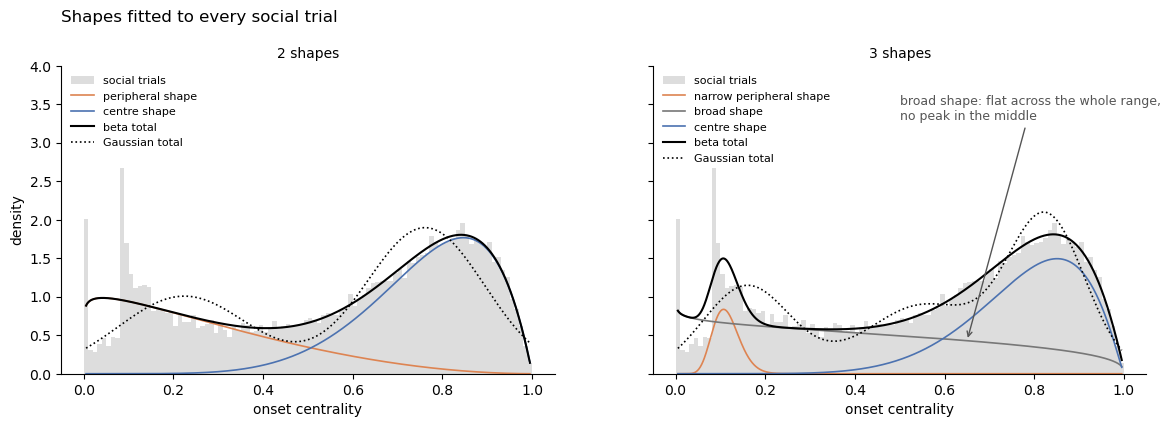

In [11]:
# fit the 2- and 3-shape beta mixtures to every social trial
x_social = onset_b.loc[onset_b['session_type'] == 'social', 'centrality'].to_numpy()
fits = data_saving.cached(
    'human_beta_fits', lambda: {k: cm.fit_beta_mixture(x_social, k=k) for k in (2, 3)}, recompute=RECOMPUTE,
    stamp=dict(n=len(x_social), sd_min=cm.MIN_SHAPE_SD, eps=cm.CLIP_EPS, names=str(cm.COMPONENT_NAMES)))
# name the 3 shapes for display after what the social fit found. The second shape is broad and flat, not a middle peak
SHAPE3_LABELS = {'peripheral': 'narrow peripheral', 'middle': 'broad', 'centre': 'centre'}
shape_table = pd.DataFrame([dict(k=k, shape=SHAPE3_LABELS[name] if k == 3 else name, weight=f['weights'][j], mean=f['a'][j] / (f['a'][j] + f['b'][j]),
                                 sd=np.sqrt(f['a'][j] * f['b'][j] / ((f['a'][j] + f['b'][j]) ** 2 * (f['a'][j] + f['b'][j] + 1))))
                            for k, f in fits.items() for j, name in enumerate(f['names'])])
display(shape_table.round(3))

# compare the fit of Gaussian and beta mixtures on the same trials
models = data_saving.cached('human_mixture_family_compare', lambda: cm.compare_models(x_social), recompute=RECOMPUTE,
                            stamp=dict(n=len(x_social), sd_min=cm.MIN_SHAPE_SD, eps=cm.CLIP_EPS))
display(models.round(1))

# list the most repeated exact centrality values (trials piled at one spot)
display(pd.Series(x_social).round(4).value_counts().head(6).rename_axis('centrality').rename('trials').to_frame())
# find where in the arena the most repeated value sits (x, z in arena units, radius from the centre)
pile = onset_b[(onset_b['session_type'] == 'social') & (onset_b['centrality'].round(4) == 0.0848)]
display(pile[['x', 'z']].round(1).value_counts().rename('trials').to_frame()
        .assign(radius=lambda d: np.hypot(*np.array(d.index.tolist()).T).round(2),
                angle_deg=lambda d: np.degrees(np.arctan2(*np.array(d.index.tolist()).T[::-1])).round(1)).head(8))


def plot_shapes():
    """ Plot the social trial histogram with each fitted beta shape and the Gaussian fit, for 2 and 3 shapes.
        Takes no arguments. """

    from sklearn.mixture import GaussianMixture
    grid = np.linspace(0.005, 0.995, 991)
    xc = cm.clip_unit(x_social)
    colours = {'peripheral': hc.STRAT_PALETTE['peripheral'], 'middle': '#777777', 'centre': hc.STRAT_PALETTE['central']}
    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
    for ax, k in zip(axes, (2, 3)):
        ax.hist(xc, bins=np.linspace(0, 1, 101), density=True, color='#DDDDDD', label='social trials')
        # draw each weighted shape and their total
        parts, total = cm.mixture_pdf(grid, fits[k])
        for j, name in enumerate(fits[k]['names']):
            label = SHAPE3_LABELS[name] if k == 3 else name
            ax.plot(grid, parts[:, j], color=colours[name], lw=1.2, label=f'{label} shape')
        ax.plot(grid, total, color='k', lw=1.5, label='beta total')
        gmm = GaussianMixture(n_components=k, n_init=5, random_state=0).fit(xc.reshape(-1, 1))
        ax.plot(grid, np.exp(gmm.score_samples(grid.reshape(-1, 1))), color='k', ls=':', lw=1.2, label='Gaussian total')
        ax.set_title(f'{k} shapes', fontsize=10)
        ax.set_xlabel('onset centrality')
        ax.set_ylim(0, 4)
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(frameon=False, fontsize=8, loc='upper left')
    # point out that the broad shape has no peak in the middle
    axes[1].annotate('broad shape: flat across the whole range,\nno peak in the middle', xy=(0.65, 0.43), xytext=(0.5, 3.3),
                     ha='left', fontsize=9, color='#555555', arrowprops=dict(arrowstyle='->', color='#555555'))
    axes[0].set_ylabel('density')
    fig.suptitle('Shapes fitted to every social trial', x=0.125, y=1.02, ha='left')
    plt.show()


plot_shapes()

**Interpretation**

- **Beta shapes fit far better than Gaussian ones** with the same number of parameters (log likelihood 2063.5 against −313.5 with 2 shapes, 2383.0 against 942.9 with 3).
- **The 2-shape centre shape follows the centre peak** (mean 0.77, SD 0.14).
- **The 2-shape peripheral shape is broad** (mean 0.27, SD 0.20). The figure shows it covering the wall peak and the flat stretch toward the centre peak. So its weight means "outside the centre peak", not "at the wall".
- **The 3-shape fit does not find a middle peak.** Its lowest shape is narrow and sits at the SD limit (0.030) at 0.11. It is called the **narrow peripheral shape** below. Its second shape is flat across the whole range (mean 0.41, SD 0.27), with no peak in the middle. It is called the **broad shape** below (`middle` in the code). It takes most trials between the narrow peak and the centre peak, and some under the centre peak (figure). 3 shapes have the lower BIC (−4684.6 against −4076.1), but the extra shape describes the wall end's irregular form, not a middle waiting position.
- **The wall end holds trials piled at exact values.** 208 social trials sit at 0.0848. They fall on 8 points at the same radius (18.07), 45° apart and offset 22.5° from the axes, so this is a fixed spot repeated around the arena where players are stopped. A smaller pile sits near 0.004.

### 4b. Check on simulated players

Before reading real players, the method is run on simulated players whose behaviour is known. Each kind gets 200 players, at the median trial count of social and of the second solo.

- **central / peripheral** draw 95% / 5% of trials from the fitted centre shape, the rest from the peripheral shape (true π 0.95 / 0.05).
- **mixer** draws half from each shape, in random order (true π 0.5).
- **switcher** draws the first half from the peripheral shape and the second half from the centre shape (true π 0.5).
- **hoverer** waits around the boundary (0.484, SD 0.08). It follows neither shape, so it has no true π.
- **drifter** moves steadily from the peripheral shape's mean to the centre shape's mean (SD 0.08). It has no true π either.

Each simulated player also gets a fixed-cut label from their own trials, to compare with the current method.

**How to read the figure** (simulated players at the social trial count)
- One point is one simulated player. Colour is the simulated kind.
- **x is the centre weight π.** It is the share of the player's trials that the centre shape accounts for. 0 means the peripheral shape explains all their trials, 1 means the centre shape does, 0.5 half each. It is a share of trials, not a position.
- **y in the left panel is the soft peripheral position.** It is the mean centrality of the player's trials, each weighted by how much it belongs to the peripheral shape. So it says where the player waits when they wait outside the centre peak.
- **y in the right panel is the soft centre position**, the same for the centre shape. It says where the player waits when they are in the centre peak.
- **The dashed line is the trial boundary (0.484)**, fitted on social as in `strategy_characterisation` section 2, as a reference. A soft position near it means the player's trials in that shape sit near the boundary, not at the wall or the centre.
- A player with fewer than 5 effective trials in a shape has no soft position for it and is missing from that panel.

**Why it is plotted.** The kinds are known, so the figure shows which measures tell them apart. Kinds at different x are separated by π alone. Kinds at the same x but different heights are separated only by the soft positions.

**How to read the tables**
- `true_pi` is the weight each kind was built with. `w_centre` gives the median and quartiles of the estimated π.
- `*_width` is the median interval width. `*_coverage` is the share of players whose interval holds `true_pi`, which should be about 0.95.
- The second table gives median soft positions, median 3-shape weights (`w3_*`), and the share of each kind given each fixed-cut label (`fixed_*`).

In [12]:
# simulate each kind at the median social and second-solo trial counts
lengths = players_b.groupby('session_type')['n_trials'].median().astype(int)
sims, sim_tables = [], []
for n in (lengths['social'], lengths['solo2']):
    sim, truth = cm.simulate_players(fits[2], n_trials=n, n_players=200, boundary=split['boundary'],
                                     rng=np.random.default_rng(n))
    # get each simulated player's 2- and 3-shape weights, soft positions and fixed-cut label
    kinds = sim.groupby(list(hc.KEYS))['kind'].first().rename('kind').reset_index()
    t2 = cm.player_mixture_table(sim, fits[2], n_boot=N_PERM_DRIFT).merge(kinds)
    t3 = cm.player_mixture_table(sim, fits[3], n_boot=0)[list(hc.KEYS) + ['w_peripheral', 'w_middle', 'w_centre']]
    sim['peripheral'] = sim['centrality'] < split['boundary']
    lab = hc.player_table(sim).assign(fixed=lambda d: fixed_labels(d['frac_peripheral']))[list(hc.KEYS) + ['fixed']]
    sim_tables.append(t2.merge(t3, on=list(hc.KEYS), suffixes=('', '_3')).merge(lab).assign(n_trials_sim=n))
    sims.append(cm.simulation_summary(t2, truth).assign(n_trials=n))
sim_table = pd.concat(sim_tables, ignore_index=True)
display(pd.concat(sims).set_index(['n_trials', 'kind']).round(2))

# summarise soft positions, 3-shape weights and fixed-cut labels per kind
summary = (sim_table.groupby(['n_trials_sim', 'kind'], sort=False)
           .agg(pos_peripheral=('pos_peripheral', 'median'), pos_centre=('pos_centre', 'median'),
                w3_narrow_peripheral=('w_peripheral_3', 'median'), w3_broad=('w_middle', 'median'), w3_centre=('w_centre_3', 'median')))
labels = pd.crosstab([sim_table['n_trials_sim'], sim_table['kind']], sim_table['fixed'], normalize='index')
summary.join(labels.reindex(columns=STRAT_ORDER, fill_value=0).add_prefix('fixed_')).round(2)

players  true_pi  w_centre  w_centre_q25  w_centre_q75  likelihood_width  likelihood_coverage  block_width  block_coverage
n_trials kind                                                                                                                                  
133      central         200     0.95      0.95          0.94          0.97              0.09                 0.94         0.08            0.90
         peripheral      200     0.05      0.05          0.03          0.07              0.11                 0.94         0.10            0.90
         mixer           200     0.50      0.50          0.46          0.53              0.20                 0.91         0.19            0.88
         switcher        200     0.50      0.51          0.49          0.53              0.20                 1.00         0.52            1.00
         hoverer         200      NaN      0.00          0.00          0.00              0.07                  NaN         0.00             NaN
         drifter         200      NaN      0.40          0.38          0.42              0.25                  NaN         0.71             NaN
60       central         200     0.95      0.95          0.93          0.97              0.14                 0.94         0.11            0.87
         peripheral      200     0.05      0.04          0.01          0.07              0.14                 0.94         0.11            0.84
         mixer           200     0.50      0.49          0.44          0.55              0.29                 0.96         0.26            0.84
         switcher        200     0.50      0.50          0.47          0.53              0.29                 1.00         0.73            1.00
         hoverer         200      NaN      0.00          0.00          0.00              0.13                  NaN         0.00             NaN
         drifter         200      NaN      0.40          0.37          0.43              0.37                  NaN         0.95             NaN

pos_peripheral  pos_centre  w3_narrow_peripheral  w3_broad  w3_centre  fixed_central  fixed_intermediate  fixed_peripheral
n_trials_sim kind                                                                                                                                  
133          central               0.27        0.76                  0.00      0.08       0.92            1.0                0.00              0.00
             peripheral            0.27        0.77                  0.10      0.90       0.00            0.0                0.44              0.56
             mixer                 0.27        0.77                  0.02      0.65       0.33            0.0                1.00              0.00
             switcher              0.27        0.77                  0.02      0.64       0.34            0.0                1.00              0.00
             hoverer               0.48        0.58                  0.00      1.00       0.00            0.0                1.00              0.00
             drifter               0.43        0.65                  0.00      0.97       0.03            0.0                1.00              0.00
60           central               0.27        0.77                  0.00      0.07       0.92            1.0                0.00              0.00
             peripheral            0.27        0.76                  0.11      0.89       0.00            0.0                0.40              0.60
             mixer                 0.27        0.77                  0.02      0.64       0.32            0.0                1.00              0.00
             switcher              0.27        0.76                  0.03      0.64       0.33            0.0                1.00              0.00
             hoverer               0.48        0.58                  0.00      1.00       0.00            0.0                1.00              0.00
             drifter               0.43        0.65                  0.00      0.97       0.03            0.0                1.00              0.00

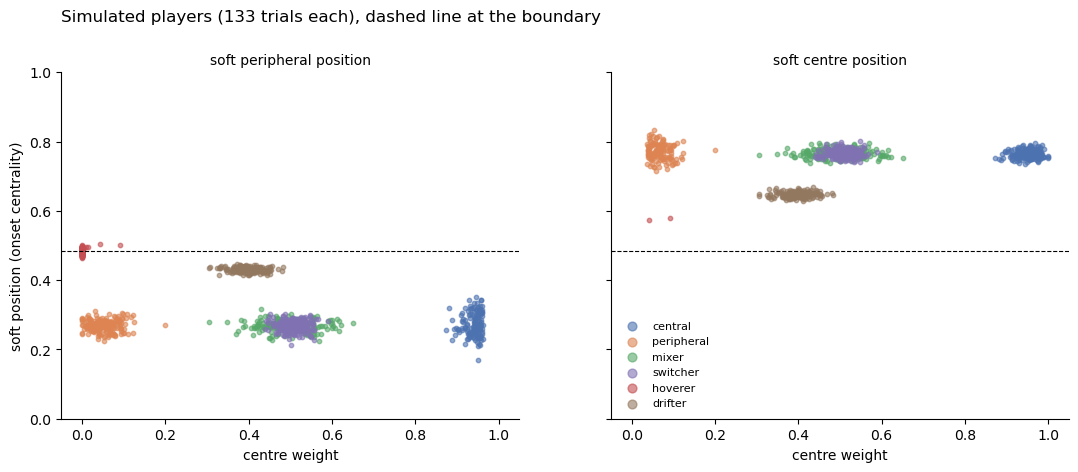

In [13]:
def plot_simulated():
    """ Plot each simulated player's centre weight against their soft peripheral and centre positions, at the
        social trial count. Takes no arguments. """

    sub = sim_table[sim_table['n_trials_sim'] == lengths['social']]
    colours = dict(zip(cm.SIM_KINDS, ['#4C72B0', '#DD8452', '#55A868', '#8172B3', '#C44E52', '#937860']))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True)
    for ax, pos, title in zip(axes, ('pos_peripheral', 'pos_centre'), ('soft peripheral position', 'soft centre position')):
        for kind in cm.SIM_KINDS:
            s = sub[sub['kind'] == kind]
            ax.scatter(s['w_centre'], s[pos], s=10, color=colours[kind], alpha=0.6, label=kind)
        ax.axhline(split['boundary'], color='k', ls='--', lw=0.8)
        ax.set_xlabel('centre weight')
        ax.set_title(title, fontsize=10)
        ax.set_ylim(0, 1)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylabel('soft position (onset centrality)')
    axes[1].legend(frameon=False, fontsize=8, markerscale=2)
    fig.suptitle(f"Simulated players ({lengths['social']} trials each), dashed line at the boundary", x=0.125, y=1.02, ha='left')
    plt.show()


plot_simulated()

**Interpretation**

All values are from the two tables above and the figure.

- **π recovers the true weight of every kind that has one.** Medians are 0.95, 0.05, 0.50 and 0.51 (central, peripheral, mixer, switcher) at 133 trials, and 0.95, 0.04, 0.49 and 0.50 at 60.
- **The likelihood interval covers about as it should** for central, peripheral and mixer (0.91 to 0.96). The block interval covers less (0.84 to 0.90), most at 60 trials, so it is a little too narrow when trials are independent.
- **The switcher shows why the block interval is needed.** Both intervals cover (1.00), as its share is exactly 0.5 by construction. But the block interval is much wider (0.52 against 0.20 at 133 trials), because a redraw of a player who switches once can hold mostly one half.
- **π reads a hoverer as a pure peripheral player** (median 0.00), as the broad peripheral shape covers the boundary. Its soft peripheral position (0.48) separates it from a peripheral player (0.27).
- **The drifter gets π 0.40, with soft positions 0.43 and 0.65**, between the mixer (0.27, 0.77) and the hoverer (0.48, 0.58).
- **The fixed cut labels mixer, switcher, hoverer and drifter all intermediate** (1.00 of each). π separates the hoverer from the mixer but not from a peripheral player. π with the soft positions separates all four (figure).
- **Limit.** Simulated players draw from the population shapes, which are wider than a real player's own spread. Simulated peripheral players have a soft peripheral position of 0.27, against 0.15 for real ones (4c table), and 44% of them get the fixed-cut label intermediate at 133 trials. So this checks that the method recovers what it is built on, not that the simulated kinds look like real players.

### 4c. Real players

Every player in every session gets a centre weight with both intervals, and soft peripheral and centre positions. The first figure compares π with the fraction of central trials from the fixed cut (1 − fraction peripheral). The second shows π against the soft positions, as for the simulated players in 4b.

**How to read the first figure**
- One point is one real player. One panel per session type. Colour is the fixed-cut label.
- x is the fraction of their trials at or above the boundary (the fixed cut's measure). y is the centre weight π.
- The vertical bar through each point is the block interval (method, step 4). It spans the π values the same player gives over 95% of redrawn sets of their own trials.
- A short bar means the player's π hardly depends on which trials they played. A long bar means it could be quite different over another set of their trials, so their position on y is uncertain. Two players whose bars overlap a lot cannot be told apart by π.
- A point at π = 0 or 1 often has no visible bar, as every redraw gives the same edge value.
- The dashed vertical lines are the fixed cuts. Left of 0.2 is labelled peripheral, right of 0.8 central.
- The solid diagonal is where π equals the fraction. A point below it has a lower π than its fraction.

**Why it is plotted.** It shows whether π orders players differently from the fraction. The bars show how certain π is for each player, and so for which players π could support a label.

**How to read the second figure.** It is the 4b figure for real players, one row per session type, coloured by fixed-cut label. Comparing it with 4b shows which simulated kinds real players sit closest to.

**How to read the tables**
- In the first table, `at_edge` counts players with π of exactly 0 or 1, and `no_*_pos` counts players with no soft position in that shape. The other columns are medians.
- The second table measures agreement between π and the fraction (Spearman correlation, median and largest absolute difference).
- The last two tables give the range of intermediate players' soft positions, and the simulated kinds' medians to compare against.

In [14]:
# get every real player's centre weight, intervals and soft positions, then their 3-shape weights
mix2 = data_saving.cached(
    'human_soft_weights', lambda: cm.player_mixture_table(onset_b, fits[2], n_boot=N_PERM_DRIFT), recompute=RECOMPUTE,
    stamp=dict(n_boot=N_PERM_DRIFT, rows=len(onset_b), sd_min=cm.MIN_SHAPE_SD, eps=cm.CLIP_EPS, names=str(cm.COMPONENT_NAMES)))
mix3 = cm.player_mixture_table(onset_b, fits[3], n_boot=0)
mix = (mix2.merge(mix3[list(hc.KEYS) + ['w_peripheral', 'w_middle', 'w_centre']], on=list(hc.KEYS), suffixes=('', '_3'))
       .merge(players_b[list(hc.KEYS) + ['fixed', 'frac_peripheral', 'mean_centrality']], on=list(hc.KEYS)))
mix['frac_central'] = 1 - mix['frac_peripheral']
mix['width_likelihood'] = mix['pi_hi'] - mix['pi_lo']
mix['width_block'] = mix['pi_boot_hi'] - mix['pi_boot_lo']

# summarise the centre weight, its intervals and the soft positions by fixed-cut label
(mix.groupby(['session_type', 'fixed'])
 .agg(players=('w_centre', 'size'), w_centre=('w_centre', 'median'), frac_central=('frac_central', 'median'),
      width_likelihood=('width_likelihood', 'median'), width_block=('width_block', 'median'),
      at_edge=('w_centre', lambda w: int(((w <= 0.001) | (w >= 0.999)).sum())),
      pos_peripheral=('pos_peripheral', 'median'), pos_centre=('pos_centre', 'median'),
      no_peripheral_pos=('pos_peripheral', lambda p: int(p.isna().sum())), no_centre_pos=('pos_centre', lambda p: int(p.isna().sum())))
 .reindex(pd.MultiIndex.from_product([hc.SESSION_TYPES, STRAT_ORDER])).round(2))

human_soft_weights: loaded from cache


players  w_centre  frac_central  width_likelihood  width_block  at_edge  pos_peripheral  pos_centre  no_peripheral_pos  no_centre_pos
solo1  central           100      1.00          0.94              0.11         0.05       49            0.34        0.74                 85              0
       intermediate       67      0.45          0.51              0.30         0.45        0            0.29        0.74                  2             10
       peripheral         33      0.00          0.10              0.10         0.04       19            0.16        0.83                  1             31
social central            95      1.00          0.97              0.03         0.00       56            0.36        0.77                 75              0
       intermediate       69      0.42          0.54              0.20         0.32        0            0.35        0.72                  0              0
       peripheral         36      0.00          0.04              0.02         0.00       30            0.15        0.87                  0             34
solo2  central            87      1.00          0.97              0.08         0.00       53            0.36        0.76                 76              0
       intermediate       54      0.34          0.49              0.30         0.40        2            0.36        0.71                  0              6
       peripheral         59      0.00          0.00              0.04         0.00       49            0.14        0.89                  0             58

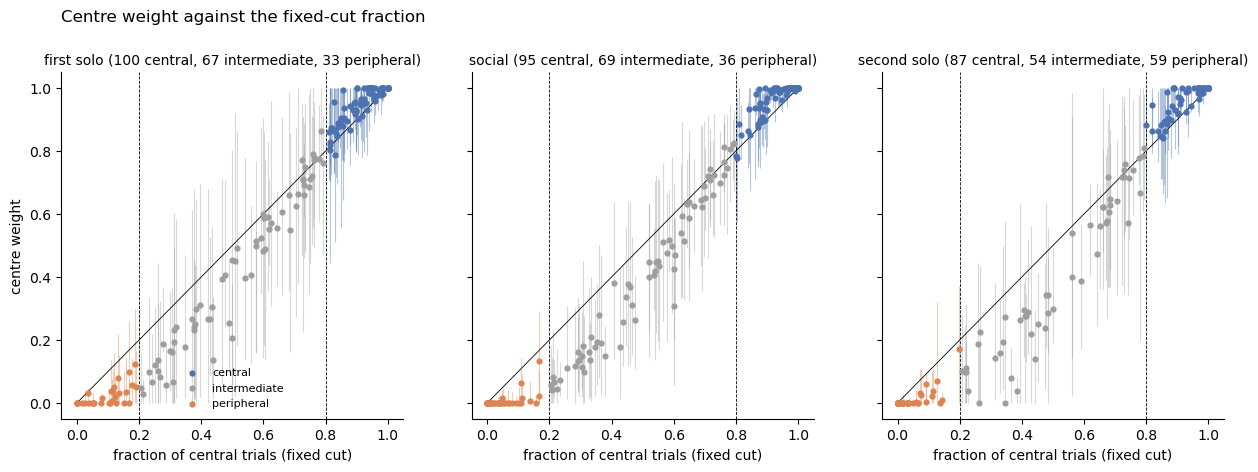

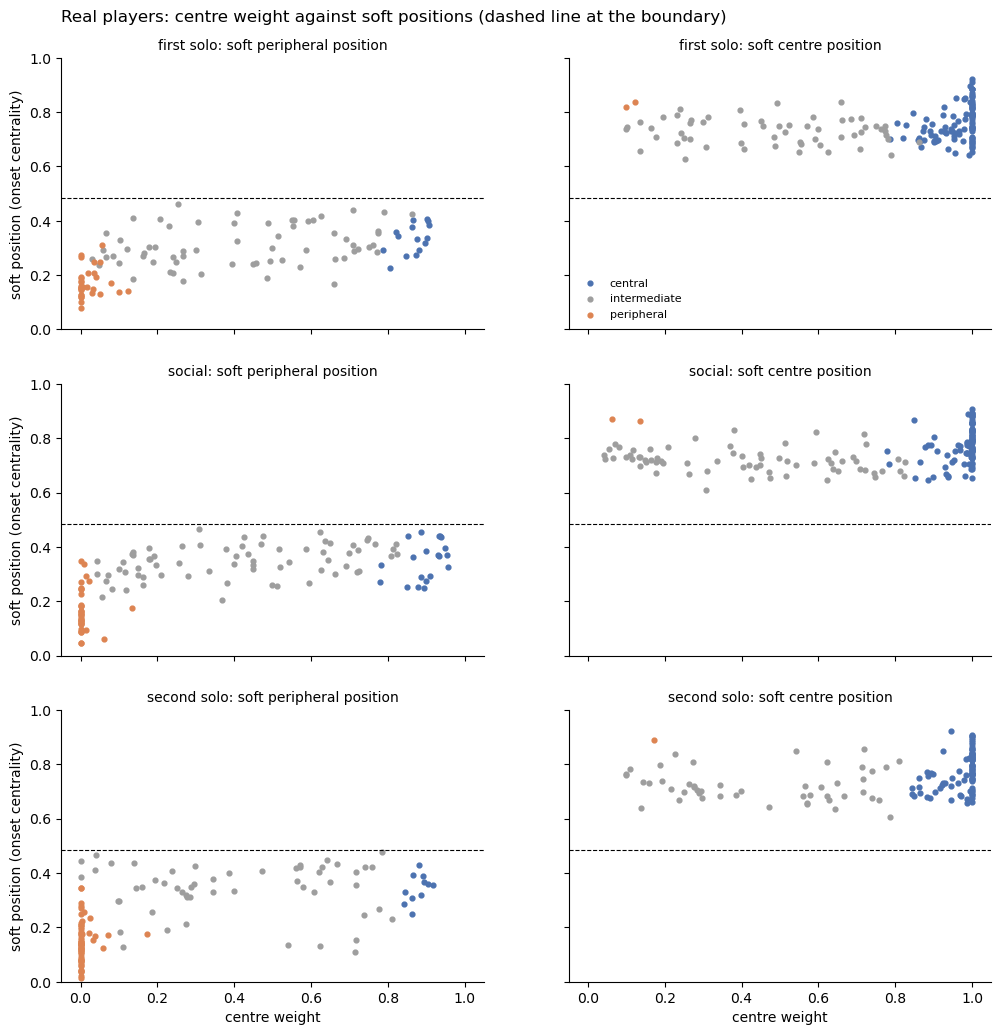

,spearman,median_abs_diff,max_abs_diff
session_type,,,
solo1,0.977,0.049,0.302
social,0.979,0.037,0.295
solo2,0.977,0.024,0.344


In [15]:
def plot_soft_vs_fixed():
    """ Plot each player's centre weight with its block interval against their fraction of central trials,
        one panel per session type. Takes no arguments. """

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
    for ax, st in zip(axes, hc.SESSION_TYPES):
        sub = mix[mix['session_type'] == st]
        for lab in STRAT_ORDER:
            s = sub[sub['fixed'] == lab]
            ax.vlines(s['frac_central'], s['pi_boot_lo'], s['pi_boot_hi'], color=hc.STRAT_PALETTE[lab], lw=0.8, alpha=0.4)
            ax.scatter(s['frac_central'], s['w_centre'], s=12, color=hc.STRAT_PALETTE[lab], label=lab, zorder=3)
        ax.plot([0, 1], [0, 1], color='k', lw=0.6)
        for cut in hc.FIXED_CUTS:
            ax.axvline(1 - cut, color='k', ls='--', lw=0.6)
        counts = ', '.join(f"{(sub['fixed'] == lab).sum()} {lab}" for lab in STRAT_ORDER)
        ax.set_title(f'{LABELS[st]} ({counts})', fontsize=10)
        ax.set_xlabel('fraction of central trials (fixed cut)')
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylabel('centre weight')
    axes[0].legend(frameon=False, fontsize=8)
    fig.suptitle('Centre weight against the fixed-cut fraction',
                 x=0.125, y=1.02, ha='left')
    plt.show()


def plot_soft_positions():
    """ Plot each player's centre weight against their soft peripheral and centre positions, one row per
        session type. Takes no arguments. """

    fig, axes = plt.subplots(3, 2, figsize=(12, 12), sharex=True, sharey=True)
    for row, st in enumerate(hc.SESSION_TYPES):
        sub = mix[mix['session_type'] == st]
        for ax, pos in zip(axes[row], ('pos_peripheral', 'pos_centre')):
            for lab in STRAT_ORDER:
                s = sub[sub['fixed'] == lab]
                ax.scatter(s['w_centre'], s[pos], s=12, color=hc.STRAT_PALETTE[lab], label=lab)
            ax.axhline(split['boundary'], color='k', ls='--', lw=0.8)
            ax.set_title(f"{LABELS[st]}: {pos.replace('pos_', 'soft ')} position", fontsize=10)
            ax.set_ylim(0, 1)
            ax.spines[['top', 'right']].set_visible(False)
        axes[row, 0].set_ylabel('soft position (onset centrality)')
    for ax in axes[-1]:
        ax.set_xlabel('centre weight')
    axes[0, 1].legend(frameon=False, fontsize=8)
    fig.suptitle('Real players: centre weight against soft positions (dashed line at the boundary)', x=0.125, y=0.92, ha='left')
    plt.show()


plot_soft_vs_fixed()
plot_soft_positions()

# measure how closely the centre weight follows the fixed-cut fraction
(mix.groupby('session_type')
 .apply(lambda d: pd.Series(dict(spearman=d['w_centre'].corr(d['frac_central'], method='spearman'),
                                 median_abs_diff=(d['w_centre'] - d['frac_central']).abs().median(),
                                 max_abs_diff=(d['w_centre'] - d['frac_central']).abs().max())), include_groups=False)
 .loc[list(hc.SESSION_TYPES)].round(3))

In [16]:
# compare intermediate players' soft positions with the simulated kinds at the social trial count
quart = lambda q: (lambda s: s.quantile(q))
real = (mix[mix['fixed'] == 'intermediate'].groupby('session_type')
        .agg(**{f'{pos}_{name}': (pos, f) for pos in ('pos_peripheral', 'pos_centre')
                for name, f in (('min', 'min'), ('q25', quart(0.25)), ('median', 'median'), ('q75', quart(0.75)), ('max', 'max'))})
        .loc[list(hc.SESSION_TYPES)])
display(real.round(2))
(sim_table[sim_table['n_trials_sim'] == lengths['social']].groupby('kind', sort=False)
 .agg(pos_peripheral_median=('pos_peripheral', 'median'), pos_centre_median=('pos_centre', 'median'), w_centre_median=('w_centre', 'median'))
 .round(2))

,pos_peripheral_min,pos_peripheral_q25,pos_peripheral_median,pos_peripheral_q75,pos_peripheral_max,pos_centre_min,pos_centre_q25,pos_centre_median,pos_centre_q75,pos_centre_max
session_type,,,,,,,,,,
solo1,0.17,0.26,0.29,0.38,0.46,0.63,0.69,0.74,0.76,0.84
social,0.20,0.31,0.35,0.39,0.47,0.61,0.69,0.72,0.74,0.83
solo2,0.11,0.30,0.36,0.42,0.48,0.60,0.68,0.71,0.76,0.86


,pos_peripheral_median,pos_centre_median,w_centre_median
kind,,,
central,0.27,0.76,0.95
peripheral,0.27,0.77,0.05
mixer,0.27,0.77,0.50
switcher,0.27,0.77,0.51
hoverer,0.48,0.58,0.00
drifter,0.43,0.65,0.40


**Interpretation**

All values are from the tables in 4c.

- **π follows the fixed-cut fraction closely** (Spearman 0.977 to 0.979, median difference 0.024 to 0.049, largest 0.30 to 0.34).
- **Many central and peripheral players sit at exactly π = 0 or 1**. That's 56 of 95 central and 30 of 36 peripheral players in social, and 53 of 87 and 49 of 59 in the second solo. At the edge π cannot rank players, and their block intervals have zero width (median 0.00). Their soft positions still vary.
- **For intermediate players, π is lower than the fraction of central trials** (social median 0.42 against 0.54). The broad peripheral shape takes in trials just above the boundary.
- **π is least certain for intermediate players.** Their median block interval is 0.32 wide in social and 0.45 and 0.40 in the two solos.
- **Intermediate players' soft positions sit between the simulated mixer and drifter.** In social, their soft peripheral position runs 0.20 to 0.47 (quartiles 0.31 to 0.39) and their soft centre position 0.61 to 0.83 (quartiles 0.69 to 0.74). The simulated mixer has 0.27 and 0.77, the drifter 0.43 and 0.65.
- **No real intermediate player matches the simulated hoverer.** Their soft centre position is at least 0.60 in every session, against 0.58 for the hoverer.

### 4d. 3-shape model (comparison only)

The 3-shape weights place each player in a triangle, with the narrow peripheral shape at bottom left, the broad shape at the top and the centre shape at bottom right.

**The top corner is not a middle waiting position.** The broad shape is flat across the whole range (4a, mean 0.41, SD 0.27). It takes trials that are in neither the narrow peak at 0.11 (SD 0.03) nor the centre peak. A player near the broad–centre edge is therefore not a "soft central" player. Their trials outside the centre peak simply sit away from 0.11.

**How to read the figure**
- One point is one player. One panel per session type. Colour is the fixed-cut label.
- Each corner is a player with all their weight on that shape. The closer a point is to a corner, the more weight it has on that shape.
- A point on an edge has no weight on the shape at the opposite corner. The middle of the triangle is equal weight on all three.

**Why it is plotted.** It was meant to show whether a third shape picks out players who wait between the two peaks, which the 2-shape model cannot. The fit found no such shape (4a), so the figure mainly shows how the broad shape absorbs trials.

**How to read the table.** `w2_centre` is the centre weight π. `w3_narrow_peripheral`, `w3_broad` and `w3_centre` are the 3-shape weights. All are medians.

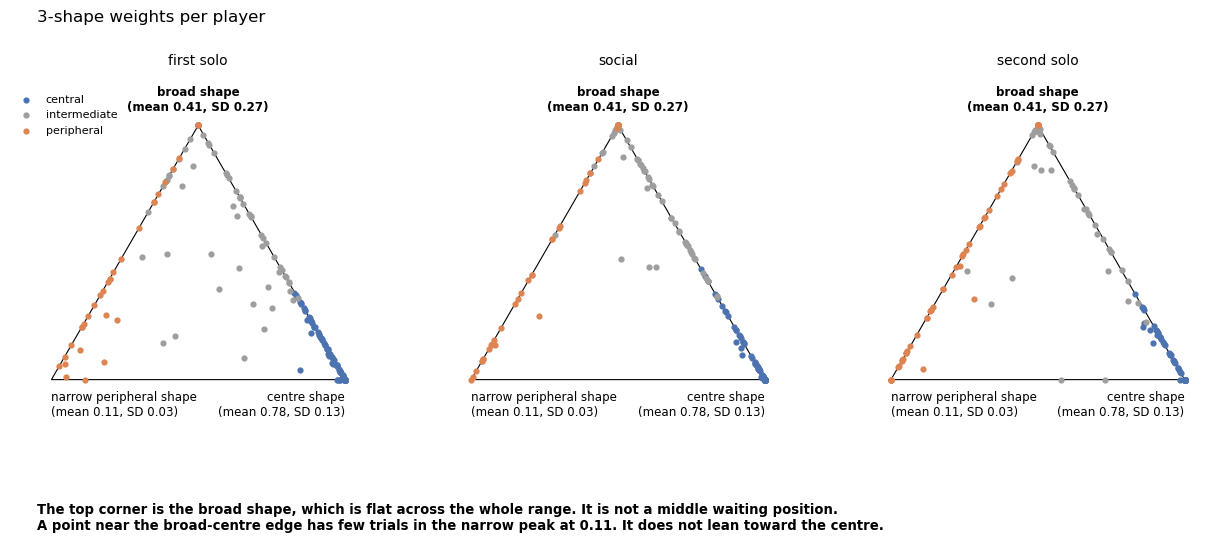

players  w2_centre  w3_narrow_peripheral  w3_broad  w3_centre
solo1  central           100       1.00                  0.00      0.03       0.97
       intermediate       67       0.45                  0.00      0.69       0.28
       peripheral         33       0.00                  0.65      0.35       0.00
social central            95       1.00                  0.00      0.00       1.00
       intermediate       69       0.42                  0.00      0.82       0.16
       peripheral         36       0.00                  0.60      0.40       0.00
solo2  central            87       1.00                  0.00      0.00       1.00
       intermediate       54       0.34                  0.00      0.82       0.10
       peripheral         59       0.00                  0.54      0.45       0.00

In [17]:
def plot_ternary():
    """ Plot each player's 3-shape weights in a triangle, one panel per session type. Takes no arguments.

        Each corner is named with its shape's mean and SD, so the broad top corner is not read as a
        middle waiting position. """

    corners = cm.ternary_xy(np.eye(3))
    shapes3 = shape_table[shape_table['k'] == 3].reset_index(drop=True)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), gridspec_kw=dict(wspace=0.3))
    for ax, st in zip(axes, hc.SESSION_TYPES):
        sub = mix[mix['session_type'] == st]
        ax.fill(corners[:, 0], corners[:, 1], facecolor='none', edgecolor='k', lw=0.8)
        for lab in STRAT_ORDER:
            s = sub[sub['fixed'] == lab]
            xy = cm.ternary_xy(s[['w_peripheral_3', 'w_middle', 'w_centre_3']].to_numpy())
            ax.scatter(xy[:, 0], xy[:, 1], s=12, color=hc.STRAT_PALETTE[lab], label=lab)
        # name each corner with its shape's mean and SD
        for (cx, cy), shape, ha in zip(corners, shapes3.itertuples(), ('left', 'center', 'right')):
            broad = shape.shape == 'broad'
            ax.text(cx, cy + 0.04 if broad else cy - 0.04, f"{shape.shape} shape\n(mean {shape.mean:.2f}, SD {shape.sd:.2f})",
                    ha=ha, va='bottom' if broad else 'top', fontsize=8.5, fontweight='bold' if broad else 'normal')
        ax.set_title(LABELS[st], fontsize=10, pad=34)
        ax.set_aspect('equal')
        ax.axis('off')
    axes[0].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(-0.1, 1.1))
    fig.suptitle('3-shape weights per player', x=0.125, y=0.98, ha='left')
    # warn that the top corner is not a middle waiting position
    fig.text(0.125, -0.06, 'The top corner is the broad shape, which is flat across the whole range. It is not a middle waiting position.\n'
             'A point near the broad-centre edge has few trials in the narrow peak at 0.11. It does not lean toward the centre.',
             fontsize=9.5, fontweight='bold')
    plt.show()


plot_ternary()

# summarise the 3-shape weights by fixed-cut label, next to the centre weight
(mix.groupby(['session_type', 'fixed'])
 .agg(players=('w_centre', 'size'), w2_centre=('w_centre', 'median'), w3_narrow_peripheral=('w_peripheral_3', 'median'),
      w3_broad=('w_middle', 'median'), w3_centre=('w_centre_3', 'median'))
 .reindex(pd.MultiIndex.from_product([hc.SESSION_TYPES, STRAT_ORDER])).round(2))

**Interpretation**

- **Most players lie on an edge of the triangle** (figure). Central players lie between the broad and centre shapes, peripheral players between the narrow peripheral and broad shapes.
- **The broad weight does not separate a hoverer from a peripheral player.** Simulated peripheral players get a broad weight of 0.89 to 0.90 and hoverers 1.00 (4b table). The broad shape is flat (4a), so it takes most trials outside the narrow peak and the centre peak.
- **Intermediate players lie near the broad–centre edge because they rarely wait in the narrow peak, not because they lean central.** In social, their median weights are 0.00 narrow peripheral, 0.82 broad and 0.16 centre. Their soft peripheral position is 0.31 to 0.39 (quartiles, 4c), well above the narrow peak (0.11, SD 0.03), so those trials go to the broad shape. By the 2-shape model their median centre weight is 0.42 (4c), close to an even mix.
- **Peripheral players are split between the narrow peripheral and broad shapes** (social medians 0.60 and 0.40). This follows from how the shapes are placed, not from a middle waiting position.

### 4e. What section 4 means for the label

- **As one number, π adds little over the fixed-cut fraction.** It tracks the fraction (Spearman ≥ 0.97), puts most central and peripheral players at exactly 0 or 1, and is widest for intermediate players (4c).
- **The soft positions add the magnitude the fraction lacks.** In simulation, π and the soft positions together separate the mixer, switcher, hoverer and drifter, which the fixed cut labels the same (4b).
- **The 3-shape model does not find a middle waiting position** (4a, 4d). Its second shape is broad and flat across the whole range. Intermediate players' high weight on it reflects trials away from the narrow peak at 0.11, not a lean toward the centre.

## 5. Labelling intermediate players by how they change over a session

The fixed cut says how often a player waits at the centre. Sections 3 and 4 say where they wait. Neither says in what order. Here each fixed-cut intermediate player is described by how their onset centrality changes from trial to trial, as a first step toward these labels.

- **One switch** has a session that splits into two stable sections at different centrality, joined by a transition of up to 20% of the session. The transition can fall anywhere that leaves at least 5 trials either side. Each section must be mostly at its own level, with brief trips to the other level allowed. Two sections must describe the session better than a straight line, which is what separates it from a drifter.
- **Long runs** moves between places in long runs, switching several times.
- **Drifter** moves steadily over the session, including a narrow band that moves (e.g. from the centre toward the periphery).
- **Hoverer** waits in a narrow band that stays near the middle.
- **Mixer** moves back and forth between trials, often by more than a one-position player's noise, with no steady trend. Mixers are not required to use two exact positions, as players are unlikely to choose their centrality that precisely.
- **Short runs** has runs that pass the shuffle test but fits none of the labels above. It is the lowest-priority label before unclear.

Labels are descriptive and given in the order above, so a player gets the first one they fit. Short runs can sit alongside other labels, so it is also kept as a yes/no column (`has_short_runs`) for every intermediate player. A player's choice of where to start each trial is their own (nothing moves them, and the time between trials is long enough to reach any point), so consecutive trials sitting close together is expected behaviour.
- **Unclear** has weak or mixed signals, e.g. a trend that passes its test but is too weak for a drifter.

**Measures.** All use the player's onset centrality in play order, with no boundary.
- **Trend strength** (`trend_r2`) is the share of the player's variation that a straight line over the session explains. It runs from 0 (no steady rise or fall) to 1 (every trial on the line). `trend_change` is the line's rise from the first trial to the last.
- **Robust change** (`drift_change`) is how far the player's usual position moves from the first trial to the last, from the Theil-Sen line (the median of the slopes between every pair of trials). Negative = toward the wall. Brief trips barely move it, so trips bunched early or late in a session tilt the straight line but not this.
- **Leftover spread** (`resid_sd`) is the SD of the player's trials around that line. A small value means a narrow band.
- **Runs** (`runs_r1`) is the correlation between consecutive trials' distances from the line. About 0 means where a player waits on one trial says nothing about the next. A positive value means they stay on one side of their line for several trials. Removing the line first means a steady drift does not count as runs. For a player with two exact positions, a value r means runs of about 2 / (1 − r) trials on average (0 → 2, 0.5 → 4, 0.8 → 10). Spread within each position lowers r, so this is a rough guide.
- **Local jump** (`local_jump`) is the largest change between the mean of the 10 trials after any point and the 10 before it, signed (negative = toward the wall). A switch gives about its full size, a slow drift very little. It describes switchers, but does not decide any label.
- **Two-section fit.** Each session is fitted as section A (a steady level from the first trial), a transition (a straight move from A's level to B's, 0 trials up to 20% of the session), and section B (a steady level to the last trial). Each section has at least 5 trials, and the split and transition length are chosen to fit best.
  - `two_section_r2` is the share of the player's variation the fit explains (0 to 1). Its shuffle test (`p_two_section`) refits every split on each shuffled order, as searching always finds some fit.
  - `section_gap` is section B's mean minus section A's (negative = toward the wall). `switch_at` is the transition's midpoint (0 to 1 through the session), and `transition_len` its length in trials.
  - **Section purity** (`purity_min`). A trial is nearer its own section's level if it sits on that level's side of the midpoint between the two levels. Purity is the share of a section's trials nearer its own level (1 = every trial at its own level), and `purity_min` is the smaller of the two sections'. Transition trials are not counted.
  - **Longest excursion** (`longest_excursion`) is the longest unbroken run of trials, inside either section, nearer the other level (0 = no trips at all).
  - Consecutive trials sitting close together do not lower purity or excursions, only trials that cross to the other level do.
  - `resid_runs_r1` is the runs measure on each trial's distance from the fit, with its own shuffle test (`p_resid_runs`). It is reported only. Real players' consecutive trials often sit close together within one section, so leftover runs alone do not mean a second switch.
- **Shifts beyond noise** (`shift_share`). A **trial-to-trial difference** is the size of the difference in a player's onset centrality between one trial and the next, in play order. Every pair of consecutive trials gives one, as a player never waits at exactly the same centrality twice, so a session of n trials has n − 1 differences. Most are small. A **shift** is a difference bigger than the shift cut, i.e. a move well beyond the trial-to-trial noise of a player who waits in one place. `shift_share` is the share of a player's differences that are shifts. For example, trials at 0.70, 0.35, 0.40 and 0.75 give differences of 0.35, 0.05 and 0.35, so two shifts out of three differences (0.67). The shift cut is the size that 95% of central players' trial-to-trial differences stay under, counting only pairs where both trials sit on the centre side (so trips to the wall do not count). A difference bigger than it is an intentional shift, not noise around one position. The **shift reference** is the shift share that 95% of central players' own sessions stay under, measured the same way as everyone else's. A player above it shifts beyond noise more often than nearly all one-position players.
- **Two positions** (`gap_vs_sd`) is the gap-to-spread ratio from section 3. It is reported as a description only and is not part of any label. A value above 3.46 (one even spread cut in two) does not by itself show two positions, as one spread can land above it by chance.

**Shuffle tests.** Trend, runs and jump each have a shuffle test. It asks whether the order of a player's trials matters, or whether the same trials in any order would look the same.
1. Compute the measure on the real order (for the jump, its size).
2. Put the player's own trials in 1000 random orders, and compute the measure on each. Shuffling keeps every value the player produced (their mean, spread and positions). Only the order changes.
3. p is the share of shuffled orders whose measure is at least as large as the real one, counting the real order once. The smallest possible p is 1/1001 ≈ 0.001.

**A player passes when p < 0.05.** Their real order then gives a larger trend, stronger runs or a bigger jump than at least 95% of random orderings of the same trials, so the order carries structure. Only larger values count, so the runs test looks for runs, not for alternating trial by trial.

**A player who does not pass is not shown to have no structure.** Their order just cannot be told apart from random order, which is more likely in a short session. p values are per player and uncorrected, so about 5% of players pass any one test by chance.

**Choices so far**
- Only fixed-cut intermediate players get labels. Measures are computed for every player, so central and peripheral players can act as references.
- Labels go to clear cases only. Thresholds are not set yet. They will be chosen from the simulated players (5a) and the data anchors below.
- "Narrow" means no wider than the leftover spread of central players, who wait in one place. "Near the middle" means between the two groups, i.e. a mean above all but 5% of peripheral players' means and below all but 5% of central players' means.
- The shift cut is the 95th percentile of central players' within-centre trial-to-trial differences in that session, and the shift reference the 95th percentile of central players' shift shares (anchor table).
- A session needs at least 20 trials (two jump windows).
- The spawn trial is dropped for the whole notebook (load cell).

In [18]:
# get the sequence measures for every player with at least 20 trials, with the section 3 gap-to-spread ratio
seq = ml.sequence_table(onset)
sides_all = hc.side_positions(onset, split['boundary'])
seq = (seq.merge(players[list(hc.KEYS) + ['fixed']], on=list(hc.KEYS))
       .merge(sides_all.assign(gap_vs_sd=lambda d: d['gap'] / d['sd_within'])[list(hc.KEYS) + ['gap_vs_sd']], on=list(hc.KEYS)))
print('players with sequence measures:', seq.groupby('session_type').size().reindex(hc.SESSION_TYPES).to_dict())

# add each player's block interval on the gap-to-spread ratio (the section 3b run, loaded from its cache) and the references
gap_iv5 = data_saving.cached(
    'human_gap_ratio_intervals', lambda: hc.gap_ratio_intervals(onset, split['boundary'], n_boot=N_PERM_DRIFT),
    recompute=RECOMPUTE, stamp=dict(n_boot=N_PERM_DRIFT, block=hc.DRIFT_BLOCK, boundary=split['boundary'], rows=len(onset)))
IV_COLS = ['gap_vs_sd_lo', 'gap_vs_sd_hi', 'gap_vs_iqr', 'gap_vs_iqr_lo', 'gap_vs_iqr_hi']
seq = seq.merge(gap_iv5[list(hc.KEYS) + IV_COLS], on=list(hc.KEYS), how='left')
refs5 = hc.split_references(onset, players, split['boundary']).set_index('reference')

# get each player's robust change over the session (Theil-Sen)
seq = seq.merge(ml.robust_trend_table(onset), on=list(hc.KEYS), how='left')

# fit two stable sections to every player's session
seq = seq.merge(ml.two_section_table(onset).drop(columns=['section_a_end', 'section_b_start', 'level_a', 'level_b']),
                on=list(hc.KEYS), how='left')

# find the shift cut per session type from central players' within-centre changes, and count each player's shifts
shift_cut = ml.shift_noise_cut(onset, players, split['boundary'])
shifts_all = ml.shift_table(onset, shift_cut)
seq = seq.merge(shifts_all[list(hc.KEYS) + ['shift_share']], on=list(hc.KEYS), how='left')

# find the shift share that central players' own sessions rarely exceed
shift_ref = ml.shift_reference(shifts_all, players)

# get the data anchors for the simulated players and the hoverer rules
central_sd = seq[seq['fixed'] == 'central'].groupby('session_type')['resid_sd'].quantile([0.25, 0.5, 0.75]).unstack()
typical = seq.groupby(['session_type', 'fixed'])['mean_centrality'].median().unstack()[['peripheral', 'central']]
own = (sides_all.merge(players[list(hc.KEYS) + ['fixed']], on=list(hc.KEYS)).query("fixed == 'intermediate'")
       .groupby('session_type')[['wall_mean', 'centre_mean', 'wall_sd', 'centre_sd']].median())
anchors = pd.concat({"central players' leftover spread": central_sd.add_prefix('q'),
                     'shift cut': shift_cut.rename('q0.95').to_frame(),
                     'shift reference': shift_ref.rename('q0.95').to_frame(),
                     'typical mean centrality': typical,
                     "intermediate players' own positions (section 3)": own}, axis=1).loc[list(hc.SESSION_TYPES)]
anchors.round(3)

players with sequence measures: {'solo1': 194, 'social': 200, 'solo2': 200}
human_gap_ratio_intervals: loaded from cache


central players' leftover spread               shift cut shift reference typical mean centrality         intermediate players' own positions (section 3)                              
                                  q0.25   q0.5  q0.75     q0.95           q0.95              peripheral central                                       wall_mean centre_mean wall_sd centre_sd
solo1                             0.107  0.134  0.160     0.274           0.262                   0.168   0.723                                           0.240       0.707   0.120     0.119
social                            0.097  0.124  0.145     0.272           0.207                   0.151   0.760                                           0.292       0.687   0.101     0.122
solo2                             0.086  0.118  0.160     0.267           0.228                   0.145   0.762                                           0.291       0.691   0.094     0.119

### 5a. Measures on simulated players

Each kind is simulated with 200 players at the median trial count of each session type. Settings come from the anchors above (social values), except the run length.

- **mixer** picks one of two positions at random on every trial. The positions are intermediate players' own wall and centre positions (0.29 and 0.69), with intermediate players' within-side spread (SD 0.11) around each.
- **one switch** holds one of those positions, then the other. The move takes from 1 trial up to 20% of the session, and can start anywhere that leaves 5 trials either side. During the move, the chance of using the new position rises steadily.
- **noisy one switch** is one switch with what real players show inside a section. On each trial there is a 5% chance of starting a trip of 1 to 3 trials to the other position, and consecutive trials' scatter around a position is correlated 0.2 (consecutive trials sit close together, as real players' often do). These settings are a choice, as the data gives no direct value.
- **long runs** moves between the two positions in runs averaging 10 trials (switching with chance 1 in 10 per trial). The run length is a choice, as the data gives no direct value.
- **drifter** moves steadily from one position to the other, in a narrow band (SD 0.124, central players' median leftover spread) around its path.
- **hoverer** waits at 0.46 (midway between the typical peripheral and central means) with the same narrow spread.

Direction and starting position are random.

**How to read the figure**
- One panel per measure, at the social trial count. Each box covers the middle half of one kind's players, with a line at the median, and whiskers to the 5th and 95th percentiles.
- The last box in each panel (**real intermediate**, grey) is the real social intermediate players, for comparison.
- Each panel's title names the measure, and its y-axis says what is plotted. For the local jump, the size is shown (negative and positive jumps together).
- The two-section panels show the fit of two stable sections (share of variation explained), the size of the gap between the two sections' means (the dashed line is the social shift cut, the smallest gap a one-switch player needs), the runs left once the two sections are removed, and the purity of the less pure section (the dashed line is the 0.80 needed for one switch).
- The shifts panel is the share of a player's trial-to-trial differences that are bigger than the shift cut (anchor table). The dashed line is the social shift reference, which 95% of central players' sessions stay under.
- In the two-positions panel, the dotted line is 3.46, the ratio one even spread of trials gives when the boundary cuts it in the middle (section 3a). A box well above it means two sides further apart than one spread would give.

**Why it is plotted.** It shows which measure separates which kinds, and where real intermediate players fall among them.

**How to read the tables.** The first gives the 10th, 50th and 90th percentile of each measure per kind and trial count, then the same for real intermediate players per session. The second gives the share of each kind that passes each shuffle test (p < 0.05).

simulation settings: {'low': np.float64(0.29), 'high': np.float64(0.69), 'spread': np.float64(0.11), 'hover_mean': np.float64(0.46), 'hover_sd': np.float64(0.124), 'run_length': 10}
human_sim_sequences: loaded from cache


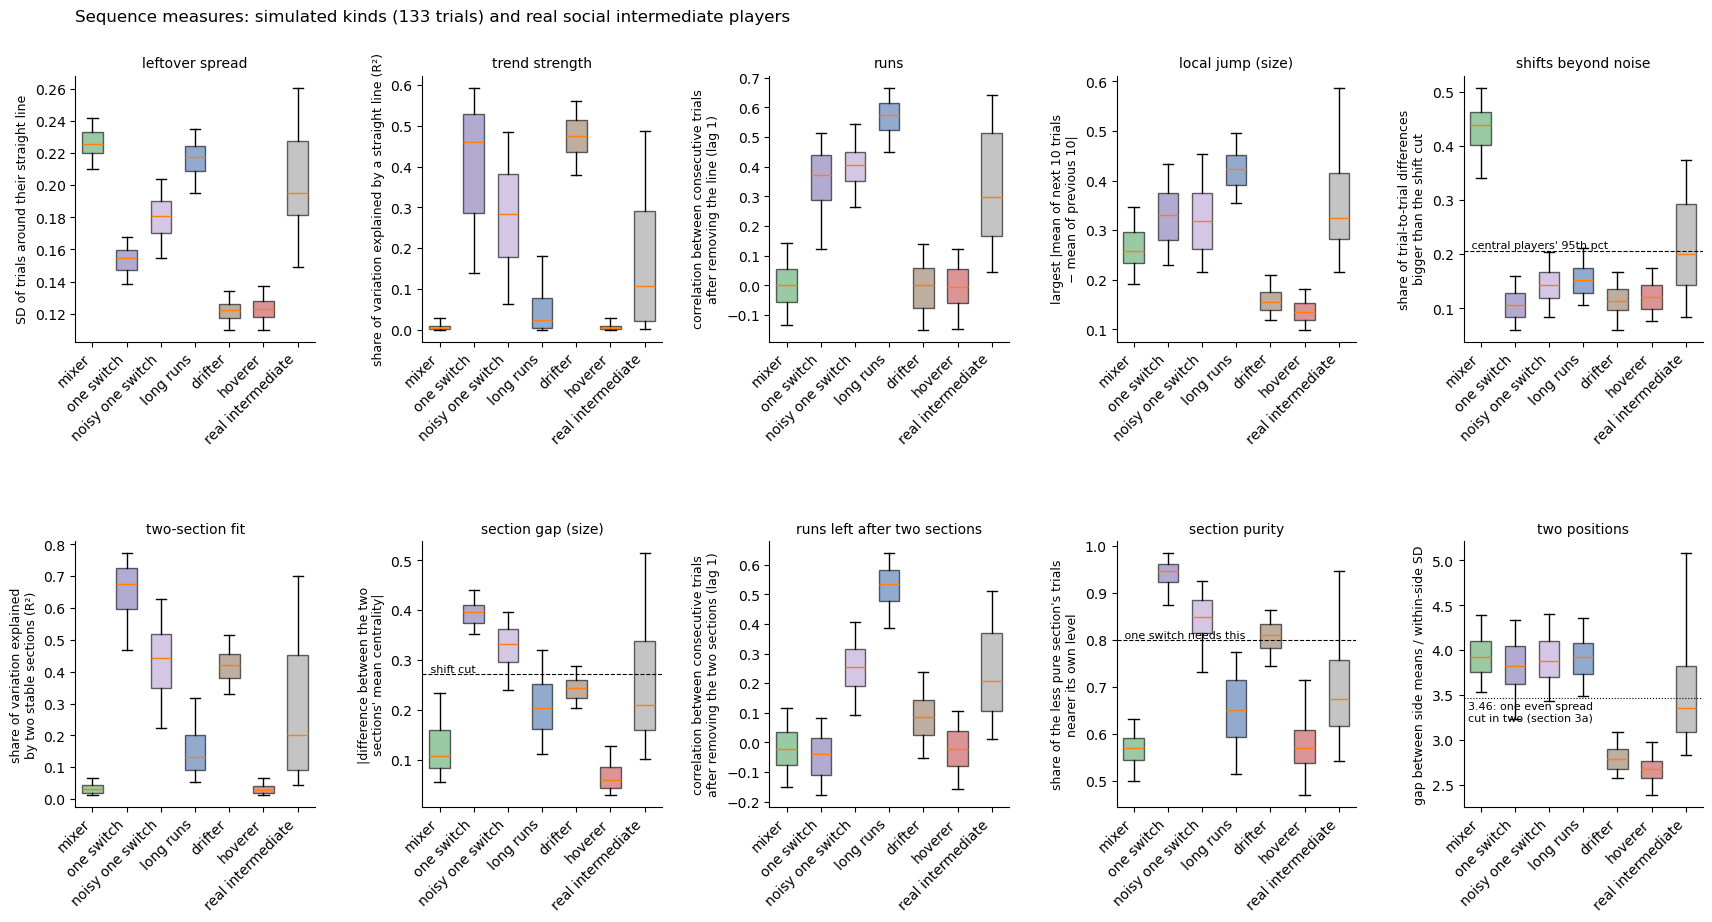

resid_sd             trend_r2             runs_r1             local_jump             shift_share             two_section_r2             section_gap             resid_runs_r1              \
                             0.1   0.5   0.9      0.1   0.5   0.9     0.1   0.5   0.9        0.1   0.5   0.9         0.1   0.5   0.9            0.1   0.5   0.9         0.1   0.5   0.9           0.1   0.5   0.9   
solo1  mixer                0.21  0.22  0.24     0.00  0.01  0.06   -0.19 -0.04  0.14      -0.25  0.13  0.24        0.34  0.43  0.53           0.03  0.06  0.13       -0.19 -0.07  0.18         -0.23 -0.06  0.10   
       one switch           0.14  0.15  0.17     0.24  0.47  0.62    0.15  0.33  0.50      -0.41 -0.26  0.41        0.06  0.11  0.17           0.59  0.71  0.80       -0.43 -0.34  0.42         -0.22 -0.08  0.11   
       noisy one switch     0.15  0.17  0.20     0.13  0.33  0.51    0.16  0.36  0.52      -0.37  0.25  0.40        0.09  0.15  0.23           0.28  0.50  0.70       -0.39  0.26  0.41         -0.06  0.20  0.36   
       long runs            0.17  0.21  0.23     0.00  0.06  0.29    0.31  0.49  0.63      -0.42  0.25  0.44        0.09  0.15  0.23           0.11  0.23  0.51       -0.33 -0.14  0.31          0.08  0.41  0.57   
       drifter              0.11  0.12  0.14     0.36  0.49  0.61   -0.22 -0.03  0.13      -0.19  0.13  0.20        0.06  0.11  0.19           0.36  0.46  0.56       -0.28  0.20  0.28         -0.13  0.04  0.23   
       hoverer              0.11  0.12  0.13     0.00  0.01  0.05   -0.21 -0.04  0.13      -0.14 -0.07  0.13        0.06  0.11  0.17           0.03  0.06  0.12       -0.10 -0.05  0.10         -0.23 -0.06  0.09   
social mixer                0.21  0.23  0.24     0.00  0.00  0.02   -0.11  0.00  0.12      -0.31 -0.18  0.30        0.37  0.44  0.49           0.01  0.03  0.06       -0.17 -0.06  0.16         -0.13 -0.02  0.09   
       one switch           0.14  0.15  0.17     0.20  0.46  0.57    0.20  0.37  0.48      -0.38  0.19  0.39        0.07  0.11  0.15           0.51  0.68  0.77       -0.41  0.28  0.42         -0.16 -0.04  0.07   
       noisy one switch     0.16  0.18  0.20     0.10  0.28  0.45    0.30  0.40  0.51      -0.40 -0.23  0.38        0.10  0.14  0.19           0.27  0.44  0.58       -0.37 -0.26  0.36          0.13  0.25  0.37   
       long runs            0.20  0.22  0.23     0.00  0.02  0.14    0.48  0.57  0.65      -0.46 -0.36  0.46        0.11  0.15  0.20           0.06  0.13  0.26       -0.27 -0.12  0.26          0.41  0.54  0.61   
       drifter              0.11  0.12  0.13     0.40  0.48  0.54   -0.12 -0.00  0.11      -0.17  0.13  0.19        0.08  0.11  0.16           0.35  0.42  0.49       -0.27  0.21  0.26         -0.01  0.09  0.20   
       hoverer              0.11  0.12  0.13     0.00  0.00  0.02   -0.11 -0.00  0.11      -0.16 -0.11  0.16        0.08  0.12  0.17           0.01  0.03  0.05       -0.09  0.03  0.10         -0.12 -0.02  0.09   
solo2  mixer                0.21  0.22  0.24     0.00  0.01  0.04   -0.18 -0.02  0.13      -0.26 -0.15  0.24        0.37  0.44  0.54           0.03  0.06  0.11       -0.17 -0.07  0.17         -0.21 -0.06  0.10   
       one switch           0.14  0.15  0.17     0.24  0.45  0.59    0.18  0.34  0.49      -0.42 -0.22  0.40        0.05  0.12  0.19           0.56  0.70  0.78       -0.43 -0.32  0.43         -0.24 -0.08  0.08   
       noisy one switch     0.15  0.18  0.20     0.11  0.32  0.50    0.17  0.36  0.53      -0.37  0.23  0.40        0.08  0.15  0.22           0.28  0.49  0.68       -0.37  0.22  0.40          0.01  0.19  0.37   
       long runs            0.17  0.20  0.23     0.00  0.05  0.25    0.32  0.50  0.63      -0.41 -0.23  0.43        0.10  0.15  0.22           0.10  0.22  0.48       -0.31 -0.01  0.32          0.20  0.42  0.56   
       drifter              0.11  0.12  0.14     0.37  0.49  0.60   -0.20 -0.04  0.13      -0.19  0.11  0.20        0.07  0.12  0.19           0.36  0.45  0.55       -0.29  0.18  0.30       

resid_sd             trend_r2             runs_r1             local_jump             shift_share             two_section_r2             section_gap             resid_runs_r1             purity_min        \
                  0.1   0.5   0.9      0.1   0.5   0.9     0.1   0.5   0.9        0.1   0.5   0.9         0.1   0.5   0.9            0.1   0.5   0.9         0.1   0.5   0.9           0.1   0.5   0.9        0.1   0.5   
session_type                                                                                                                                                                                                              
solo1            0.17  0.21  0.26      0.0  0.08  0.59   -0.10  0.31  0.67      -0.59 -0.25  0.36        0.08  0.24  0.44           0.09  0.25  0.86       -0.59 -0.19  0.28         -0.21  0.18  0.46       0.53  0.72   
social           0.16  0.19  0.24      0.0  0.11  0.45    0.08  0.30  0.61      -0.46 -0.23  0.44        0.09  0.20  0.37           0.05  0.20  0.55       -0.36 -0.16  0.26          0.03  0.21  0.48       0.56  0.67   
solo2            0.15  0.20  0.27      0.0  0.05  0.34   -0.09  0.25  0.64      -0.50 -0.12  0.39        0.07  0.22  0.42           0.07  0.18  0.60       -0.53 -0.15  0.35         -0.13  0.12  0.51       0.57  0.67   

                   gap_vs_sd              
               0.9       0.1   0.5   0.9  
session_type                              
solo1         0.96      2.59  3.67  5.54  
social        0.86      2.87  3.35  4.45  
solo2         0.88      2.72  3.36  6.07

purity_min             longest_excursion           
                               0.1   0.5   0.9               0.1  0.5   0.9
solo1  mixer                  0.51  0.58  0.67               2.0  3.0   5.0
       one switch             0.89  0.94  1.00               0.0  1.0   1.0
       noisy one switch       0.75  0.85  0.94               1.0  2.0   3.0
       long runs              0.57  0.70  0.88               2.0  5.0   9.0
       drifter                0.73  0.81  0.88               1.0  2.0   3.0
       hoverer                0.50  0.60  0.67               2.0  3.0   5.0
social mixer                  0.52  0.57  0.61               4.0  5.0   6.0
       one switch             0.89  0.95  0.98               1.0  1.0   2.0
       noisy one switch       0.77  0.85  0.91               2.0  3.0   4.0
       long runs              0.55  0.65  0.75               6.0  9.0  14.1
       drifter                0.76  0.81  0.85               2.0  2.5   4.0
       hoverer                0.50  0.57  0.66               3.0  5.0   6.0
solo2  mixer                  0.51  0.58  0.66               3.0  4.0   5.0
       one switch             0.88  0.95  1.00               0.0  1.0   1.0
       noisy one switch       0.76  0.85  0.93               1.0  3.0   3.0
       long runs              0.54  0.70  0.84               3.0  5.0   9.0
       drifter                0.73  0.81  0.89               1.0  2.0   3.0
       hoverer                0.52  0.60  0.68               2.0  3.0   5.0

p_trend  p_runs  p_jump  p_two_section  p_resid_runs
solo1  mixer                0.06    0.06    0.02           0.06          0.02
       one switch           1.00    0.84    0.94           1.00          0.02
       noisy one switch     0.94    0.88    0.71           0.99          0.48
       long runs            0.42    0.98    0.82           0.79          0.84
       drifter              1.00    0.05    0.08           1.00          0.16
       hoverer              0.05    0.06    0.05           0.04          0.02
social mixer                0.04    0.09    0.08           0.06          0.03
       one switch           1.00    0.94    0.61           1.00          0.01
       noisy one switch     0.98    1.00    0.50           1.00          0.90
       long runs            0.44    1.00    1.00           0.84          1.00
       drifter              1.00    0.06    0.01           1.00          0.26
       hoverer              0.04    0.04    0.04           0.05          0.02
solo2  mixer                0.03    0.06    0.05           0.03          0.02
       one switch           1.00    0.88    0.96           1.00          0.02
       noisy one switch     0.94    0.90    0.66           1.00          0.50
       long runs            0.43    0.98    0.86           0.78          0.90
       drifter              1.00    0.06    0.02           1.00          0.14
       hoverer              0.04    0.04    0.06           0.06          0.03

In [19]:
# simulate each kind at the median trial count of each session type, with social anchors
SIM_PARAMS = dict(low=round(own.loc['social', 'wall_mean'], 2), high=round(own.loc['social', 'centre_mean'], 2),
                  spread=round(own.loc['social', ['wall_sd', 'centre_sd']].mean(), 2),
                  hover_mean=round(typical.loc['social'].mean(), 2), hover_sd=round(central_sd.loc['social', 0.5], 3),
                  run_length=10)
print('simulation settings:', SIM_PARAMS)
lengths = players.groupby('session_type')['n_trials'].median().astype(int)


def simulate_all():
    """ Return the sequence measures, two-section fit, gap-to-spread ratio and its block interval for every
        simulated kind at each session type's median trial count. Takes no arguments. """

    parts = []
    for st in hc.SESSION_TYPES:
        sim_onset, sim_kinds = ml.simulate_sequences(lengths[st], 200, SIM_PARAMS, np.random.default_rng(lengths[st]))
        sim_sides = hc.side_positions(sim_onset, split['boundary']).assign(gap_vs_sd=lambda d: d['gap'] / d['sd_within'])
        sim_iv = hc.gap_ratio_intervals(sim_onset, split['boundary'], n_boot=N_PERM_DRIFT)
        sim_sections = ml.two_section_table(sim_onset).drop(columns=['section_a_end', 'section_b_start', 'level_a', 'level_b'])
        parts.append(ml.sequence_table(sim_onset).merge(sim_kinds, on=list(hc.KEYS))
                     .merge(sim_sections, on=list(hc.KEYS), how='left')
                     .merge(sim_sides[list(hc.KEYS) + ['gap_vs_sd']], on=list(hc.KEYS))
                     .merge(sim_iv[list(hc.KEYS) + IV_COLS], on=list(hc.KEYS), how='left').assign(length_of=st))
    return pd.concat(parts, ignore_index=True)


# simulate each kind, with the gap intervals cached as they take a few minutes
sim_seq = data_saving.cached('human_sim_sequences', simulate_all, recompute=RECOMPUTE,
                             stamp=dict(params=SIM_PARAMS, lengths=lengths.to_dict(), n_boot=N_PERM_DRIFT, boundary=split['boundary'],
                                        kinds=ml.SEQUENCE_KINDS, one_switch='anywhere, move up to 20%',
                                        sections=(ml.MIN_SECTION, ml.MAX_TRANSITION, ml.N_SHUFFLE_SECTIONS),
                                        noisy=(ml.SIM_EXCURSION_RATE, ml.SIM_EXCURSION_LEN, ml.SIM_CLOSENESS), purity=True))
# add shifts for the simulated players, regenerating the same trials (same seeds) with each session type's cut
sim_shifts = []
for st in hc.SESSION_TYPES:
    sim_onset, _ = ml.simulate_sequences(lengths[st], 200, SIM_PARAMS, np.random.default_rng(lengths[st]))
    sim_shifts.append(ml.shift_table(sim_onset.assign(session_type=st), shift_cut)
                      .merge(ml.robust_trend_table(sim_onset.assign(session_type=st)), on=list(hc.KEYS)).assign(length_of=st))
sim_seq = sim_seq.drop(columns=['shift_share', 'drift_change'], errors='ignore').merge(
    pd.concat(sim_shifts)[['experiment', 'player', 'length_of', 'shift_share', 'drift_change']],
    on=['experiment', 'player', 'length_of'])
MEASURES = ['resid_sd', 'trend_r2', 'runs_r1', 'local_jump', 'shift_share', 'two_section_r2', 'section_gap',
            'resid_runs_r1', 'purity_min', 'gap_vs_sd']
# say on each axis exactly what is plotted
AXIS_LABELS = {'resid_sd': 'SD of trials around their straight line',
               'trend_r2': 'share of variation explained by a straight line (R²)',
               'runs_r1': 'correlation between consecutive trials\nafter removing the line (lag 1)',
               'local_jump': 'largest |mean of next 10 trials\n− mean of previous 10|',
               'shift_share': 'share of trial-to-trial differences\nbigger than the shift cut',
               'two_section_r2': 'share of variation explained\nby two stable sections (R²)',
               'section_gap': "|difference between the two\nsections' mean centrality|",
               'resid_runs_r1': 'correlation between consecutive trials\nafter removing the two sections (lag 1)',
               'purity_min': "share of the less pure section's trials\nnearer its own level",
               'gap_vs_sd': 'gap between side means / within-side SD'}
KIND_COLOURS = dict(zip(ml.SEQUENCE_KINDS, ['#55A868', '#8172B3', '#B9A0D6', '#4C72B0', '#937860', '#C44E52']))


def plot_sim_measures():
    """ Plot each measure for every simulated kind at the social trial count, next to real social intermediate
        players. Takes no arguments. """

    sub = sim_seq[sim_seq['length_of'] == 'social']
    real = seq[(seq['session_type'] == 'social') & (seq['fixed'] == 'intermediate')]
    titles = {'resid_sd': 'leftover spread', 'trend_r2': 'trend strength', 'runs_r1': 'runs',
              'local_jump': 'local jump (size)', 'shift_share': 'shifts beyond noise', 'gap_vs_sd': 'two positions',
              'two_section_r2': 'two-section fit', 'section_gap': 'section gap (size)',
              'resid_runs_r1': 'runs left after two sections', 'purity_min': 'section purity'}
    fig, grid = plt.subplots(2, 5, figsize=(21, 9.5), gridspec_kw=dict(wspace=0.45, hspace=0.75))
    axes = grid.ravel()
    for ax, m in zip(axes, MEASURES):
        groups = [sub.loc[sub['kind'] == k, m] for k in ml.SEQUENCE_KINDS] + [real[m]]
        groups = [g.abs().dropna() if m in ('local_jump', 'section_gap') else g.dropna() for g in groups]
        box = ax.boxplot(groups, vert=True, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.6)
        for patch, colour in zip(box['boxes'], list(KIND_COLOURS.values()) + ['#9E9E9E']):
            patch.set_facecolor(colour)
            patch.set_alpha(0.6)
        if m == 'shift_share':
            # mark the shift share that central players' sessions rarely exceed
            ax.axhline(shift_ref['social'], color='k', ls='--', lw=0.8)
            ax.text(0.02, shift_ref['social'], ' central players\' 95th pct', transform=ax.get_yaxis_transform(),
                    ha='left', va='bottom', fontsize=8)
        if m == 'section_gap':
            # mark the smallest gap a one-switch player needs
            ax.axhline(shift_cut['social'], color='k', ls='--', lw=0.8)
            ax.text(0.02, shift_cut['social'], ' shift cut', transform=ax.get_yaxis_transform(), ha='left', va='bottom', fontsize=8)
        if m == 'purity_min':
            # mark the purity a one-switch player needs
            ax.axhline(ml.PURITY_MIN, color='k', ls='--', lw=0.8)
            ax.text(0.02, ml.PURITY_MIN, ' one switch needs this', transform=ax.get_yaxis_transform(), ha='left', va='bottom', fontsize=8)
        if m == 'gap_vs_sd':
            # mark the ratio one even spread of trials gives when cut in the middle
            ax.axhline(hc.ONE_FLAT_SPLIT_RATIO, color='k', ls=':', lw=0.8)
            ax.text(0.02, hc.ONE_FLAT_SPLIT_RATIO - 0.03, f'{hc.ONE_FLAT_SPLIT_RATIO:.2f}: one even spread\ncut in two (section 3a)',
                    transform=ax.get_yaxis_transform(), ha='left', va='top', fontsize=8)
        ax.set_ylabel(AXIS_LABELS[m], fontsize=9)
        ax.set_xticks(range(1, len(groups) + 1), list(ml.SEQUENCE_KINDS) + ['real intermediate'], rotation=45, ha='right')
        ax.set_title(titles[m], fontsize=10)
        ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle(f"Sequence measures: simulated kinds ({lengths['social']} trials) and real social intermediate players",
                 x=0.125, y=0.95, ha='left')
    plt.show()


plot_sim_measures()

# summarise each measure per kind and trial count, then for real intermediate players per session
display(sim_seq.groupby(['length_of', 'kind'], sort=False)[MEASURES].quantile([0.1, 0.5, 0.9]).unstack()
        .reindex(pd.MultiIndex.from_product([hc.SESSION_TYPES, ml.SEQUENCE_KINDS])).round(2))
display(seq[seq['fixed'] == 'intermediate'].groupby('session_type')[MEASURES].quantile([0.1, 0.5, 0.9]).unstack()
        .loc[list(hc.SESSION_TYPES)].round(2))
# summarise section purity and the longest excursion per kind
display(sim_seq.groupby(['length_of', 'kind'], sort=False)[['purity_min', 'longest_excursion']].quantile([0.1, 0.5, 0.9]).unstack()
        .reindex(pd.MultiIndex.from_product([hc.SESSION_TYPES, ml.SEQUENCE_KINDS])).round(2))
(sim_seq.groupby(['length_of', 'kind'], sort=False)[['p_trend', 'p_runs', 'p_jump', 'p_two_section', 'p_resid_runs']]
 .agg(lambda p: (p < 0.05).mean())
 .reindex(pd.MultiIndex.from_product([hc.SESSION_TYPES, ml.SEQUENCE_KINDS])).round(2))

**Interpretation**

All values are from the four tables above, at the social trial count unless stated (medians, with 10th and 90th percentiles where given).

- **Each simulated kind stands apart on at least one measure.**
  - Leftover spread is 0.12 for the drifter and hoverer, 0.15 for one switch, 0.18 for noisy one switch, and 0.22 to 0.23 for the mixer and long runs.
  - Trend strength is 0.46 to 0.48 for one switch and the drifter, 0.28 for noisy one switch, 0.02 for long runs, and 0.00 for the mixer and hoverer.
  - Runs is 0.57 for long runs, 0.40 for noisy one switch and 0.37 for one switch, and about 0 for the rest.
  - The two-section fit explains 0.68 of one switch's variation and 0.44 of noisy one switch's, against 0.42 for the drifter, 0.13 for long runs and 0.03 for the mixer and hoverer.
  - Section purity is 0.95 for one switch and 0.85 for noisy one switch, against 0.81 for the drifter, 0.65 for long runs and 0.57 for the mixer and hoverer. The longest excursion is 1 trial for one switch and 3 for noisy one switch, against 9 for long runs.
  - The share of trial-to-trial differences that are shifts is 0.44 for the mixer, and 0.11 to 0.15 for the rest.
  - The two-position ratio is 3.83 to 3.93 for the kinds with two positions, and 2.67 to 2.79 for the drifter and hoverer.
- **Purity separates both one-switch kinds from long runs in social.** One switch has purity of at least 0.89 and noisy one switch at least 0.77 (10th percentiles), while long runs reaches at most 0.75 (90th percentile). Noisy one switch's longest excursion is at most 4 trials (90th percentile), and long runs' at least 6 (10th percentile).
- **In the shorter solos, long runs overlaps one switch.** Long runs reaches purity 0.84 to 0.88 there (90th percentile), with excursions as short as 2 to 3 trials (10th percentile), as fewer trials hold fewer runs.
- **Leftover runs would reject most noisy one switches.** The runs-left test passes for 0.48 to 0.90 of noisy one-switch players, as their trials run together within a section. That is why purity, not leftover runs, decides whether a section is stable. One switch passes it in only 0.01 to 0.02, and long runs in 0.84 to 1.00.
- **One switch and drift are told apart by which description fits better.** Both one-switch kinds fit two sections better than a straight line (0.68 to 0.71 against 0.45 to 0.47 for one switch, 0.44 to 0.50 against 0.28 to 0.33 for noisy one switch, across trial counts). The drifter fits the line better (0.48 to 0.49 against 0.42 to 0.46).
- **Runs can look like a trend.** The long runs kind passes the trend test in 0.42 to 0.44 of players, as a few long runs can tilt a line. A significant trend alone does not mean drift.
- **The shuffle tests pass by chance at about the expected rate.** The mixer and hoverer pass each test in 0.02 to 0.09 of players.
- **Real intermediate players span several kinds.** In social, their leftover spread runs 0.16 to 0.24, trend strength 0.00 to 0.45, runs 0.08 to 0.61, two-section fit 0.05 to 0.55 and purity 0.56 to 0.86 (10th to 90th percentiles, second table).

### 5b. Where real intermediate players sit among the simulated kinds

**How to read the figure**
- One row per session type. Coloured points are simulated players at that session's median trial count, coloured by kind. Black points are real fixed-cut intermediate players.
- Left panel: x is trend strength, y is runs. A drifter sits at high trend and no runs, a one-switch player at high trend and high runs, a long-runs player at low trend and high runs. Mixers and hoverers sit near the origin.
- Right panel: x is leftover spread, y is the two-position ratio. The dotted horizontal line is one flat spread cut in two (3.46). The dashed vertical line is central players' median leftover spread (the "narrow" anchor). A hoverer sits left of it, a mixer to the right and above the dotted line.

**Why it is plotted.** It shows whether real intermediate players fall inside the simulated clouds, which would make clear labels possible, or between them.

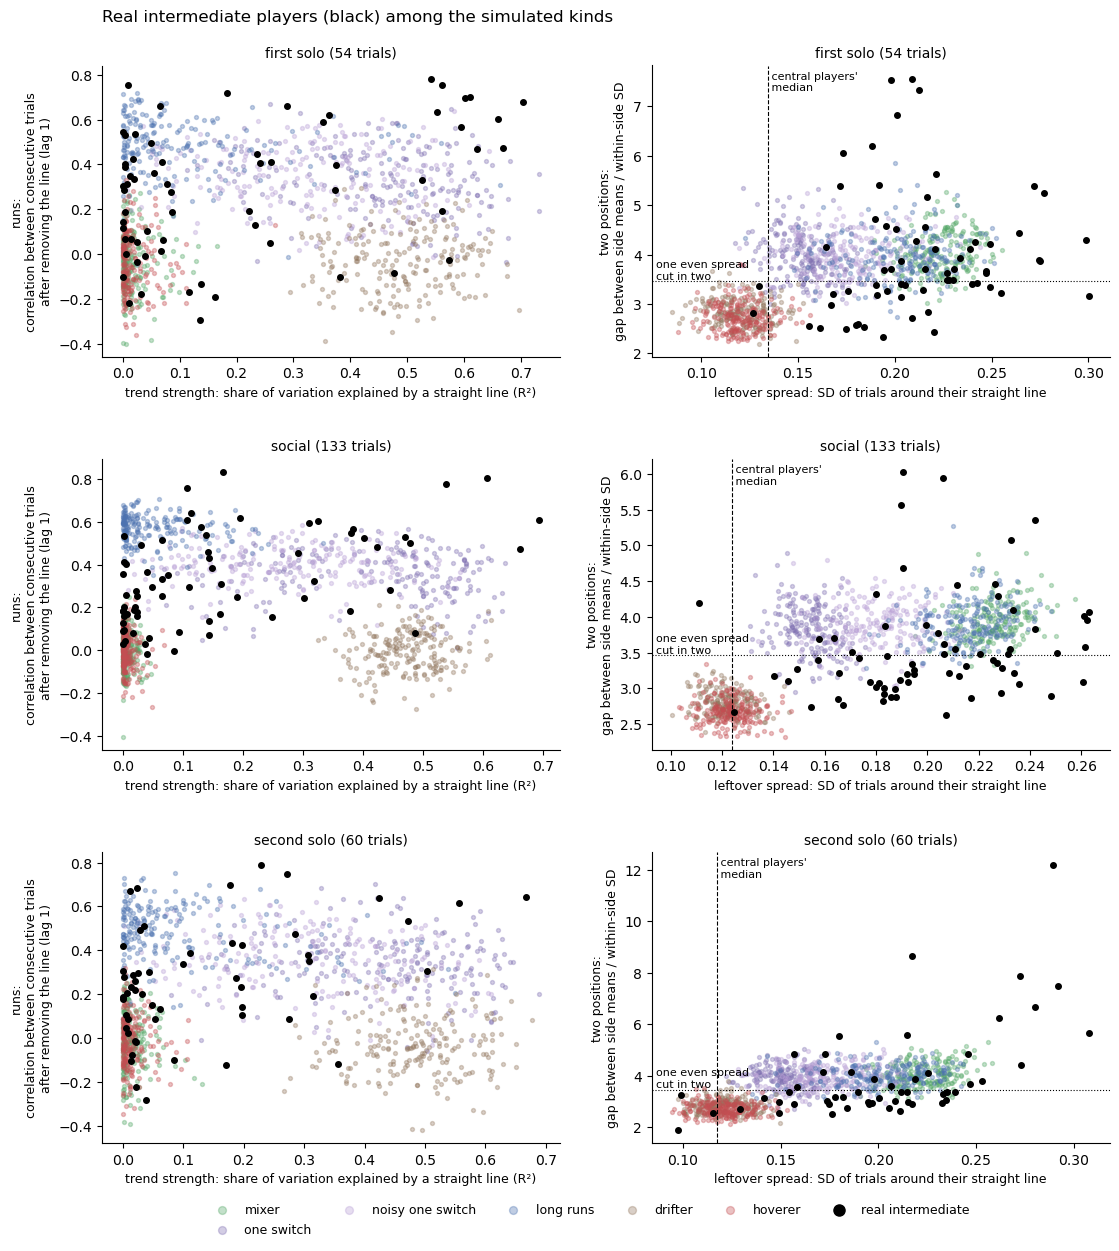

,narrow,two_positions,runs_sig,trend_sig,players
session_type,,,,,
solo1,2,38,40,34,65
social,1,30,57,47,69
solo2,3,22,33,24,54


In [20]:
def plot_real_vs_sim():
    """ Plot real intermediate players over the simulated kinds, as trend against runs and as leftover spread
        against the two-position ratio, one row per session type. Takes no arguments. """

    fig, axes = plt.subplots(3, 2, figsize=(13, 14), gridspec_kw=dict(hspace=0.35))
    for row, st in enumerate(hc.SESSION_TYPES):
        sim = sim_seq[sim_seq['length_of'] == st]
        real = seq[(seq['session_type'] == st) & (seq['fixed'] == 'intermediate')]
        for ax, (x, y) in zip(axes[row], (('trend_r2', 'runs_r1'), ('resid_sd', 'gap_vs_sd'))):
            for kind in ml.SEQUENCE_KINDS:
                s = sim[sim['kind'] == kind]
                ax.scatter(s[x], s[y], s=8, color=KIND_COLOURS[kind], alpha=0.35, label=kind)
            ax.scatter(real[x], real[y], s=16, color='k', label=f'real intermediate (n={len(real)})')
            if y == 'gap_vs_sd':
                # mark one even spread cut in two, and central players' median leftover spread
                ax.axhline(hc.ONE_FLAT_SPLIT_RATIO, color='k', ls=':', lw=0.8)
                ax.text(0.01, hc.ONE_FLAT_SPLIT_RATIO, 'one even spread\ncut in two', transform=ax.get_yaxis_transform(),
                        ha='left', va='bottom', fontsize=8)
                ax.axvline(central_sd.loc[st, 0.5], color='k', ls='--', lw=0.8)
                ax.text(central_sd.loc[st, 0.5], 0.98, " central players'\n median", transform=ax.get_xaxis_transform(),
                        ha='left', va='top', fontsize=8)
            ax.set_xlabel(f"{ {'trend_r2': 'trend strength', 'resid_sd': 'leftover spread'}[x]}: {AXIS_LABELS[x]}".replace('\n', ' '), fontsize=9)
            ax.set_ylabel(f"{ {'runs_r1': 'runs', 'gap_vs_sd': 'two positions'}[y]}:\n{AXIS_LABELS[y]}".replace('\n(lag 1)', ' (lag 1)'), fontsize=9)
            ax.set_title(f"{LABELS[st]} ({lengths[st]} trials)", fontsize=10)
            ax.spines[['top', 'right']].set_visible(False)
    handles, names = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, [n.split(' (n=')[0] for n in names], frameon=False, fontsize=9, markerscale=2, ncol=6,
               loc='upper center', bbox_to_anchor=(0.5, 0.075))
    fig.suptitle('Real intermediate players (black) among the simulated kinds', x=0.125, y=0.92, ha='left')
    plt.show()


plot_real_vs_sim()

# count real intermediate players inside each simple region, as a first look (not labels)
real_intermediate = seq[seq['fixed'] == 'intermediate']
(real_intermediate.assign(narrow=lambda d: d['resid_sd'] <= d['session_type'].map(central_sd[0.5]),
                   two_positions=lambda d: d['gap_vs_sd'] > hc.ONE_FLAT_SPLIT_RATIO,
                   runs_sig=lambda d: d['p_runs'] < 0.05, trend_sig=lambda d: d['p_trend'] < 0.05)
 .groupby('session_type')[['narrow', 'two_positions', 'runs_sig', 'trend_sig']].sum()
 .assign(players=real_intermediate.groupby('session_type').size()).loc[list(hc.SESSION_TYPES)])

**Interpretation**

- **Few real intermediate players are narrow enough to be hoverers.** 1 to 3 per session have a leftover spread no wider than central players' median (table).
- **Many show runs or a trend, but most sit between the simulated clouds** (left panels). In social, 57 of 69 pass the runs test and 47 the trend test, but most have weaker runs and trends than the simulated long-runs and one-switch players.
- **Being above the flat-spread line does not show two positions.** The line is the ratio one even spread gives on average, so a single-spread player can land above it by chance over their particular trials. 30 of 69 social intermediate players are above it, but only 13 (means) and 11 (medians) have a block interval entirely above it (section 3b). None have an interval above the two-position reference. So in social, a small number of players have sides clearly further apart than one spread gives, and none are clearly two-position players.
- **Some real players sit where no simulated kind does** (right panels). They have a wide leftover spread (about 0.17 to 0.26) and a two-position ratio below 3.46. Their trials spread broadly, with no sign of two separate positions. Under the mixer rule of 5c they are mixers if they shift back and forth beyond noise, in no particular order.

### 5c. Labels

Each intermediate player gets a label only when they clearly meet one rule. A p value below 0.05 counts as passing a shuffle test.

- **one switch**: all four of
  - the two-section fit passes its shuffle test,
  - the two sections' means differ by at least the shift cut (anchor table), so the move is intentional, not noise,
  - each section is stable, i.e. at least 80% of each section's trials sit nearer its own level (`purity_min` ≥ 0.80), and no trip to the other level lasts more than 5 trials (`longest_excursion` ≤ 5). 0.80 sits just above where simulated noisy one switch (10th percentile 0.77 in social) and long runs (90th percentile 0.75) meet,
  - two sections explain more of the player's variation than a straight line (`two_section_r2` > `trend_r2`). A slow drift is better described by the line, so this keeps drifters out.
- **long runs**: runs pass the shuffle test, and runs ≥ 0.46 (runs of about 5 or more trials, once real players' spread within a position is allowed for). Together with one switch, these are the switchers.
- **drifter**: the trend passes the shuffle test, trend strength ≥ 0.10, and the robust change is at least 0.135 in size (`drift_change`, about half the shift cut). 0.10 sits above simulated mixers and hoverers (90th percentile 0.02 to 0.06, 5a), so players with no steady trend stay out. It is low enough to include players whose line moves clearly but whose trials scatter widely around it (see the sandbox). The robust change keeps out players whose usual position stays put while trips bunched early or late tilt the line.
- **hoverer**: the trend test not passed, leftover spread no wider than central players' 75th percentile in that session (anchor table), and mean centrality near the middle, i.e. above peripheral players' 95th percentile mean and below central players' 5th percentile mean (`ml.middle_range`). So a hoverer waits between the two groups, near the boundary.
- **mixer**: the trend test not passed, wider than the hoverer cut, and a shift share above the shift reference (anchor table), so more shifts beyond noise than nearly all central players make. So the player moves back and forth by more than noise, with no steady trend. No two positions are required.
- **short runs**: runs pass the shuffle test, but the player fits none of the labels above (no stable two sections, runs too short for long runs, and not hoverer or mixer).
- **unclear**: weak or mixed signals. Mostly a trend that passes its test but is too weak for drifter, a narrow player outside the middle range, or a wide player with no runs whose shift share is not above the reference.

Labels are given in the order listed, so each player gets the first one they fit. Runs that pass the test do not block drifter, hoverer or mixer, as labels are descriptive. Whether a player's runs pass the test without being long runs is kept as `has_short_runs` beside every label. The switcher rules do not also require two separate positions. A table counts switchers whose interval clears each reference instead.

**Revisions.** A first set of rules used runs alone for switchers and had no short runs label (those players were unclear). It also split wide players with no order into mixer (two-position ratio above 3.46) and broad (at or below it). On simulated players it missed most single switches. The ratio above 3.46 is only what one even spread gives on average, so it cannot show two positions. The current rules add the short runs label, define a mixer by shifts beyond noise instead, and split switchers into one switch (two stable sections) and long runs. An intermediate version caught single switches with a large local jump, and split switchers by trend strength. That missed single switches near the start or end of a session, and the local jump now only describes switchers. A later version called a section stable only if no runs were left once the two sections were removed. Real players' consecutive trials often sit close together within one section, so that sent clear single switches with brief trips back to long runs. Section purity replaced it. Earlier versions also required drifters, hoverers and mixers to have no runs, which sent players with a clear trend, or who shift back and forth, to short runs when some short runs were present. Short runs is now the lowest-priority label. The drifter cut was also lowered from 0.30 to 0.10, after the sandbox showed players with a trend of 0.11 to 0.25 whose line clearly moves toward the wall. The middle range for hoverers was first the typical (median) peripheral to central mean (0.151 to 0.760 in social). Run on central and peripheral players (`strategy_labelling.ipynb`), it let narrow one-position players inside their own group count as hoverers, so it was narrowed to the 95th and 5th percentiles (0.309 to 0.645 in social). No intermediate player's label changed. Drifters then also needed a robust change of at least 0.135 (user's choice). Peripheral players in `strategy_labelling.ipynb` had been called drifters because trips bunched late in a session tilted their line. The second table shows both rule sets, so the changes can be checked.

**How to read the tables**
- The first gives the hoverer cut and the middle range per session type.
- The second runs both rule sets on the simulated kinds of 5a. Each row is one kind at one trial count, and each column the share of its players given that label. A rule set that works puts most of each kind in its own label. The first rules had one switcher label, so their switcher column holds both one switch and long runs. There is no simulated short runs kind, and broad exists only in the first rules.
- The third counts real intermediate players per label. The next counts, per label, how many also have short runs (`has_short_runs`).
- The fourth counts real switchers (one switch and long runs) whose gap interval lies below, across or above each reference (one even spread, two positions), with means and SD (`sd`) and with medians and IQR (`iqr`).
- The last gives each label's median measures.

**How to read the figure**

**Colour shows each trial's onset centrality value, not a label.** It is not the peripheral / central trial label (which cuts every trial at the boundary, 0.484 here, as in `strategy_characterisation` section 2), and not the player labels of this section.
- Colour runs on a continuous scale (colour bar). Orange is 0 (alcove back), white 0.5 and blue 1 (arena centre). A pale cell is a trial near the middle, on either side of the 0.484 boundary. Grey fills the end of shorter sessions.
- One panel per session type. Each row is one real intermediate player, and each column one trial in play order.
- Rows are grouped by label, with the group name and count on the left. Within a group, rows are sorted by mean centrality.

**Why it is plotted.** It checks by eye that each label's players look like the label (one colour change for one switch, long blocks of one colour for long runs, shorter patches for short runs, a gradual fade for drifters, pale rows for hoverers, speckled rows for mixers).

In [21]:
# set the hoverer cut (central players' 75th percentile of leftover spread)
narrow_cut = central_sd[0.75]
# set the middle range per session type (peripheral players' 95th to central players' 5th percentile mean)
middle = ml.middle_range(seq)
display(pd.DataFrame(dict(narrow_cut=narrow_cut, middle_low=[middle[st][0] for st in narrow_cut.index],
                          middle_high=[middle[st][1] for st in narrow_cut.index])).loc[list(hc.SESSION_TYPES)].round(3))

# run the first and the current rules on the simulated kinds, each at its own session type's cut
sim_as_sessions = sim_seq.assign(session_type=sim_seq['length_of'])
rule_sets = {'first rules': dict(one_switch_rule=None, short_runs=False, mixer_rule='point', allow_short_runs=False,
                                 trend_min=0.30),
             'current rules': dict(gap_min=shift_cut, drift_min=ml.DRIFT_MIN)}
# the first rules had one switcher label, so their one switch and long runs labels are joined back
FIRST_JOIN = {'one switch': 'switcher', 'long runs': 'switcher'}
RULE_COLUMNS = {'first rules': ['switcher', 'drifter', 'short runs', 'hoverer', 'mixer', 'broad', 'unclear'],
                'current rules': list(ml.LABELS)}
display(pd.concat({name: pd.crosstab([lab['length_of'], lab['kind']], lab['label'], normalize='index')
                   .reindex(index=pd.MultiIndex.from_product([hc.SESSION_TYPES, ml.SEQUENCE_KINDS]),
                            columns=RULE_COLUMNS[name], fill_value=0)
                   for name, kw in rule_sets.items()
                   for lab in [ml.assign_labels(sim_as_sessions, narrow_cut, middle, shift_ref=shift_ref, **kw)
                               .pipe(lambda d: d.assign(label=d['label'].replace(FIRST_JOIN)) if name == 'first rules' else d)]},
                  axis=1).round(2))

# label the real intermediate players and count each label
labelled = ml.assign_labels(seq[seq['fixed'] == 'intermediate'], narrow_cut, middle, shift_ref=shift_ref, gap_min=shift_cut,
                            drift_min=ml.DRIFT_MIN)
display(pd.crosstab(labelled['session_type'], labelled['label'], margins=True, margins_name='all')
        .reindex(index=list(hc.SESSION_TYPES) + ['all'], columns=list(ml.LABELS) + ['all'], fill_value=0))

# count, per label, how many players also have short runs
display(pd.crosstab([labelled['session_type'], labelled['label']], labelled['has_short_runs'].map({True: 'short runs', False: 'no short runs'}))
        .reindex(index=pd.MultiIndex.from_product([hc.SESSION_TYPES, ml.LABELS]), fill_value=0)
        .loc[lambda d: d.sum(axis=1) > 0])

# count switchers whose gap interval lies below, across or above each reference, in both views
switchers = labelled[labelled['label'].isin(['one switch', 'long runs'])]
ref_values5 = {('sd', 'one even spread'): hc.ONE_FLAT_SPLIT_RATIO, ('iqr', 'one even spread'): hc.ONE_FLAT_SPLIT_RATIO_IQR,
               ('sd', 'two positions'): refs5.loc['two positions', 'gap_vs_sd'],
               ('iqr', 'two positions'): refs5.loc['two positions', 'gap_vs_iqr']}
display(pd.concat({f'{view} vs {ref}': pd.crosstab([switchers['session_type'], switchers['label']],
                                                   hc.interval_position(switchers[f'gap_vs_{view}_lo'], switchers[f'gap_vs_{view}_hi'], value))
                   .reindex(index=pd.MultiIndex.from_product([hc.SESSION_TYPES, ['one switch', 'long runs']]),
                            columns=['below', 'overlaps', 'above'], fill_value=0)
                   for (view, ref), value in ref_values5.items()}, axis=1))

# summarise each label's measures
(labelled.groupby(['session_type', 'label'])
 [['n_trials', 'mean_centrality', 'resid_sd', 'trend_r2', 'runs_r1', 'shift_share', 'two_section_r2', 'section_gap',
   'switch_at', 'transition_len', 'resid_runs_r1', 'gap_vs_sd']]
 .median().reindex(pd.MultiIndex.from_product([hc.SESSION_TYPES, ml.LABELS])).dropna(how='all').round(2))

,narrow_cut,middle_low,middle_high
session_type,,,
solo1,0.160,0.274,0.647
social,0.145,0.309,0.645
solo2,0.160,0.292,0.651


first rules                                                current rules                                                   
label                      switcher drifter short runs hoverer mixer broad unclear    one switch long runs drifter hoverer mixer short runs unclear
solo1  mixer                   0.00    0.00        0.0    0.00  0.82  0.06    0.12          0.00      0.00    0.02    0.00  0.93       0.00    0.04
       one switch              0.19    0.14        0.0    0.00  0.00  0.00    0.68          0.99      0.00    0.01    0.00  0.00       0.00    0.00
       noisy one switch        0.24    0.10        0.0    0.00  0.00  0.00    0.66          0.70      0.05    0.20    0.00  0.00       0.05    0.00
       long runs               0.62    0.00        0.0    0.00  0.00  0.00    0.36          0.24      0.53    0.04    0.01  0.01       0.16    0.02
       drifter                 0.00    0.94        0.0    0.00  0.00  0.00    0.06          0.06      0.00    0.94    0.00  0.00       0.00    0.00
       hoverer                 0.00    0.00        0.0    0.90  0.00  0.00    0.10          0.00      0.00    0.02    0.95  0.00       0.00    0.04
social mixer                   0.00    0.00        0.0    0.00  0.85  0.02    0.13          0.00      0.00    0.00    0.00  0.96       0.00    0.04
       one switch              0.18    0.04        0.0    0.00  0.00  0.00    0.78          1.00      0.00    0.00    0.00  0.00       0.00    0.00
       noisy one switch        0.22    0.00        0.0    0.00  0.00  0.00    0.78          0.76      0.02    0.16    0.00  0.00       0.06    0.00
       long runs               0.94    0.00        0.0    0.00  0.00  0.00    0.06          0.01      0.93    0.02    0.00  0.00       0.04    0.00
       drifter                 0.00    0.94        0.0    0.00  0.00  0.00    0.06          0.00      0.00    1.00    0.00  0.00       0.00    0.00
       hoverer                 0.00    0.00        0.0    0.90  0.00  0.00    0.09          0.00      0.00    0.00    0.95  0.00       0.00    0.05
solo2  mixer                   0.00    0.00        0.0    0.00  0.84  0.06    0.09          0.00      0.00    0.02    0.00  0.97       0.00    0.02
       one switch              0.15    0.10        0.0    0.00  0.00  0.00    0.76          1.00      0.00    0.00    0.00  0.00       0.00    0.00
       noisy one switch        0.26    0.08        0.0    0.00  0.00  0.00    0.66          0.78      0.03    0.15    0.00  0.00       0.04    0.00
       long runs               0.62    0.00        0.0    0.00  0.00  0.00    0.37          0.17      0.55    0.10    0.01  0.03       0.14    0.01
       drifter                 0.00    0.92        0.0    0.00  0.00  0.00    0.08          0.09      0.00    0.91    0.00  0.00       0.00    0.00
       hoverer                 0.00    0.00        0.0    0.92  0.00  0.00    0.08          0.00      0.00    0.01    0.96  0.00       0.00    0.03

label,one switch,long runs,drifter,hoverer,mixer,short runs,unclear,all
session_type,,,,,,,,
solo1,20,6,10,1,17,8,3,65
social,12,15,11,0,19,7,5,69
solo2,13,4,10,7,18,1,1,54
all,45,25,31,8,54,16,9,188


has_short_runs     no short runs  short runs
solo1  one switch              8          12
       long runs               6           0
       drifter                 7           3
       hoverer                 1           0
       mixer                  13           4
       short runs              0           8
       unclear                 3           0
social one switch              4           8
       long runs              15           0
       drifter                 1          10
       mixer                   5          14
       short runs              0           7
       unclear                 5           0
solo2  one switch              8           5
       long runs               4           0
       drifter                 6           4
       hoverer                 3           4
       mixer                  11           7
       short runs              0           1
       unclear                 1           0

sd vs one even spread                iqr vs one even spread                sd vs two positions                iqr vs two positions               
col_0                             below overlaps above                  below overlaps above               below overlaps above                below overlaps above
solo1  one switch                     0        7    13                      0        9    11                   5       13     2                    5       14     1
       long runs                      1        4     1                      0        5     1                   4        2     0                    3        3     0
social one switch                     0        8     4                      0        9     3                   8        4     0                    8        4     0
       long runs                      1        7     7                      0        9     6                  12        3     0                   10        5     0
solo2  one switch                     0        2    11                      0        4     9                   6        6     1                    4        7     2
       long runs                      0        0     4                      0        0     4                   1        2     1                    1        2     1

n_trials  mean_centrality  resid_sd  trend_r2  runs_r1  shift_share  two_section_r2  section_gap  switch_at  transition_len  resid_runs_r1  gap_vs_sd
solo1  one switch      59.0             0.44      0.20      0.56     0.60         0.10            0.73        -0.54       0.46             1.0           0.25       4.94
       long runs       56.5             0.54      0.26      0.02     0.54         0.18            0.25         0.19       0.72             0.0           0.47       3.62
       drifter         49.5             0.36      0.22      0.24     0.09         0.28            0.35        -0.28       0.33             0.5           0.02       3.82
       hoverer         25.0             0.60      0.16      0.02    -0.04         0.25            0.05         0.07       0.40             0.0          -0.04       2.55
       mixer           44.0             0.56      0.22      0.01     0.07         0.33            0.11         0.07       0.44             0.0          -0.00       3.26
       short runs      50.0             0.59      0.22      0.04     0.36         0.22            0.16         0.13       0.60             0.0           0.28       3.36
       unclear         57.0             0.50      0.18      0.07     0.01         0.25            0.14         0.22       0.21             0.0          -0.03       2.53
social one switch     131.0             0.52      0.19      0.45     0.50         0.16            0.61        -0.31       0.39             4.5           0.22       3.91
       long runs      136.0             0.45      0.23      0.14     0.58         0.14            0.32        -0.30       0.61             0.0           0.48       3.95
       drifter        133.0             0.42      0.18      0.16     0.25         0.18            0.24        -0.21       0.39             0.0           0.15       3.22
       mixer          133.0             0.54      0.21      0.00     0.18         0.30            0.06        -0.09       0.41             0.0           0.14       3.20
       short runs     130.0             0.53      0.17      0.05     0.35         0.19            0.13         0.14       0.50             0.0           0.29       2.88
       unclear        136.0             0.47      0.22      0.04     0.03         0.34            0.10         0.20       0.31             1.0          -0.04       3.31
solo2  one switch      59.0             0.48      0.22      0.28     0.51         0.16            0.57        -0.42       0.66             0.0           0.12       4.86
       long runs       64.5             0.51      0.26      0.03     0.68         0.13            0.28        -0.27       0.37             1.0           0.59       5.26
       drifter         62.5             0.46      0.19      0.20     0.17         0.22            0.32        -0.20       0.53             0.5           0.11       3.37
       hoverer         61.0             0.47      0.13      0.02     0.20         0.10            0.10        -0.06       0.77             0.0           0.09       2.71
       mixer           61.0             0.51      0.21      0.02     0.14         0.31            0.10        -0.02       0.46             0.0           0.08       3.09
       short runs      63.0             0.58      0.18      0.01     0.23         0.18            0.12        -0.14       0.70             0.0           0.16       2.74
       unclear         64.0             0.50      0.22      0.09    -0.10         0.43            0.12        -0.16       0.52             0.0          -0.12       2.99

#### Short runs beside the other labels

Labels are given in order, so a player labelled one switch, drifter, hoverer or mixer may also have runs that pass the shuffle test. Without their own label, they would be labelled short runs. This shows how common short runs are as a description, beside the label a player is given.

A player **would count as short runs** if their runs pass the shuffle test (`p_runs` < 0.05), which is the `has_short_runs` column. For a one-switch player the switch itself leaves runs around a straight line, so for them it means runs left inside the two sections instead (`p_resid_runs` < 0.05). Clean simulated one-switch players show this in only 0.01 to 0.02 of cases (5a table). For four labels the answer is fixed by the rules, so they are left out of the figure.
- Every long-runs and short-runs player passes it, as it is part of their rule.
- No unclear player does, as an unclear player who passed it would be labelled short runs.

**How to read the figure**
- One group of bars per label (one switch, drifter, hoverer, mixer), one bar per session type (colour).
- Bar height is the share of that label's players with short runs (`has_short_runs`), so the share who would be short runs without their label.
- The text above each bar is the count (players with runs out of players with the label). A label with no players in a session has no bar.

**Why it is plotted.** It shows whether short runs is mostly a separate pattern, or mostly a description that sits alongside other labels.

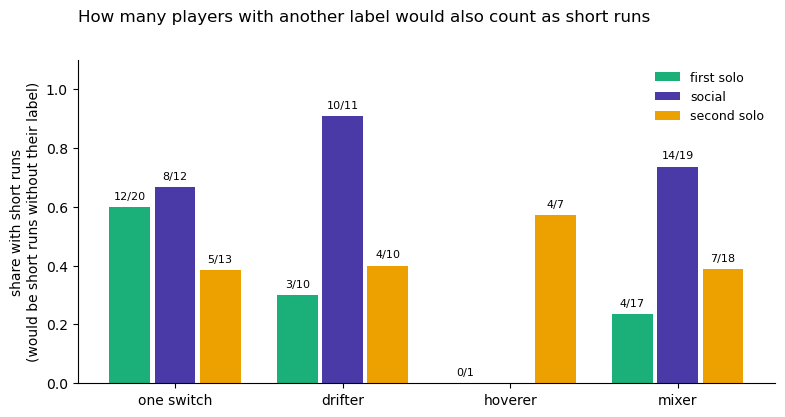

In [22]:
def plot_short_runs_share():
    """ Plot, for one switch, drifter, hoverer and mixer, the share of each session's intermediate players with short
        runs beside their label (has_short_runs), i.e. who would be labelled short runs without their own label.
        Takes no arguments. """

    shown = ['one switch', 'drifter', 'hoverer', 'mixer']
    width = 0.27
    fig, ax = plt.subplots(figsize=(9, 4.2))
    for j, st in enumerate(hc.SESSION_TYPES):
        sub = labelled[labelled['session_type'] == st]
        for i, lab in enumerate(shown):
            group = sub[sub['label'] == lab]
            if group.empty:
                continue
            # get the share of the label's players with short runs (inside the sections for one switch)
            n_runs = int(group['has_short_runs'].sum())
            x = i + (j - 1) * width
            ax.bar(x, n_runs / len(group), width * 0.9, color=hc.SESSION_PALETTE[st],
                   label=LABELS[st] if i == next(k for k, l in enumerate(shown) if (sub['label'] == l).any()) else None)
            ax.text(x, n_runs / len(group) + 0.02, f'{n_runs}/{len(group)}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(range(len(shown)), shown)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel('share with short runs\n(would be short runs without their label)')
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, fontsize=9)
    fig.suptitle('How many players with another label would also count as short runs', x=0.125, y=1.0, ha='left')
    plt.show()


plot_short_runs_share()

**Interpretation**

- **Most social drifters, mixers and one-switch players also have short runs.** In social, 10 of the 11 drifters, 14 of the 19 mixers and 8 of the 12 one-switch players have short runs (figure). For one switch these are runs inside their two sections.
- **Short runs is mostly a description in social.** 32 social players with short runs sit under another label, against 7 labelled short runs.
- **Hoverers are rare.** None in social, 1 in the first solo and 7 in the second, 4 of them with short runs.

#### All labels each player passes

The priority order gives each player one label, the first rule they fit. But a player can pass several rules, e.g. a long-runs player whose line also drifts toward the wall. So every rule is also checked on its own, ignoring the order.

- `fits_one_switch`, `fits_long_runs`, `fits_drifter`, `fits_hoverer`, `fits_mixer` and `fits_short_runs` say whether the player passes that label's own rule (short runs is `has_short_runs`).
- `all_labels` lists every label passed, in priority order, or "unclear" if none.
- Some pairs cannot occur together. Hoverer and mixer need opposite spreads (narrow against wide), and drifter needs a trend that hoverer and mixer rule out.

**How to read the figure**
- One panel per session type. Each row is a priority label (the label a player was given), and each column a label they also pass.
- Each cell is the share of that row's players who pass the column's rule, with the count below it. The diagonal is 1.00 by definition.
- Darker cells mean more of the row's players also pass that label.

**How to read the tables.**
- The first gives the number of labels each player passes (0 = unclear), per session.
- The second counts the players passing each label's rule, per session. A player passing several labels is counted under each, so the counts add up to more than the number of intermediate players (last row). Unclear counts players who pass no label.

**Why it is plotted.** It shows which labels overlap, so a player's priority label can be read alongside the other patterns they also show.

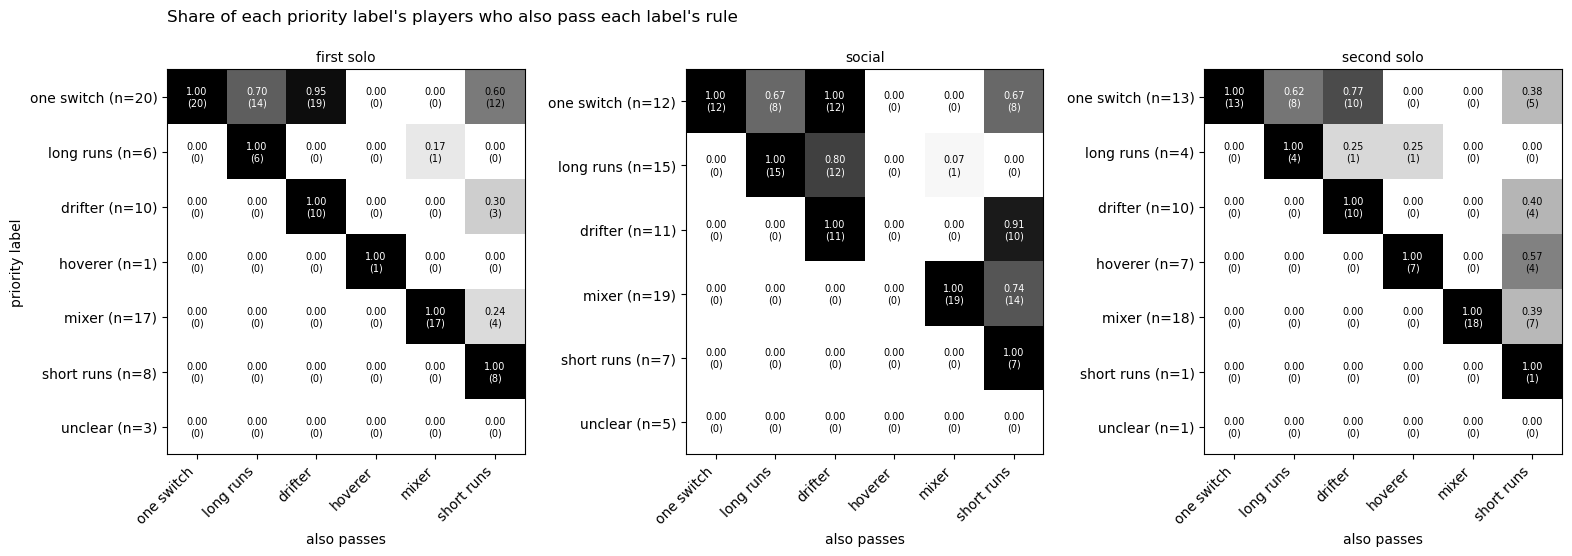

labels passed,0,1,2,3,4
session_type,,,,,
solo1,3,35,11,6,10
social,5,15,40,2,7
solo2,1,25,20,4,4


In [23]:
FIT_COLUMNS = [l for l in ml.LABELS if l != 'unclear']


def plot_label_overlap():
    """ Plot, for each priority label, the share of its players who also pass each label's own rule, one panel
        per session type. Takes no arguments. """

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw=dict(wspace=0.45))
    for ax, st in zip(axes, hc.SESSION_TYPES):
        sub = labelled[labelled['session_type'] == st]
        rows = [l for l in ml.LABELS if (sub['label'] == l).any()]
        share = np.full((len(rows), len(FIT_COLUMNS)), np.nan)
        count = np.zeros_like(share, dtype=int)
        for i, lab in enumerate(rows):
            group = sub[sub['label'] == lab]
            for j, fit in enumerate(FIT_COLUMNS):
                # get the share of the label's players who pass this other label's rule
                count[i, j] = int(group['fits_' + fit.replace(' ', '_')].sum())
                share[i, j] = count[i, j] / len(group)
        ax.imshow(share, cmap='Greys', vmin=0, vmax=1, aspect='auto')
        for i in range(len(rows)):
            for j in range(len(FIT_COLUMNS)):
                ax.text(j, i, f'{share[i, j]:.2f}\n({count[i, j]})', ha='center', va='center', fontsize=7,
                        color='white' if share[i, j] > 0.6 else 'black')
        n = sub['label'].value_counts()
        ax.set_yticks(range(len(rows)), [f'{l} (n={n[l]})' for l in rows])
        ax.set_xticks(range(len(FIT_COLUMNS)), FIT_COLUMNS, rotation=45, ha='right')
        ax.set_xlabel('also passes')
        ax.set_title(LABELS[st], fontsize=10)
    axes[0].set_ylabel('priority label')
    fig.suptitle('Share of each priority label\'s players who also pass each label\'s rule', x=0.125, y=1.0, ha='left')
    plt.show()


plot_label_overlap()

# count how many labels each player passes (0 = unclear)
n_passed = labelled[['fits_' + l.replace(' ', '_') for l in FIT_COLUMNS]].sum(axis=1)
pd.crosstab(labelled['session_type'], n_passed.rename('labels passed')).loc[list(hc.SESSION_TYPES)]

In [24]:
# count the players passing each label's rule per session, so a player passing several labels counts in each
passing = pd.DataFrame({lab: labelled.groupby('session_type')['fits_' + lab.replace(' ', '_')].sum() for lab in FIT_COLUMNS}).T
passing.loc['unclear'] = (labelled['all_labels'] == 'unclear').groupby(labelled['session_type']).sum()
passing.loc['intermediate players'] = labelled.groupby('session_type').size()
passing[list(hc.SESSION_TYPES)].astype(int)

session_type,solo1,social,solo2
one switch,20,12,13
long runs,20,23,12
drifter,29,35,21
hoverer,1,0,8
mixer,18,20,18
short runs,27,39,21
unclear,3,5,1
intermediate players,65,69,54


**Interpretation**

All values are from the figure and table above.

- **Most social intermediate players pass more than one label.** 40 of 69 pass two labels, 2 pass three and 7 pass four. 15 pass one, and 5 pass none (unclear).
- **Counting every label passed, short runs and drift are the commonest patterns in social.** Of 69 players, 39 pass short runs and 35 drifter, against 23 long runs, 20 mixer and 12 one switch. As priority labels, drifter (11) and short runs (7) are far smaller, because most of these players also fit a label earlier in the order.
- **Every social one-switch player also passes the drifter rule** (12 of 12), and 8 of 12 also pass long runs. A single switch tilts the straight line, so passing the drifter rule here partly reflects the switch itself. The one-switch rule separates them by needing two sections to fit better than the line.
- **12 of 15 social long-runs players also pass the drifter rule.** Runs that fall unevenly across the session tilt the line as well, so this does not always mean a steady drift. Some long-runs players in the sandbox do move clearly toward the wall.
- **Short runs sits beside most drifters and mixers.** 10 of 11 social drifters and 14 of 19 mixers also pass it.
- **Drifter, hoverer and mixer never occur together**, as their rules need a trend or no trend, and a narrow or wide spread.

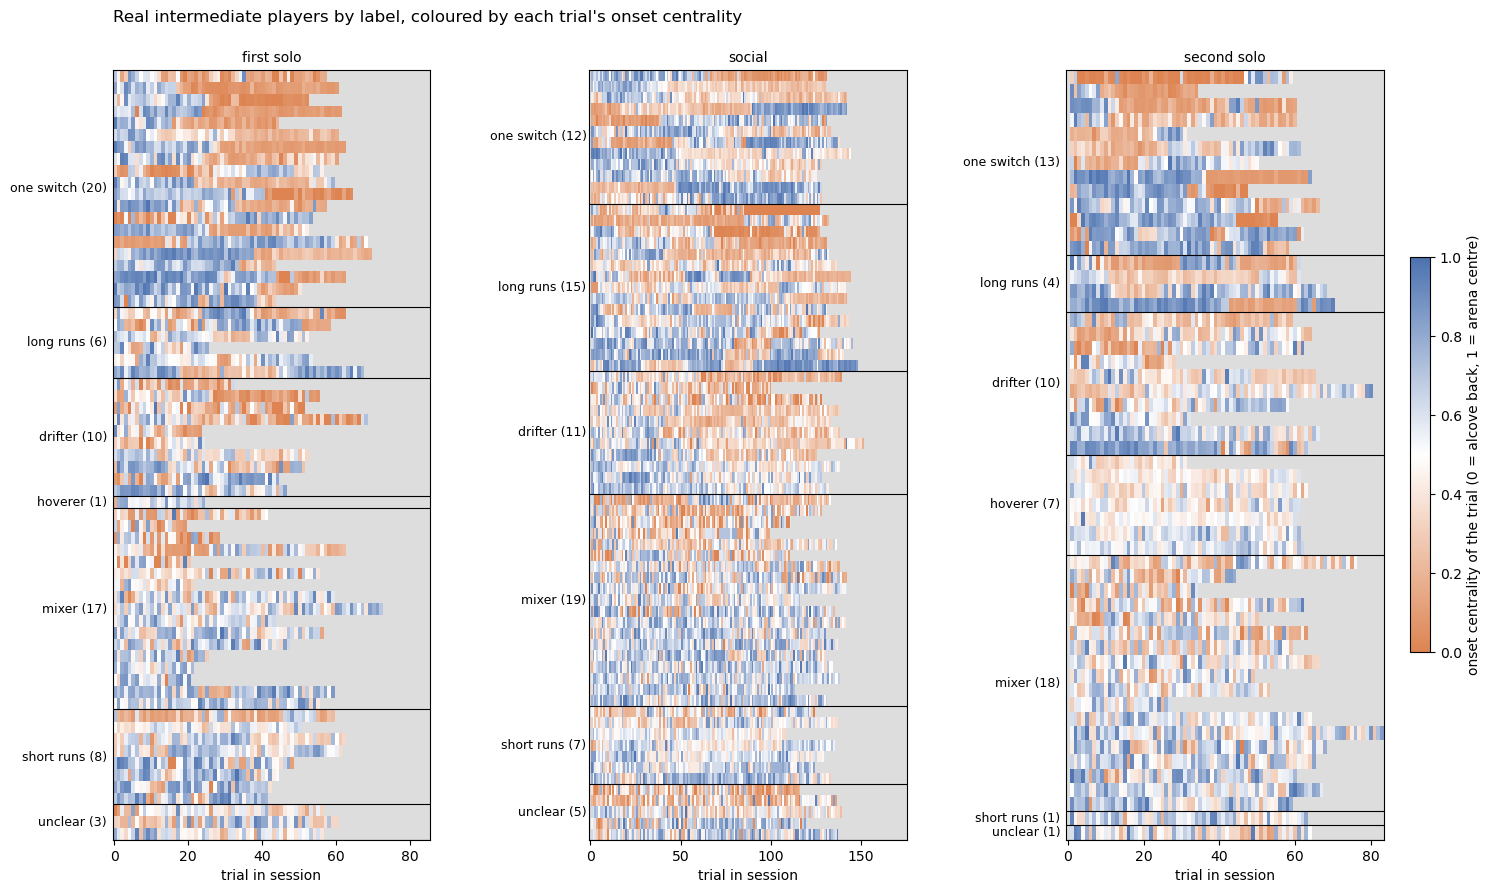

In [25]:
def plot_label_rasters():
    """ Plot every real intermediate player's onset centrality trial by trial, grouped by label, one panel per
        session type. Takes no arguments. """

    from matplotlib.colors import LinearSegmentedColormap
    cmap = LinearSegmentedColormap.from_list('wall_centre', [hc.STRAT_PALETTE['peripheral'], '#FFFFFF', hc.STRAT_PALETTE['central']])
    cmap.set_bad('#DDDDDD')
    order = {lab: i for i, lab in enumerate(ml.LABELS)}
    fig, axes = plt.subplots(1, 3, figsize=(17, 10), gridspec_kw=dict(width_ratios=[lengths.max()] * 3, wspace=0.5))
    for ax, st in zip(axes, hc.SESSION_TYPES):
        sub = (labelled[labelled['session_type'] == st]
               .assign(rank=lambda d: d['label'].map(order)).sort_values(['rank', 'mean_centrality']))
        trials = onset[onset['session_type'] == st]
        mat = np.full((len(sub), int(trials['trial_pos'].max()) + 1), np.nan)
        for row, (e, p) in enumerate(zip(sub['experiment'], sub['player'])):
            t = trials[(trials['experiment'] == e) & (trials['player'] == p)]
            mat[row, t['trial_pos'].to_numpy(int)] = t['centrality'].to_numpy()
        image = ax.imshow(mat, aspect='auto', cmap=cmap, vmin=0, vmax=1, interpolation='nearest')
        # separate and name the label groups
        edges = np.r_[0, np.cumsum(sub['label'].value_counts().reindex(ml.LABELS, fill_value=0).to_numpy())]
        for lab, lo, hi in zip(ml.LABELS, edges[:-1], edges[1:]):
            if hi > lo:
                ax.axhline(hi - 0.5, color='k', lw=0.8)
                ax.text(-2, (lo + hi - 1) / 2, f'{lab} ({hi - lo})', ha='right', va='center', fontsize=9)
        ax.set_yticks([])
        ax.set_xlabel('trial in session')
        ax.set_title(LABELS[st], fontsize=10)
    # show the colour scale, which is each trial's own centrality, not the peripheral / central trial label
    bar = fig.colorbar(image, ax=axes, fraction=0.015, pad=0.02)
    bar.set_label('onset centrality of the trial (0 = alcove back, 1 = arena centre)')
    fig.suptitle('Real intermediate players by label, coloured by each trial\'s onset centrality', x=0.125, y=0.94, ha='left')
    plt.show()


plot_label_rasters()

**Interpretation**

All values are from the tables in 5a and 5c.

- **The current rules recover each simulated kind.**
  - One switch goes to one switch in 0.99 to 1.00 of players at every trial count, wherever its switch falls. With the first rules, only 0.15 to 0.19 were called switchers.
  - Noisy one switch, with brief trips inside each section, goes to one switch in 0.70 to 0.78. Most of the rest go to drifter (0.15 to 0.20), where a section falls just below the purity cut but the line still moves.
  - Long runs goes to long runs in 0.93 at the social trial count. In the shorter solos it is 0.53 to 0.55, with 0.17 to 0.24 called one switch, 0.14 to 0.16 short runs and 0.04 to 0.10 drifter.
  - The drifter goes to drifter in 0.91 to 1.00 (1.00 in social). The mixer goes to mixer in 0.93 to 0.97, and the hoverer to hoverer in 0.95 to 0.96.
- **Few kinds without a trend are called drifters.** 0.00 to 0.02 of simulated mixers and hoverers are, as the 0.10 cut sits above their trend strength (90th percentile 0.02 to 0.06, 5a).
- **The shift reference separates mixers from one-position players.** The reference is 0.21 in social (0.26 and 0.23 in the solos). In simulated one-position kinds (drifter, hoverer), 0.11 to 0.12 of trial-to-trial differences are shifts, against 0.44 for simulated mixers in social (5a).
- **Social intermediate players mostly mix, wait in runs, switch once or drift.** Of 69, 19 are mixers, 15 long runs, 12 one switch and 11 drifters. 7 are short runs and 5 unclear, with no hoverers. Over all three sessions (188 player sessions), there are 54 mixers, 45 one switch, 31 drifters, 25 long runs, 16 short runs, 9 unclear and 8 hoverers.
- **Social drifters drift weakly toward the wall.** Their median trend strength is 0.16 and their median line moves 0.21 toward the wall over the session.
- **One switch is commonest in the first solo.** It covers 20 of 65 first-solo players, against 12 of 69 in social and 13 of 54 in the second solo. In the solos part of this may be long runs mislabelled (above).
- **One-switch players mostly move toward the wall.** The median second section sits 0.31 below the first in social, 0.54 below in the first solo and 0.42 below in the second. In social, the median switch falls 39% of the way through the session, over a transition of 4.5 trials.
- **Social mixers shift back and forth beyond noise, with no steady trend.** For the median social mixer, 0.30 of their trial-to-trial differences are bigger than the shift cut, above the 0.21 reference, with runs of 0.18 and trend strength of 0.00.
- **Few social switchers can be shown to use two separate positions.** 4 of the 12 one-switch players and 7 of the 15 long-runs players have a gap interval entirely above one even spread (means). None are entirely above the two-position reference.

## Sandbox

Exploratory plots, kept apart from the analysis above. Nothing here feeds the labels.

### Weak-trend short-runs players (social)

These are the social intermediate players whose trend passes its shuffle test with a trend strength below 0.30 (the earlier drifter cut), and who are now labelled drifter (trend strength at least 0.10) or short runs (below it). Under the earlier cut they were short runs or unclear. The first figure shows those whose straight line falls over the session (toward the wall), the second those whose line rises (toward the centre).

**How to read the figures**
- One panel per player. The title gives the experiment and player, their trend strength, and how far their straight line moves from the first trial to the last (negative = toward the wall). The second line lists every label the player passes (`all_labels`), the first being their priority label.
- x is the trial in the session (the spawn trial is dropped, so social starts at trial 1). y is onset centrality (1 = arena centre, 0 = alcove back).
- Grey points joined by a thin line are each trial. The black line is the player's straight-line fit. The dashed line is the trial boundary (0.484).

**Why it is plotted.** To see by eye whether the weak trend is a steady slide, a change over part of the session, or a few runs that tilt the line.

toward the wall: 11 | toward the centre: 3


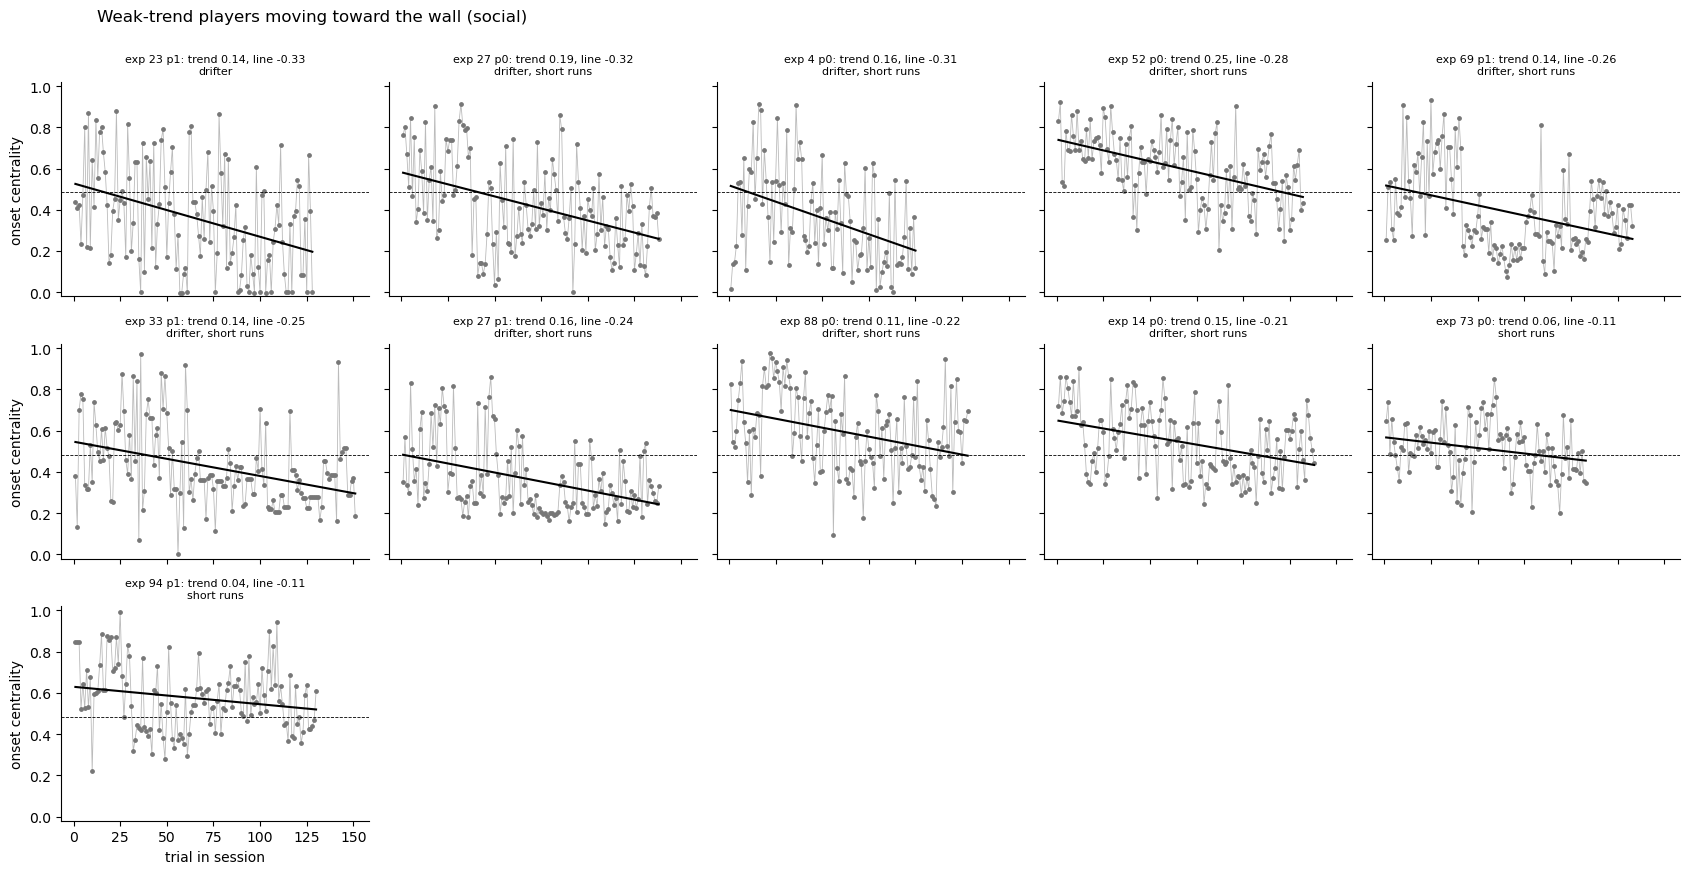

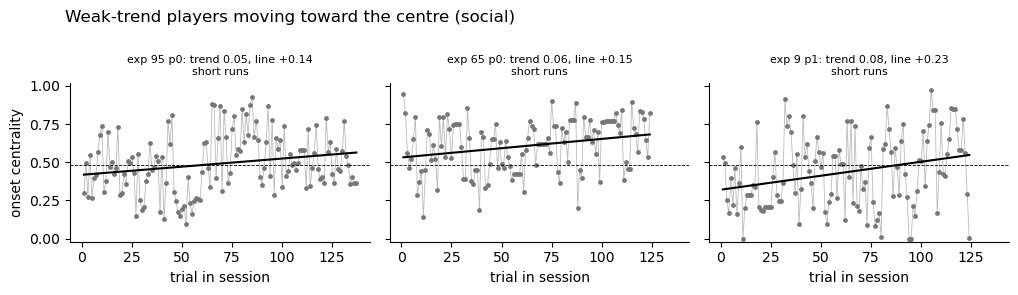

In [26]:
# find the social players with a significant trend below the earlier drifter cut (0.30) who are now drifters or short runs
weak_trend = labelled[(labelled['session_type'] == 'social') & labelled['label'].isin(['drifter', 'short runs'])
                      & (labelled['p_trend'] < ml.ALPHA) & (labelled['trend_r2'] < 0.30)]
print('toward the wall:', int((weak_trend['trend_change'] < 0).sum()), '| toward the centre:', int((weak_trend['trend_change'] > 0).sum()))


def plot_trend_players(group, title, n_cols=5):
    """ Plot each player's onset centrality trial by trial with their straight-line fit, one panel per player.
        Takes the players, a figure title and the panels per row. """

    group = group.sort_values('trend_change')
    n_rows = int(np.ceil(len(group) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.4 * n_cols, 2.9 * n_rows), sharex=True, sharey=True, squeeze=False)
    for ax in axes.ravel()[len(group):]:
        ax.axis('off')
    trials = onset[onset['session_type'] == 'social']
    for ax, row in zip(axes.ravel(), group.itertuples()):
        t = trials[(trials['experiment'] == row.experiment) & (trials['player'] == row.player)].sort_values('trial_pos')
        x, y = t['trial_pos'].to_numpy(), t['centrality'].to_numpy()
        # plot every trial, then the player's straight-line fit
        ax.plot(x, y, color='#BBBBBB', lw=0.6, zorder=1)
        ax.scatter(x, y, s=6, color='#777777', zorder=2)
        ax.plot(x, np.polyval(np.polyfit(x, y, 1), x), color='k', lw=1.5, zorder=3)
        ax.axhline(split['boundary'], color='k', ls='--', lw=0.6)
        ax.set_title(f'exp {row.experiment} p{row.player}: trend {row.trend_r2:.2f}, line {row.trend_change:+.2f}\n{row.all_labels}', fontsize=8)
        ax.set_ylim(-0.02, 1.02)
        ax.spines[['top', 'right']].set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel('onset centrality')
    for ax in axes[-1]:
        ax.set_xlabel('trial in session')
    fig.suptitle(title, x=0.06, y=1.0, ha='left')
    fig.tight_layout()
    plt.show()


plot_trend_players(weak_trend[weak_trend['trend_change'] < 0], 'Weak-trend players moving toward the wall (social)')
plot_trend_players(weak_trend[weak_trend['trend_change'] > 0], 'Weak-trend players moving toward the centre (social)', n_cols=3)

### One switch and long runs (social)

All social intermediate players labelled one switch, then all labelled long runs, drawn as above. These labels come before drifter in the order, so a player here may also have a steady trend. The plots are for checking that by eye.

**How to read the figures.** As above. One panel per player, sorted by how far their straight line moves (most toward the wall first). The title gives the experiment and player, their trend strength and their line's move from the first trial to the last, then every label they pass.

**Why it is plotted.** To see whether any one-switch or long-runs player looks more like a steady drift than a switch or runs.

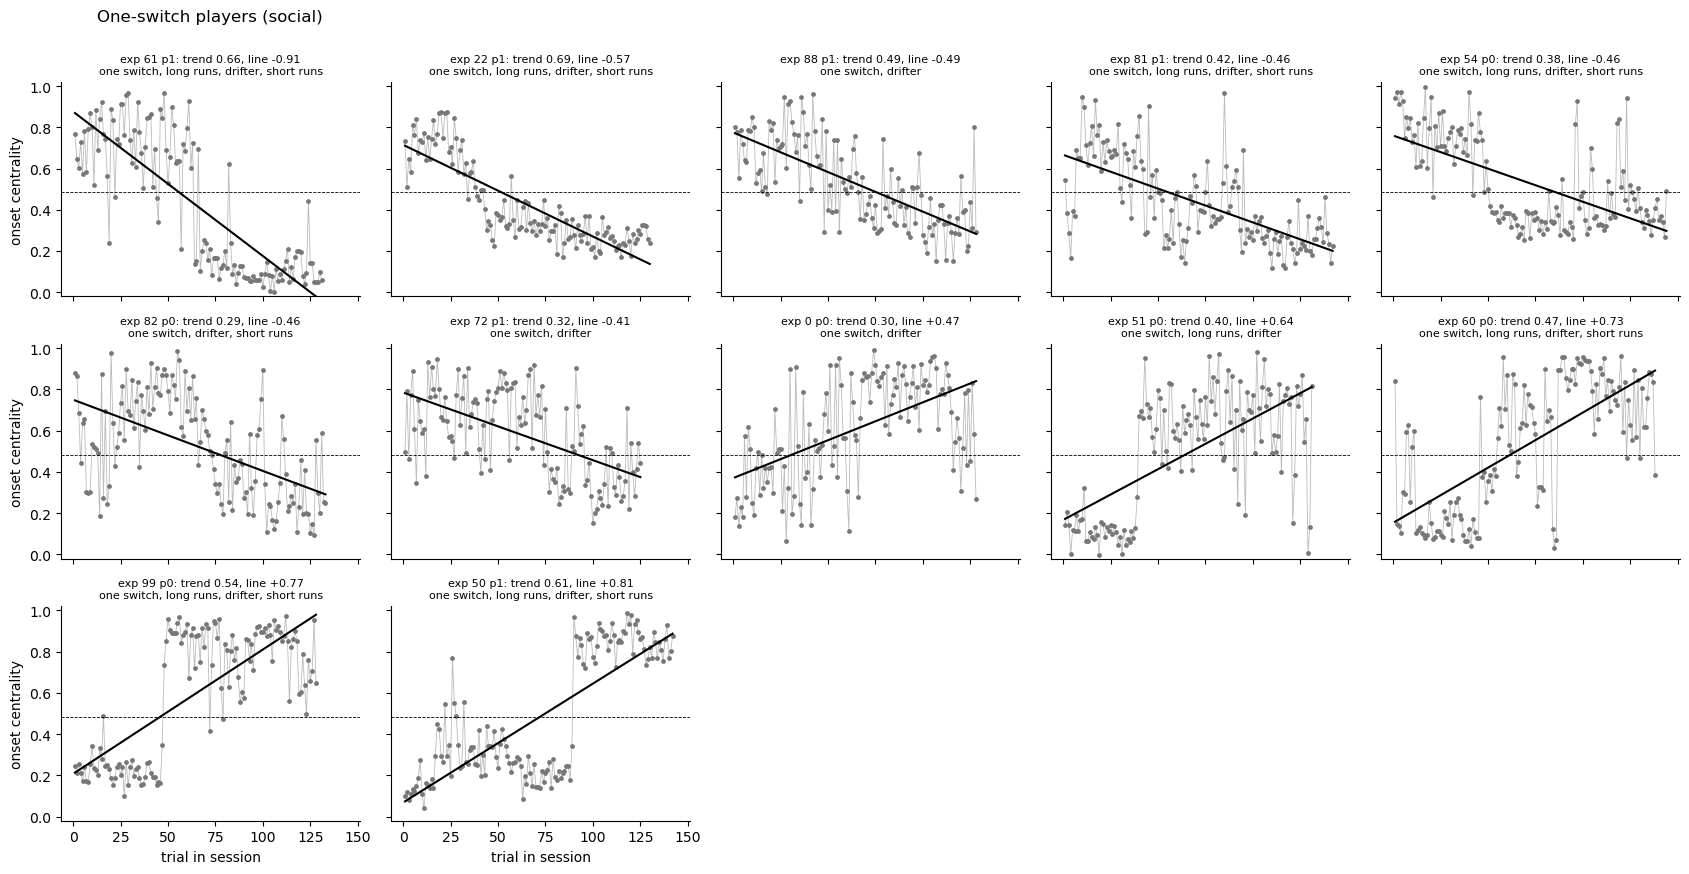

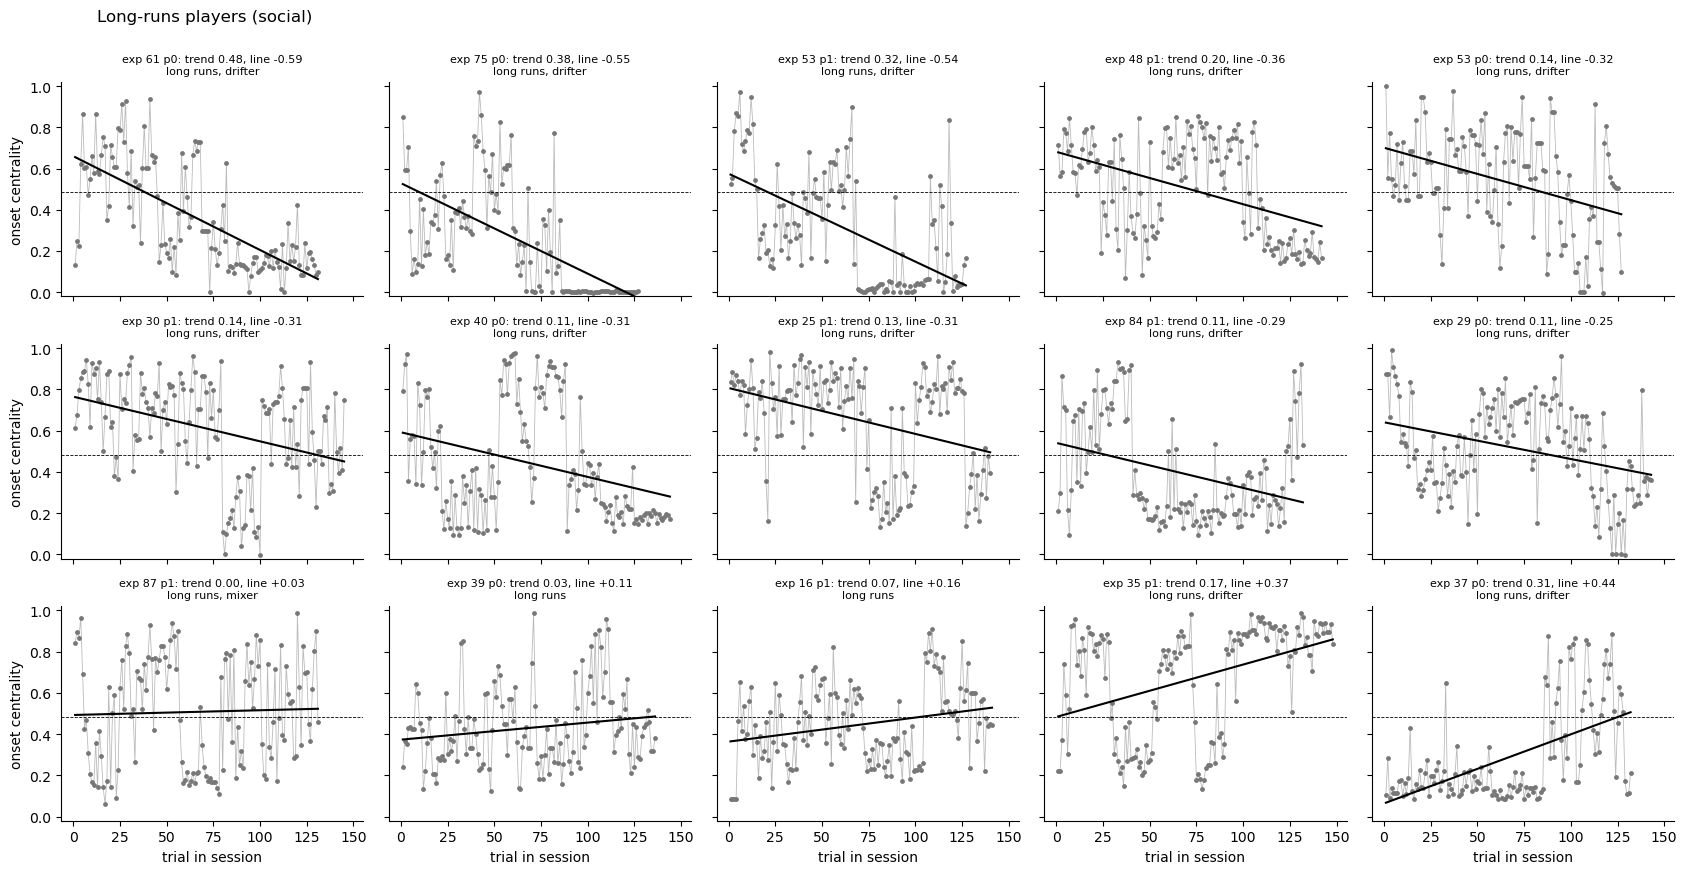

In [27]:
# plot every social one-switch player, then every social long-runs player
social_labelled = labelled[labelled['session_type'] == 'social']
plot_trend_players(social_labelled[social_labelled['label'] == 'one switch'], 'One-switch players (social)')
plot_trend_players(social_labelled[social_labelled['label'] == 'long runs'], 'Long-runs players (social)')

### Short runs and unclear (social)

All social intermediate players labelled short runs, then all labelled unclear, drawn as above. These are the players who fit none of the other labels.

**How to read the figures.** As above.

**Why it is plotted.** To see what the players left without a strategy label look like, and whether any of them clearly fits another label.

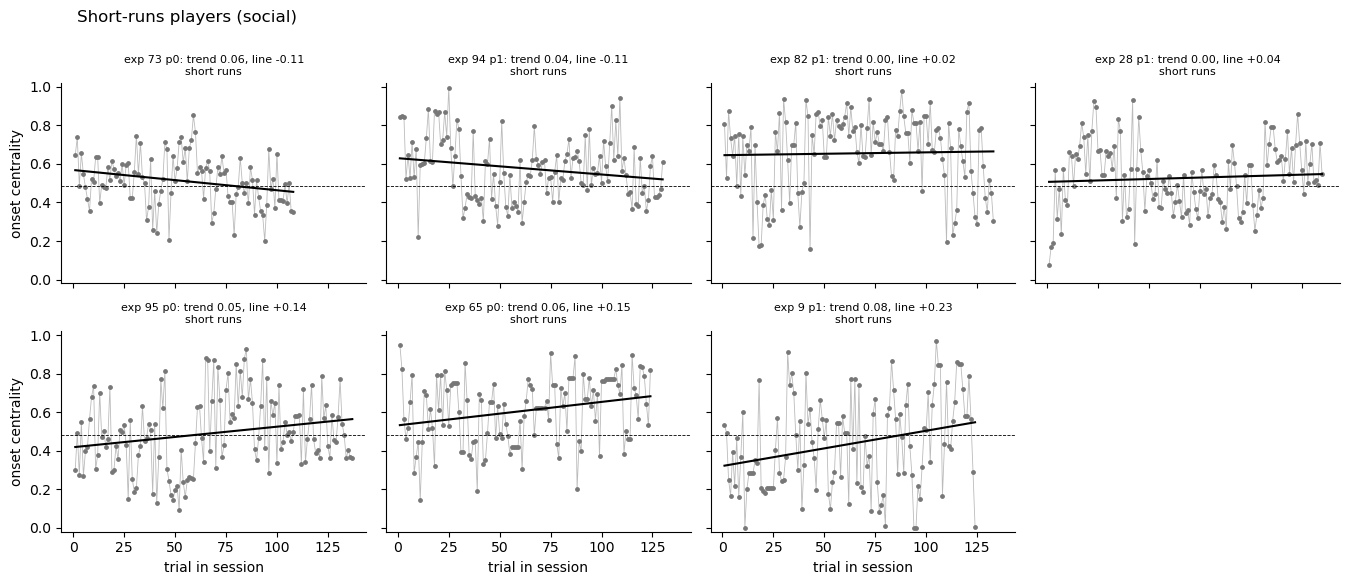

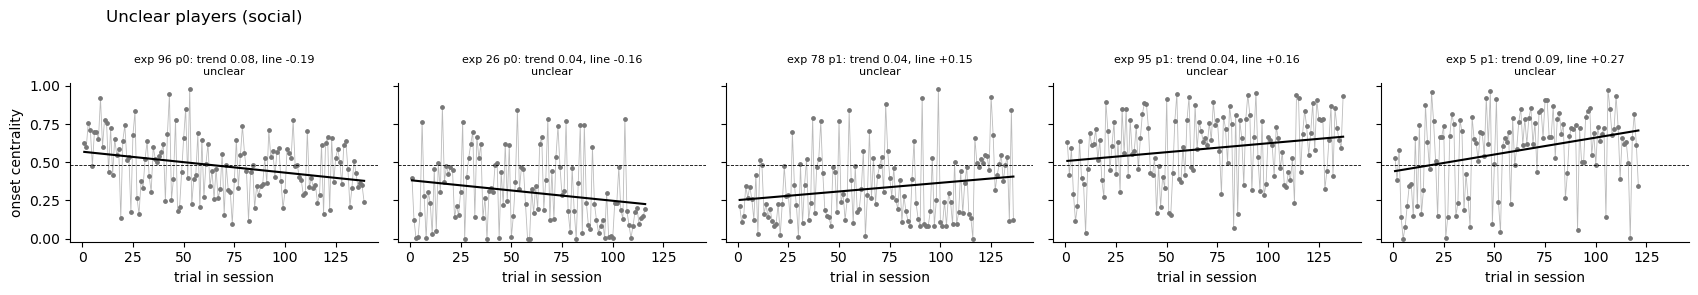

In [28]:
# plot every social short-runs player, then every social unclear player
plot_trend_players(social_labelled[social_labelled['label'] == 'short runs'], 'Short-runs players (social)', n_cols=4)
plot_trend_players(social_labelled[social_labelled['label'] == 'unclear'], 'Unclear players (social)')